# ADY201m — AI, DATA SCIENCE WITH PYTHON & SQL
## REPORT 2 — ONGOING ASSESSMENT 2
**Nội dung:** EDA, chuẩn bị đặc trưng, xây dựng và đánh giá mô hình.

**Đề tài:** Phân loại nhãn tiền tiểu đường/tiểu đường ở người tham gia BRFSS2015 từ 30–59 tuổi.
**Lớp:** AI2104 · **Nhóm:** 6.

| Thành viên | Mã sinh viên |Phần trăm đóng góp|
|---|---|---|
| Trần Tuấn Hiệp | HE211144 |40%|
| Nguyễn Thế Hải | HE211655 |30%|
| Trần Công Du | HE211007 |30%|

**Phạm vi:** Người tham gia 30–59 tuổi, bất kể việc làm. Loại hồ sơ chỉ tiểu đường khi mang thai trước gộp nhãn: lớp 0 = DIABETE3=3; lớp 1 = DIABETE3=1/4. Mục đích học thuật, không dự đoán phát bệnh tương lai.

**Đầu vào:** Các tệp dùng cho Ongoing 2 nằm trong `on_going2/Ongoing2_5_file_dau_vao/`. Bản chính có 116.662 dòng × 22 cột (21 feature + nhãn), giữ duplicate. Bản đối chiếu không duplicate có 102.826 dòng. Không làm sạch hay đổi nhãn lần nữa.

**Thiết kế Phần 3:** 32 cấu hình có trọng số: bốn bộ feature 21/25/13/10 × hai bản giữ/bỏ duplicate × bốn mô hình. Kèm mốc baseline đa số và bảng kết quả mô hình cũ của dự án; không chạy thêm đối chứng mô hình không trọng số.

**Kết quả thực thi:** Đã lưu output EDA, preprocessing, 32 cấu hình có trọng số, baseline lịch sử. Dự đoán, model và kiểm tra chỉ số nằm trong .runtime/weighted_32_results/.


## GRADING RUBRIC

*(This section is reserved for the instructor to grade and evaluate student work)*

| Criteria | Assessment Content | Max Score | Score Achieved | Lecturer's Feedback |
| :--- | :--- | :---: | :---: | :--- |
| **1. Exploratory Data Analysis (EDA)** | Univariate, bivariate & multivariate analysis, visualization, and meaningful business insights. | **3.0 pts** | | |
| **2. Feature Engineering & Preparation** | Proper categorical encoding, feature scaling, feature selection/creation, and train-test split. | **3.0 pts** | | |
| **3. Model Building & Evaluation** | Implementation of baseline & advanced models, performance metric evaluation, and model comparison. | **3.0 pts** | | |
| **4. Discussion & Conclusion** | Clear business interpretation of results, actionable recommendations, and next steps. | **1.0 pt** | | |
| **TOTAL SCORE** | **Overall evaluation of Report 2 execution** | **10.0 pts** | | |

---

### Chuẩn bị chạy notebook

Notebook đọc hai CSV, metadata và manifest từ `on_going2/Ongoing2_5_file_dau_vao/`. Cần pandas, numpy, scipy, matplotlib, seaborn, scikit-learn, xgboost, joblib, threadpoolctl và IPython.

Chạy từ trên xuống. Tạo hoặc kiểm tra manifest theo hash dữ liệu, cố định seed 42; EDA chỉ dùng Train. Phần 3 chỉ dùng train/test từ manifest, không sử dụng các fold CV đã lưu để huấn luyện mô hình. Test được giữ riêng trong lần chạy này, nhưng vẫn là holdout nội bộ từ cùng nguồn CDC2015, không phải bộ xác nhận ngoài. Tỷ lệ mô tả mẫu, chưa dùng trọng số khảo sát.


**Phân công công cụ:** SQLite thực hiện lọc, đếm, gom nhóm, tạo bản loại trùng, lập bảng và xếp hạng. pandas chỉ đọc kết quả truy vấn để hiển thị hoặc truyền sang thư viện tính toán/vẽ. NumPy/scipy/scikit-learn thực hiện tương quan, VIF, kiểm định, preprocessing và huấn luyện. Nhóm giữ nguồn và tạo view loại trùng bằng MIN(row_id) trên đủ 22 cột.

**Quy ước màu:** so sánh hai nhóm dùng cam cho nhóm 0 và tím cho nhóm 1. Các biểu đồ một chuỗi thống kê, gồm VIF/ANOVA/Chi-square, dùng xanh nước biển. Heatmap tỷ lệ dùng dải cam–đỏ; heatmap tương quan dùng cam–trắng–đỏ cho hệ số âm–0–dương.

**Bố cục repo:** chỉ cần notebook và folder 5 file input. Mã hỗ trợ và bảng baseline cũ được nhúng trong cell khởi tạo; khi chạy sẽ tạo `.runtime/` để lưu script, bảng, hình và model. Thư mục này không đưa lên GitHub. Các output trong notebook đã được lưu sẵn.

**Thư viện:** cần thêm imbalanced-learn và sklearn-compat cho NearMiss/SMOTENC. Có thể cài bằng `%pip install pandas numpy scipy matplotlib seaborn scikit-learn xgboost joblib threadpoolctl imbalanced-learn sklearn-compat`. Chạy cell SQL/EDA không yêu cầu chạy lại cell huấn luyện. Các lượt fit kiểm tra và tái dùng kết quả đã xác minh khi có cache; một clone mới chạy toàn bộ sẽ huấn luyện lại các cấu hình.


In [1]:
from pathlib import Path
import json, hashlib, csv, sqlite3, math
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "final_da_chinh_sua.ipynb").is_file():
    candidate = NOTEBOOK_DIR / "on_going2"
    assert (candidate / "final_da_chinh_sua.ipynb").is_file(), "Chạy từ thư mục dự án hoặc on_going2."
    NOTEBOOK_DIR = candidate
PROJECT_ROOT = NOTEBOOK_DIR.parent
INPUT_BASE = NOTEBOOK_DIR / "Ongoing2_5_file_dau_vao"
BASE = NOTEBOOK_DIR / ".runtime"
BASE.mkdir(exist_ok=True)

# Embedded support code and historical tables: a clean clone needs no sidecar scripts.
# Runtime files are local generated artifacts, not additional project input files.
EMBEDDED_SUPPORT_FILES = {
    "candidate25_tests.py": "\"\"\"Train-only exploratory assessment of the 21 original and four derived features.\"\"\"\nfrom pathlib import Path\nimport json\nimport sqlite3\nimport numpy as np\nimport pandas as pd\nfrom scipy import stats\nimport matplotlib.pyplot as plt\nimport seaborn as sns\n\n\ndef run_candidate25(db, features, target, base):\n    out = Path(base) / \"candidate25_results\"\n    out.mkdir(exist_ok=True)\n    definitions = {\n        \"BPCholState\": \"2*HighBP+HighChol; nominal: 0=neither, 1=cholesterol only, 2=BP only, 3=both\",\n        \"AgeBMI\": \"(Age*5+17)*BMI; midpoint age 32,37,42,47,52,57 (approximation)\",\n        \"LowEducationLowIncome\": \"Education<=3 AND Income<=3; below high-school graduation AND household income<20000 USD/year\",\n        \"PoorHealthDiffWalk\": \"GenHlth>=4 AND DiffWalk=1; Fair/Poor self-rated health AND difficulty walking/climbing stairs\",\n    }\n    db.execute(\"DROP TABLE IF EXISTS candidate25_train\")\n    original = \",\".join('\"' + c + '\"' for c in [target] + features)\n    db.execute(f\"\"\"CREATE TEMP TABLE candidate25_train AS\n        SELECT row_id, {original},\n               2*HighBP+HighChol AS BPCholState,\n               (Age*5+17)*BMI AS AgeBMI,\n               (Education<=3 AND Income<=3) AS LowEducationLowIncome,\n               (GenHlth>=4 AND DiffWalk=1) AS PoorHealthDiffWalk\n        FROM train_data\"\"\")\n    data = pd.read_sql_query(\"SELECT * FROM candidate25_train ORDER BY row_id\", db)\n    names = features + list(definitions)\n    y = data[target].to_numpy(dtype=int)\n    assert len(names) == 25 and len(data) == 93329 and y.sum() == 10192\n    assert not data[names].isna().any().any()\n    binary = [c for c in names if c not in [\"BMI\", \"MentHlth\", \"PhysHlth\", \"Age\", \"Education\", \"Income\", \"GenHlth\", \"AgeBMI\", \"BPCholState\"]]\n    data[binary + [target]] = data[binary + [target]].astype(bool)\n    data.to_csv(out / \"candidate25_train.csv\", index=False)\n    numeric = [\"BMI\", \"MentHlth\", \"PhysHlth\", \"AgeBMI\"]\n    correlation_names = [c for c in names if c != \"BPCholState\"]\n    pearson_matrix = data[correlation_names].astype(float).corr(method=\"pearson\")\n    spearman_matrix = data[correlation_names].astype(float).corr(method=\"spearman\")\n    pearson_matrix.to_csv(out / \"pearson_between_features.csv\")\n    spearman_matrix.to_csv(out / \"spearman_between_features.csv\")\n\n    # Quantile bins for continuous/count variables are defined using Train only.\n    # This permits contingency tests, with interpretation tied to this binning.\n    categories = {}\n    bin_edges = {}\n    for c in names:\n        if c in numeric:\n            binned, edges = pd.qcut(data[c], q=5, duplicates=\"drop\", retbins=True)\n            categories[c] = binned.cat.codes.to_numpy()\n            bin_edges[c] = edges.tolist()\n        else:\n            categories[c] = data[c].astype(int).to_numpy()\n\n    def contingency(a, b):\n        _, ai = np.unique(a, return_inverse=True)\n        _, bi = np.unique(b, return_inverse=True)\n        counts = np.zeros((ai.max()+1, bi.max()+1), dtype=int)\n        np.add.at(counts, (ai, bi), 1)\n        chi, p, dof, expected = stats.chi2_contingency(counts, correction=False)\n        v = np.sqrt(chi / (counts.sum() * min(counts.shape[0]-1, counts.shape[1]-1)))\n        return chi, p, dof, v, float((expected < 5).mean())\n\n    pair_rows = []\n    for i, a in enumerate(names):\n        for b in names[i+1:]:\n            chi, p, dof, v, small = contingency(categories[a], categories[b])\n            pair_rows.append(dict(feature_a=a, feature_b=b, cramers_v=v,\n                                  chi2_p=p, expected_lt5_fraction=small))\n    pairs = pd.DataFrame(pair_rows)\n    pairs.to_csv(out / \"pairwise_categorical_associations.csv\", index=False)\n\n    # Use three dummy columns for the nominal four-state feature. Including its\n    # parents creates exact linear dependencies; report infinity, never hide it\n    # behind a pseudo-inverse of the correlation matrix.\n    x = data[correlation_names].astype(float)\n    dummies = pd.get_dummies(data[\"BPCholState\"], prefix=\"BPCholState\", drop_first=True, dtype=float)\n    expanded = pd.concat([x, dummies], axis=1)\n    z = (expanded.to_numpy() - expanded.mean().to_numpy()) / expanded.std(ddof=0).to_numpy()\n    vif_rows = []\n    for j, col in enumerate(expanded.columns):\n        residual = z[:, j] - np.delete(z, j, axis=1) @ np.linalg.lstsq(np.delete(z, j, axis=1), z[:, j], rcond=None)[0]\n        remaining = float(residual @ residual / (z[:, j] @ z[:, j]))\n        value = np.inf if remaining < 1e-12 else 1 / remaining\n        vif_rows.append(dict(encoded_feature=col, Feature=\"BPCholState\" if col.startswith(\"BPCholState_\") else col, VIF=value))\n    vif_expanded = pd.DataFrame(vif_rows)\n    vif_expanded.to_csv(out / \"vif_encoded.csv\", index=False)\n    vif = vif_expanded.groupby(\"Feature\")[\"VIF\"].max()\n    rows = []\n    for c in names:\n        result = dict(Feature=c, kind=\"derived\" if c in definitions else \"original\",\n                      Pearson=np.nan, Pearson_p=np.nan, Spearman=np.nan, Spearman_p=np.nan)\n        if c != \"BPCholState\":\n            result[\"Pearson\"], result[\"Pearson_p\"] = stats.pearsonr(data[c].astype(float), y)\n            result[\"Spearman\"], result[\"Spearman_p\"] = stats.spearmanr(data[c].astype(float), y)\n        chi, p, dof, v, small = contingency(categories[c], y)\n        result.update(Chi2=chi, Chi2_p=p, Chi2_df=dof, CramersV=v,\n                      expected_lt5_fraction=small, VIF=vif[c],\n                      Welch_F=np.nan, Welch_p=np.nan, Cohen_d=np.nan)\n        if c in numeric:\n            a = data.loc[y == 1, c].to_numpy(dtype=float)\n            b = data.loc[y == 0, c].to_numpy(dtype=float)\n            t, p_w = stats.ttest_ind(a, b, equal_var=False)\n            pooled = np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))\n            result.update(Welch_F=t*t, Welch_p=p_w, Cohen_d=(a.mean()-b.mean())/pooled)\n        peers = pairs.loc[(pairs.feature_a == c) | (pairs.feature_b == c)].sort_values(\"cramers_v\", ascending=False)\n        peer = peers.iloc[0]\n        result.update(strongest_peer=peer.feature_b if peer.feature_a == c else peer.feature_a,\n                      strongest_peer_CramersV=peer.cramers_v)\n        rows.append(result)\n    summary = pd.DataFrame(rows)\n    for col in [\"Pearson_p\", \"Spearman_p\", \"Chi2_p\", \"Welch_p\"]:\n        mask = summary[col].notna()\n        summary.loc[mask, col+\"_BH\"] = stats.false_discovery_control(summary.loc[mask, col], method=\"bh\")\n    summary.to_csv(out / \"summary_25.csv\", index=False)\n    groups = []\n    for c in definitions:\n        expr = f'\"{c}\"' if c != \"AgeBMI\" else 'CAST((AgeBMI-1)/500 AS INTEGER)*500'\n        groups.append(pd.read_sql_query(f\"SELECT '{c}' AS Feature, {expr} AS level, COUNT(*) AS n, SUM({target}) AS positives, 100.0*AVG({target}) AS positive_percent FROM candidate25_train GROUP BY {expr}\", db))\n    pd.concat(groups).to_csv(out / \"derived_feature_groups.csv\", index=False)\n    protocol = dict(n_train=len(data), n_positive=int(y.sum()), feature_count=25, features=names,\n                    definitions=definitions, bin_edges=bin_edges,\n                    vif_encoded_columns=list(expanded.columns), vif_rank=int(np.linalg.matrix_rank(z)),\n                    notes=[\"Exploratory Train-only tests; feature definitions informed by EDA on the same Train.\",\n                           \"No model training or automatic feature selection; original files and split unchanged.\",\n                           \"Unweighted survey sample with duplicate profiles: inferential p-values do not account for survey design or profile dependence.\",\n                           \"BH applied separately within each target-test family; pairwise associations are descriptive.\",\n                           \"Pearson/Spearman for BPCholState omitted because category codes are nominal.\",\n                           \"Cramers V involving numeric variables depends on Train quantile bins; no causal interpretation.\",\n                           \"P-values displayed as zero may underflow floating-point precision, not indicate an exact zero probability.\"])\n    (out / \"protocol.json\").write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding=\"utf-8\")\n    fig, ax = plt.subplots(figsize=(16, 13))\n    sns.heatmap(spearman_matrix, mask=np.triu(np.ones(spearman_matrix.shape, dtype=bool)),\n                cmap=\"RdBu_r\", center=0, vmin=-1, vmax=1, annot=True, fmt=\".2f\",\n                annot_kws={\"size\": 6}, ax=ax)\n    ax.set_title(\"Spearman giữa 24 biến số/nhị phân/thứ bậc — BPCholState dùng Cramér's V riêng\")\n    fig.tight_layout()\n    fig.savefig(out / \"spearman_features.png\", dpi=120, bbox_inches=\"tight\")\n    plt.close(fig)\n    return summary, pairs, out\n",
    "train_weighted32.py": "\"\"\"Bounded 32-fit study; notebook provides SQLite data and locked feature sets.\"\"\"\nfrom pathlib import Path\nimport hashlib\nimport json\nimport platform\nimport time\nimport warnings\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import clone\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.tree import DecisionTreeClassifier\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix\nfrom sklearn.exceptions import ConvergenceWarning\nfrom xgboost import XGBClassifier\nfrom threadpoolctl import threadpool_limits\nimport sklearn\nimport xgboost\n\n\ndef prepare(db, feature_sets, base, seed=42):\n    out = Path(base) / \"weighted_32_results\"\n    out.mkdir(exist_ok=True)\n    (out / \"models\").mkdir(exist_ok=True)\n    assert [len(v) for v in feature_sets.values()] == [21, 25, 13, 10]\n    db.execute(\"DROP VIEW IF EXISTS model25_data\")\n    db.execute(\"\"\"CREATE TEMP VIEW model25_data AS SELECT d.*,\n        2*HighBP+HighChol AS BPCholState, (Age*5+17)*BMI AS AgeBMI,\n        (Education<=3 AND Income<=3) AS LowEducationLowIncome,\n        (GenHlth>=4 AND DiffWalk=1) AS PoorHealthDiffWalk FROM clean_data d\"\"\")\n    names = feature_sets[\"expanded_25\"]\n    columns = \",\".join('d.\"'+c+'\"' for c in names)\n    def query(sql, args=()):\n        return pd.read_sql_query(sql, db, params=args)\n    test = query(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM model25_data d JOIN split_manifest s USING(row_id) WHERE s.split='test' ORDER BY row_id\")\n    common_ids = query(\"SELECT d.row_id FROM clean_dedup d JOIN split_manifest s USING(row_id) WHERE s.split='test'\").row_id\n    common = test.row_id.isin(common_ids).to_numpy()\n    assert len(test) == 23333 and common.sum() == 20568\n    train = {}\n    sizes = []\n    for dataset in [\"keep_duplicates\", \"no_duplicates\"]:\n        frame = query(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM model25_data d JOIN dataset_rows s USING(row_id) WHERE s.Dataset=? AND s.split='train' ORDER BY row_id\", (dataset,))\n        train[dataset] = frame\n        n1 = int(frame.Diabetes_binary.sum())\n        sizes.append(dict(Dataset=dataset, TrainRows=len(frame), TrainClass0=len(frame)-n1, TrainClass1=n1,\n                          BalancedWeight0=len(frame)/(2*(len(frame)-n1)), BalancedWeight1=len(frame)/(2*n1),\n                          NegativePositiveRatio=(len(frame)-n1)/n1))\n    weights = pd.DataFrame(sizes)\n    weights.to_csv(out / \"training_class_weights.csv\", index=False)\n    assert len(train[\"keep_duplicates\"]) == 93329 and len(train[\"no_duplicates\"]) == 82258\n    assert not set(test.row_id) & set(train[\"keep_duplicates\"].row_id)\n    groups_shared = db.execute(\"SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)\").fetchone()[0]\n    assert groups_shared == 0\n    manifest = query(\"SELECT s.*, CASE WHEN d.row_id IS NULL THEN 0 ELSE 1 END AS retained_no_duplicates FROM split_manifest s LEFT JOIN clean_dedup d USING(row_id) ORDER BY s.row_id\")\n    manifest.to_csv(out / \"run_manifest.csv\", index=False)\n    protocol = dict(feature_sets=feature_sets, expected_fits=32, seed=seed, threshold=0.5,\n                    nominal_encoding=\"BPCholState one-hot drop-first for all models; original ordinals one-hot only for LR\",\n                    deduplication_key=\"all 21 original predictors plus label; keep first row; before feature reduction\",\n                    split=\"original group manifest unchanged\", metrics=\"binary class 1; SQL confusion counts independently checked with sklearn\",\n                    historical_baseline=\"preserved notebook outputs; no historical unweighted model metrics available\",\n                    evaluation=\"native Test and common deduplicated Test; previously viewed Test, exploratory only\",\n                    selection=\"features informed by EDA on all Train; no feature selection from this run's Test metrics\",\n                    python=platform.python_version(), sklearn=sklearn.__version__, xgboost=xgboost.__version__)\n    protocol[\"manifest_sha256\"] = hashlib.sha256((out / \"run_manifest.csv\").read_bytes()).hexdigest()\n    (out / \"frozen_design.json\").write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding=\"utf-8\")\n    return dict(db=db, out=out, feature_sets=feature_sets, train=train, test=test, common=common, weights=weights, seed=seed, protocol=protocol)\n\n\ndef preprocessor(cols, linear):\n    numeric = [c for c in [\"BMI\", \"MentHlth\", \"PhysHlth\", \"AgeBMI\"] if c in cols]\n    domains = {\"Age\":list(range(3,9)), \"Education\":list(range(1,7)), \"Income\":list(range(1,9)), \"GenHlth\":list(range(1,6))}\n    ordinal = [c for c in domains if c in cols]\n    nominal = [\"BPCholState\"] if \"BPCholState\" in cols else []\n    transforms = []\n    if numeric:\n        transforms.append((\"numeric\", StandardScaler() if linear else \"passthrough\", numeric))\n    if ordinal:\n        encoder = OneHotEncoder(categories=[domains[c] for c in ordinal], drop=\"first\", sparse_output=False, handle_unknown=\"error\")\n        transforms.append((\"ordinal\", encoder if linear else \"passthrough\", ordinal))\n    if nominal:\n        transforms.append((\"nominal\", OneHotEncoder(categories=[[0,1,2,3]], drop=\"first\", sparse_output=False, handle_unknown=\"error\"), nominal))\n    binary = [c for c in cols if c not in numeric+ordinal+nominal]\n    if binary:\n        transforms.append((\"binary\", \"passthrough\", binary))\n    return ColumnTransformer(transforms, remainder=\"drop\")\n\n\ndef models(seed, ratio):\n    return [\n        (\"LogisticRegression\", True, LogisticRegression(C=1.0, solver=\"lbfgs\", max_iter=1500, random_state=seed, class_weight=\"balanced\")),\n        (\"DecisionTree\", False, DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=seed, class_weight=\"balanced\")),\n        (\"RandomForest\", False, RandomForestClassifier(n_estimators=100, max_depth=16, min_samples_leaf=20, n_jobs=4, random_state=seed, class_weight=\"balanced\")),\n        (\"XGBoost\", False, XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, n_jobs=4, random_state=seed, eval_metric=\"logloss\", scale_pos_weight=ratio)),\n    ]\n\n\ndef train32(ctx):\n    out, db = ctx[\"out\"], ctx[\"db\"]\n    db.execute(\"DROP TABLE IF EXISTS weighted32_predictions\")\n    db.execute(\"CREATE TABLE weighted32_predictions (Config TEXT, row_id INTEGER, predicted INTEGER, PRIMARY KEY(Config,row_id))\")\n    db.execute(\"DROP TABLE IF EXISTS weighted32_metrics\")\n    db.execute(\"\"\"CREATE TABLE weighted32_metrics (Config TEXT, FeatureSet TEXT, Features INTEGER,\n        Dataset TEXT, Model TEXT, TestView TEXT, TestRows INTEGER, TN INTEGER, FP INTEGER, FN INTEGER, TP INTEGER,\n        Accuracy REAL, Precision REAL, Recall REAL, F1 REAL, PRIMARY KEY(Config,TestView))\"\"\")\n    test = ctx[\"test\"]\n    y_test = test.Diabetes_binary.to_numpy(dtype=int)\n    predictions = pd.DataFrame(dict(row_id=test.row_id, Actual=y_test, in_common_test=ctx[\"common\"].astype(int)))\n    audit = []\n    for feature_set, cols in ctx[\"feature_sets\"].items():\n        for dataset, frame in ctx[\"train\"].items():\n            weight = ctx[\"weights\"].set_index(\"Dataset\").loc[dataset].to_dict()\n            for name, linear, model in models(ctx[\"seed\"], weight[\"NegativePositiveRatio\"]):\n                key = f\"{feature_set}__{dataset}__{name}__balanced\"\n                if (out / \"models\" / (key+\".joblib\")).exists():\n                    raise RuntimeError(f\"Refusing an accidental repeat fit: {key}\")\n                start = time.monotonic()\n                pipeline = Pipeline([(\"preprocess\", preprocessor(cols, linear)), (\"model\", model)])\n                x_train = frame[cols].copy()\n                x_test = test[cols].copy()\n                bool_cols = [c for c in cols if c not in [\"BMI\",\"MentHlth\",\"PhysHlth\",\"AgeBMI\",\"Age\",\"Education\",\"Income\",\"GenHlth\",\"BPCholState\"]]\n                x_train[bool_cols] = x_train[bool_cols].astype(bool)\n                x_test[bool_cols] = x_test[bool_cols].astype(bool)\n                with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):\n                    warnings.simplefilter(\"always\", ConvergenceWarning)\n                    pipeline.fit(x_train, frame.Diabetes_binary.to_numpy(dtype=int))\n                    probabilities = pipeline.predict_proba(x_test)[:,1]\n                    predicted = pipeline.predict(x_test).astype(int)\n                assert np.array_equal(predicted, (probabilities > 0.5).astype(int))\n                params = pipeline.named_steps[\"model\"].get_params()\n                if name == \"XGBoost\":\n                    actual_weight = float(json.loads(pipeline.named_steps[\"model\"].get_booster().save_config())[\"learner\"][\"objective\"][\"reg_loss_param\"][\"scale_pos_weight\"])\n                    assert np.isclose(actual_weight, weight[\"NegativePositiveRatio\"])\n                else:\n                    assert params[\"class_weight\"] == \"balanced\"\n                joblib.dump(pipeline, out / \"models\" / (key+\".joblib\"))\n                np.savez_compressed(out / (key+\"_predictions.npz\"), row_id=test.row_id.to_numpy(), probability=probabilities, predicted=predicted)\n                predictions[key] = predicted\n                db.executemany(\"INSERT INTO weighted32_predictions VALUES (?,?,?)\", ((key,int(i),int(p)) for i,p in zip(test.row_id,predicted)))\n                for view in [\"native\", \"common\"]:\n                    eval_dataset = dataset if view == \"native\" else \"no_duplicates\"\n                    tn, fp, fn, tp, n = db.execute(\"\"\"SELECT\n                        SUM(d.Diabetes_binary=0 AND p.predicted=0), SUM(d.Diabetes_binary=0 AND p.predicted=1),\n                        SUM(d.Diabetes_binary=1 AND p.predicted=0), SUM(d.Diabetes_binary=1 AND p.predicted=1), COUNT(*)\n                        FROM weighted32_predictions p JOIN clean_data d USING(row_id) JOIN dataset_rows r USING(row_id)\n                        WHERE p.Config=? AND r.Dataset=? AND r.split='test'\"\"\",(key,eval_dataset)).fetchone()\n                    metrics = [(tn+tp)/n, tp/(tp+fp) if tp+fp else 0, tp/(tp+fn), 2*tp/(2*tp+fp+fn)]\n                    mask = ctx[\"common\"] if eval_dataset == \"no_duplicates\" else np.ones(len(test),dtype=bool)\n                    checked = [accuracy_score(y_test[mask],predicted[mask]),precision_score(y_test[mask],predicted[mask],zero_division=0),recall_score(y_test[mask],predicted[mask]),f1_score(y_test[mask],predicted[mask])]\n                    assert np.allclose(metrics, checked, atol=1e-14)\n                    assert np.array_equal(confusion_matrix(y_test[mask],predicted[mask],labels=[0,1]),[[tn,fp],[fn,tp]])\n                    db.execute(\"INSERT INTO weighted32_metrics VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)\", (key,feature_set,len(cols),dataset,name,view,n,tn,fp,fn,tp,*metrics))\n                audit.append(dict(Config=key, TrainRows=len(frame), EncodedColumns=len(pipeline.named_steps[\"preprocess\"].get_feature_names_out()),\n                                  weights=weight, model_parameters=params, seconds=time.monotonic()-start,\n                                  warnings=[str(w.message) for w in caught]))\n                db.commit()\n                results = pd.read_sql_query(\"SELECT * FROM weighted32_metrics ORDER BY Config,TestView\",db)\n                results.to_csv(out / \"all_metrics.csv\",index=False)\n                predictions.to_csv(out / \"all_test_predictions.csv\",index=False)\n                (out / \"fit_audit.json\").write_text(json.dumps(audit,ensure_ascii=False,indent=2,default=str),encoding=\"utf-8\")\n                (out / \"status.json\").write_text(json.dumps(dict(status=\"running\",finished=len(audit),expected=32,last=key),indent=2),encoding=\"utf-8\")\n                print(f\"[{len(audit)}/32] {key} ({time.monotonic()-start:.1f}s)\",flush=True)\n    assert len(audit) == 32 and len(results) == 64\n    for view in [\"native\", \"common\"]:\n        results[results.TestView==view].to_csv(out / (view+\"_test_metrics.csv\"),index=False)\n    (out / \"status.json\").write_text(json.dumps(dict(status=\"complete\",finished=32,expected=32,verified=True),indent=2),encoding=\"utf-8\")\n    ctx.update(results=results, audit=audit)\n    return results\n\n\ndef verify_saved(ctx):\n    out = ctx[\"out\"]\n    saved = pd.read_csv(out / \"all_test_predictions.csv\")\n    assert len(saved) == 23333\n    metrics = pd.read_csv(out / \"all_metrics.csv\")\n    assert metrics.Config.nunique()==32 and len(list((out/\"models\").glob(\"*.joblib\")))==32\n    for r in metrics.to_dict(\"records\"):\n        mask = saved.in_common_test.eq(1) if r[\"TestView\"]==\"common\" or r[\"Dataset\"]==\"no_duplicates\" else np.ones(len(saved),dtype=bool)\n        a,p = saved.loc[mask,\"Actual\"], saved.loc[mask,r[\"Config\"]]\n        for name,val in zip([\"Accuracy\",\"Precision\",\"Recall\",\"F1\"],[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]):\n            assert np.isclose(r[name],val,atol=1e-14)\n    report = dict(status=\"passed\",configurations=32,metric_rows=64,test_rows=23333,common_test_rows=20568,\n                  saved_predictions_verified=True,model_files=32)\n    (out/\"verification.json\").write_text(json.dumps(report,indent=2),encoding=\"utf-8\")\n    return report\n",
    "train_nearmiss10.py": "\"\"\"NearMiss-1 on Train only; eight bounded fits with the locked 10 features.\"\"\"\nfrom pathlib import Path\nimport sys\nimport json\nimport time\nimport hashlib\nimport warnings\nimport numpy as np\nimport pandas as pd\nimport joblib\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix\nfrom sklearn.exceptions import ConvergenceWarning\nfrom threadpoolctl import threadpool_limits\n\n\ndef run(db, base, seed=42):\n    base = Path(base)\n    sys.path.insert(0, str(base / \".deps\"))\n    sys.path.insert(0, str(base))\n    from imblearn.under_sampling import NearMiss\n    import imblearn\n    import train_weighted32 as wm\n    feature_sets = json.loads((base / \"candidate25_results/group_feature_selection.json\").read_text(encoding=\"utf-8\"))[\"feature_sets\"]\n    cols = feature_sets[\"replacement_10\"]\n    out = base / \"nearmiss_10_results\"\n    out.mkdir(exist_ok=True)\n    (out / \"models\").mkdir(exist_ok=True)\n    if list((out / \"models\").glob(\"*.joblib\")):\n        raise RuntimeError(\"NearMiss models already exist; refusing an accidental rerun.\")\n    protocol = dict(features=cols, seed=seed, expected_fits=8, algorithm=\"NearMiss-1\", n_neighbors=3,\n                    sampling_strategy=1.0, sampling_scope=\"Train only, separate for keep/no duplicates\",\n                    distance_preprocessing=\"StandardScaler for numeric; one-hot ordinal and nominal; bool 0/1; fit on original Train only\",\n                    distance_metric=\"Euclidean on encoded scaled matrix\",\n                    model_preprocessing=\"fresh fit on resampled Train; same transformations and model parameters as weighted32\",\n                    weighting=\"balanced after resampling; class weights=1, XGB scale_pos_weight=1\",\n                    reference=\"replacement_10 weighted32 saved metrics; comparison includes sampling and resulting weight changes\",\n                    threshold=0.5, imbalanced_learn=imblearn.__version__,\n                    limitation=\"Exploratory previously viewed Test; no threshold/feature/model choice from this run's Test\")\n    (out / \"frozen_design.json\").write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding=\"utf-8\")\n    db.execute(\"DROP VIEW IF EXISTS nearmiss_model_data\")\n    db.execute(\"\"\"CREATE TEMP VIEW nearmiss_model_data AS SELECT d.*,\n        2*HighBP+HighChol AS BPCholState, (Age*5+17)*BMI AS AgeBMI,\n        (Education<=3 AND Income<=3) AS LowEducationLowIncome,\n        (GenHlth>=4 AND DiffWalk=1) AS PoorHealthDiffWalk FROM clean_data d\"\"\")\n    def read(sql,params=()):\n        return pd.read_sql_query(sql,db,params=params)\n    columns=\",\".join('d.\"'+c+'\"' for c in cols)\n    test=read(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM nearmiss_model_data d JOIN split_manifest s USING(row_id) WHERE s.split='test' ORDER BY d.row_id\")\n    common_ids=read(\"SELECT d.row_id FROM clean_dedup d JOIN split_manifest s USING(row_id) WHERE s.split='test'\").row_id\n    common=test.row_id.isin(common_ids).to_numpy()\n    assert len(test)==23333 and common.sum()==20568\n    assert db.execute(\"SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)\").fetchone()[0]==0\n    bool_cols=[c for c in cols if c not in [\"GenHlth\",\"MentHlth\",\"PhysHlth\",\"AgeBMI\",\"BPCholState\"]]\n    test[bool_cols]=test[bool_cols].astype(bool)\n    test_hash=hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()\n    predictions=pd.DataFrame(dict(row_id=test.row_id,Actual=test.Diabetes_binary,in_common_test=common.astype(int)))\n    all_metrics=[]; counts=[]; audit=[]\n    for dataset in [\"keep_duplicates\",\"no_duplicates\"]:\n        frame=read(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM nearmiss_model_data d JOIN dataset_rows r USING(row_id) WHERE r.Dataset=? AND r.split='train' ORDER BY d.row_id\",(dataset,))\n        frame[bool_cols]=frame[bool_cols].astype(bool)\n        x=frame[cols]; y=frame.Diabetes_binary.to_numpy(dtype=int)\n        distance=wm.preprocessor(cols,True)\n        with threadpool_limits(limits=4):\n            encoded=distance.fit_transform(x)\n            sampler=NearMiss(version=1,n_neighbors=3,sampling_strategy=1.0,n_jobs=4)\n            _,resampled_y=sampler.fit_resample(encoded,y)\n        chosen=np.asarray(sampler.sample_indices_)\n        assert len(chosen)==len(np.unique(chosen))\n        assert np.array_equal(y[chosen],resampled_y)\n        assert set(np.flatnonzero(y==1))==set(chosen[y[chosen]==1])\n        assert not set(frame.row_id.iloc[chosen]) & set(test.row_id)\n        subset=frame.iloc[chosen]\n        n1=int(resampled_y.sum()); n0=len(resampled_y)-n1\n        assert n0==n1\n        count=dict(Dataset=dataset,OriginalRows=len(frame),OriginalClass0=int((y==0).sum()),OriginalClass1=int((y==1).sum()),\n                   ResampledRows=len(subset),ResampledClass0=n0,ResampledClass1=n1)\n        counts.append(count)\n        subset[[\"row_id\",\"Diabetes_binary\"]].to_csv(out/(dataset+\"_selected_train_ids.csv\"),index=False)\n        joblib.dump(distance,out/(dataset+\"_distance_preprocessor.joblib\"))\n        pd.DataFrame(counts).to_csv(out/\"train_counts.csv\",index=False)\n        print(f\"NearMiss {dataset}: {len(frame)} -> {len(subset)} ({n0}/{n1})\",flush=True)\n        for name,linear,model in wm.models(seed,n0/n1):\n            start=time.monotonic()\n            key=f\"replacement_10__{dataset}__{name}__nearmiss1\"\n            pipeline=Pipeline([(\"preprocess\",wm.preprocessor(cols,linear)),(\"model\",model)])\n            with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=4):\n                warnings.simplefilter(\"always\",ConvergenceWarning)\n                pipeline.fit(subset[cols],resampled_y)\n                predicted=pipeline.predict(test[cols]).astype(int)\n                probabilities=pipeline.predict_proba(test[cols])[:,1]\n            assert np.array_equal(predicted,(probabilities>0.5).astype(int))\n            joblib.dump(pipeline,out/\"models\"/(key+\".joblib\"))\n            np.savez_compressed(out/(key+\"_predictions.npz\"),row_id=test.row_id.to_numpy(),predicted=predicted,probability=probabilities)\n            predictions[key]=predicted\n            for view in [\"native\",\"common\"]:\n                mask=common if view==\"common\" or dataset==\"no_duplicates\" else np.ones(len(test),dtype=bool)\n                a=test.Diabetes_binary.to_numpy()[mask]; p=predicted[mask]\n                tn,fp,fn,tp=map(int,confusion_matrix(a,p,labels=[0,1]).ravel())\n                values=[(tn+tp)/len(a),tp/(tp+fp) if tp+fp else 0,tp/(tp+fn),2*tp/(2*tp+fp+fn)]\n                checked=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]\n                assert np.allclose(values,checked,atol=1e-14)\n                all_metrics.append(dict(Config=key,Dataset=dataset,Model=name,TestView=view,TestRows=len(a),\n                                        TN=tn,FP=fp,FN=fn,TP=tp,Accuracy=values[0],Precision=values[1],Recall=values[2],F1=values[3]))\n            audit.append(dict(Config=key,seconds=time.monotonic()-start,parameters=model.get_params(),\n                              weight_ratio=n0/n1,warnings=[str(w.message) for w in caught]))\n            pd.DataFrame(all_metrics).to_csv(out/\"all_metrics.csv\",index=False)\n            predictions.to_csv(out/\"all_test_predictions.csv\",index=False)\n            (out/\"fit_audit.json\").write_text(json.dumps(audit,ensure_ascii=False,indent=2,default=str),encoding=\"utf-8\")\n            print(f\"[{len(audit)}/8] {key}\",flush=True)\n    assert test_hash==hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()\n    metrics=pd.DataFrame(all_metrics)\n    baseline=pd.read_csv(base/\"weighted_32_results/all_metrics.csv\")\n    baseline=baseline[baseline.FeatureSet.eq(\"replacement_10\")]\n    comparison=metrics.merge(baseline[[\"Dataset\",\"Model\",\"TestView\",\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]],\n                             on=[\"Dataset\",\"Model\",\"TestView\"],suffixes=(\"_NearMiss\",\"_Weighted\"),validate=\"one_to_one\")\n    for metric in [\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]:\n        comparison[\"Delta_\"+metric]=comparison[metric+\"_NearMiss\"]-comparison[metric+\"_Weighted\"]\n    comparison.to_csv(out/\"comparison_with_weighted10.csv\",index=False)\n    saved=pd.read_csv(out/\"all_test_predictions.csv\")\n    for r in metrics.to_dict(\"records\"):\n        mask=saved.in_common_test.eq(1) if r[\"TestView\"]==\"common\" or r[\"Dataset\"]==\"no_duplicates\" else np.ones(len(saved),dtype=bool)\n        a,p=saved.loc[mask,\"Actual\"],saved.loc[mask,r[\"Config\"]]\n        checks=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]\n        assert np.allclose([r[k] for k in [\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]],checks,atol=1e-14)\n    assert len(audit)==8 and len(metrics)==16\n    (out/\"verification.json\").write_text(json.dumps(dict(status=\"passed\",fits=8,metric_rows=16,\n        saved_predictions_verified=True,test_unchanged=True,test_sha256=test_hash,\n        resampling_train_only=True,all_original_positives_retained=True),indent=2),encoding=\"utf-8\")\n    return metrics,comparison,pd.DataFrame(counts),out\n",
    "train_smotenc10.py": "\"\"\"SMOTENC on Train only; eight fits, preserving categorical and joint states.\"\"\"\nfrom pathlib import Path\nimport sys\nimport json\nimport time\nimport hashlib\nimport warnings\nimport numpy as np\nimport pandas as pd\nimport joblib\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix\nfrom sklearn.exceptions import ConvergenceWarning\nfrom threadpoolctl import threadpool_limits\n\n\ndef run(db, base, seed=42):\n    base = Path(base)\n    sys.path.insert(0, str(base / \".deps\"))\n    sys.path.insert(0, str(base))\n    from imblearn.over_sampling import SMOTENC\n    from sklearn.preprocessing import StandardScaler\n    import imblearn\n    import train_weighted32 as wm\n    feature_sets = json.loads((base / \"candidate25_results/group_feature_selection.json\").read_text(encoding=\"utf-8\"))[\"feature_sets\"]\n    cols = feature_sets[\"replacement_10\"]\n    out = base / \"smotenc_10_results\"\n    out.mkdir(exist_ok=True)\n    (out / \"models\").mkdir(exist_ok=True)\n    if list((out / \"models\").glob(\"*.joblib\")):\n        raise RuntimeError(\"SMOTENC models already exist; refusing an accidental rerun.\")\n    protocol = dict(features=cols, seed=seed, expected_fits=8, algorithm=\"SMOTENC\", k_neighbors=5,\n                    sampling_strategy=1.0, sampling_scope=\"Train only, separately for keep/no duplicates\",\n                    sampling_numeric=[\"AgeBMI\",\"MentHlth\",\"PhysHlth\"],\n                    sampling_categorical=\"bool/BPCholState plus joint GenHlth+PoorHealthDiffWalk category\",\n                    joint_encoding=\"2*GenHlth+PoorHealthDiffWalk; decode to preserve allowed combinations\",\n                    distance_preprocessing=\"StandardScaler numeric fit on original Train; SMOTENC internal categorical encoder\",\n                    model_preprocessing=\"fresh fit on resampled Train; model parameters unchanged from weighted32\",\n                    weighting=\"balanced on sampled Train=1; XGB scale_pos_weight=1\",\n                    threshold=0.5, imbalanced_learn=imblearn.__version__,\n                    synthetic_numeric=\"interpolated days may be fractional; no rounding\",\n                    limitation=\"Previously viewed Test; composite features are synthetic, not new real participants\")\n    (out / \"frozen_design.json\").write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding=\"utf-8\")\n    db.execute(\"DROP VIEW IF EXISTS smotenc_model_data\")\n    db.execute(\"\"\"CREATE TEMP VIEW smotenc_model_data AS SELECT d.*,\n        2*HighBP+HighChol AS BPCholState, (Age*5+17)*BMI AS AgeBMI,\n        (Education<=3 AND Income<=3) AS LowEducationLowIncome,\n        (GenHlth>=4 AND DiffWalk=1) AS PoorHealthDiffWalk FROM clean_data d\"\"\")\n    def read(sql,params=()):\n        return pd.read_sql_query(sql,db,params=params)\n    columns=\",\".join('d.\"'+c+'\"' for c in cols)\n    test=read(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM smotenc_model_data d JOIN split_manifest s USING(row_id) WHERE s.split='test' ORDER BY d.row_id\")\n    common_ids=read(\"SELECT d.row_id FROM clean_dedup d JOIN split_manifest s USING(row_id) WHERE s.split='test'\").row_id\n    common=test.row_id.isin(common_ids).to_numpy()\n    assert len(test)==23333 and common.sum()==20568\n    assert db.execute(\"SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)\").fetchone()[0]==0\n    bool_cols=[c for c in cols if c not in [\"GenHlth\",\"MentHlth\",\"PhysHlth\",\"AgeBMI\",\"BPCholState\"]]\n    test[bool_cols]=test[bool_cols].astype(bool)\n    test_hash=hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()\n    predictions=pd.DataFrame(dict(row_id=test.row_id,Actual=test.Diabetes_binary,in_common_test=common.astype(int)))\n    all_metrics=[]; counts=[]; audit=[]\n    for dataset in [\"keep_duplicates\",\"no_duplicates\"]:\n        frame=read(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM smotenc_model_data d JOIN dataset_rows r USING(row_id) WHERE r.Dataset=? AND r.split='train' ORDER BY d.row_id\",(dataset,))\n        frame[bool_cols]=frame[bool_cols].astype(bool)\n        x=frame[cols]; y=frame.Diabetes_binary.to_numpy(dtype=int)\n        numeric=[\"AgeBMI\",\"MentHlth\",\"PhysHlth\"]\n        categorical=[\"Stroke\",\"HeartDiseaseorAttack\",\"PhysActivity\",\"BPCholState\",\"LowEducationLowIncome\"]\n        scaler=StandardScaler()\n        scaled=pd.DataFrame(scaler.fit_transform(x[numeric]),columns=numeric)\n        for c in categorical:\n            scaled[c]=x[c].astype(int).to_numpy()\n        scaled[\"HealthWalkJoint\"]=(2*x.GenHlth+x.PoorHealthDiffWalk.astype(int)).to_numpy()\n        sampler=SMOTENC(categorical_features=list(range(3,9)),sampling_strategy=1.0,k_neighbors=5,random_state=seed)\n        with threadpool_limits(limits=4):\n            encoded,resampled_y=sampler.fit_resample(scaled,y)\n        encoded=pd.DataFrame(encoded,columns=scaled.columns)\n        subset=pd.DataFrame(scaler.inverse_transform(encoded[numeric]),columns=numeric)\n        for c in categorical:\n            subset[c]=encoded[c].astype(int)\n        joint=encoded[\"HealthWalkJoint\"].astype(int)\n        subset[\"GenHlth\"]=joint//2\n        subset[\"PoorHealthDiffWalk\"]=joint%2\n        subset=subset[cols]\n        subset[bool_cols]=subset[bool_cols].astype(bool)\n        assert np.allclose(subset.iloc[:len(frame)][cols].astype(float),x[cols].astype(float))\n        assert np.array_equal(resampled_y[:len(y)],y)\n        assert not set(frame.row_id) & set(test.row_id)\n        for c in categorical+[\"GenHlth\",\"PoorHealthDiffWalk\"]:\n            assert set(subset[c].astype(int)).issubset(set(x[c].astype(int)))\n        assert not ((subset.PoorHealthDiffWalk.astype(bool)) & (subset.GenHlth<4)).any()\n        for c in numeric:\n            assert subset[c].between(x[c].min()-1e-8,x[c].max()+1e-8).all()\n        n1=int(resampled_y.sum()); n0=len(resampled_y)-n1\n        assert n0==n1\n        count=dict(Dataset=dataset,OriginalRows=len(frame),OriginalClass0=int((y==0).sum()),OriginalClass1=int((y==1).sum()),\n                   ResampledRows=len(subset),ResampledClass0=n0,ResampledClass1=n1,SyntheticPositiveRows=len(subset)-len(frame))\n        counts.append(count)\n        sampled_export=subset.copy()\n        sampled_export[\"Diabetes_binary\"]=resampled_y\n        sampled_export[\"is_synthetic\"]=np.arange(len(subset))>=len(frame)\n        sampled_export.to_csv(out/(dataset+\"_resampled_train.csv\"),index=False)\n        frame[[\"row_id\",\"Diabetes_binary\"]].to_csv(out/(dataset+\"_original_train_ids.csv\"),index=False)\n        joblib.dump(scaler,out/(dataset+\"_sampling_scaler.joblib\"))\n        pd.DataFrame(counts).to_csv(out/\"train_counts.csv\",index=False)\n        print(f\"SMOTENC {dataset}: {len(frame)} -> {len(subset)} ({n0}/{n1})\",flush=True)\n        for name,linear,model in wm.models(seed,n0/n1):\n            start=time.monotonic()\n            key=f\"replacement_10__{dataset}__{name}__smotenc\"\n            pipeline=Pipeline([(\"preprocess\",wm.preprocessor(cols,linear)),(\"model\",model)])\n            with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=4):\n                warnings.simplefilter(\"always\",ConvergenceWarning)\n                pipeline.fit(subset[cols],resampled_y)\n                predicted=pipeline.predict(test[cols]).astype(int)\n                probabilities=pipeline.predict_proba(test[cols])[:,1]\n            assert np.array_equal(predicted,(probabilities>0.5).astype(int))\n            joblib.dump(pipeline,out/\"models\"/(key+\".joblib\"))\n            np.savez_compressed(out/(key+\"_predictions.npz\"),row_id=test.row_id.to_numpy(),predicted=predicted,probability=probabilities)\n            predictions[key]=predicted\n            for view in [\"native\",\"common\"]:\n                mask=common if view==\"common\" or dataset==\"no_duplicates\" else np.ones(len(test),dtype=bool)\n                a=test.Diabetes_binary.to_numpy()[mask]; p=predicted[mask]\n                tn,fp,fn,tp=map(int,confusion_matrix(a,p,labels=[0,1]).ravel())\n                values=[(tn+tp)/len(a),tp/(tp+fp) if tp+fp else 0,tp/(tp+fn),2*tp/(2*tp+fp+fn)]\n                checked=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]\n                assert np.allclose(values,checked,atol=1e-14)\n                all_metrics.append(dict(Config=key,Dataset=dataset,Model=name,TestView=view,TestRows=len(a),\n                                        TN=tn,FP=fp,FN=fn,TP=tp,Accuracy=values[0],Precision=values[1],Recall=values[2],F1=values[3]))\n            audit.append(dict(Config=key,seconds=time.monotonic()-start,parameters=model.get_params(),\n                              weight_ratio=n0/n1,warnings=[str(w.message) for w in caught]))\n            pd.DataFrame(all_metrics).to_csv(out/\"all_metrics.csv\",index=False)\n            predictions.to_csv(out/\"all_test_predictions.csv\",index=False)\n            (out/\"fit_audit.json\").write_text(json.dumps(audit,ensure_ascii=False,indent=2,default=str),encoding=\"utf-8\")\n            print(f\"[{len(audit)}/8] {key}\",flush=True)\n    assert test_hash==hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()\n    metrics=pd.DataFrame(all_metrics)\n    baseline=pd.read_csv(base/\"weighted_32_results/all_metrics.csv\")\n    baseline=baseline[baseline.FeatureSet.eq(\"replacement_10\")]\n    comparison=metrics.merge(baseline[[\"Dataset\",\"Model\",\"TestView\",\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]],\n                             on=[\"Dataset\",\"Model\",\"TestView\"],suffixes=(\"_SMOTENC\",\"_Weighted\"),validate=\"one_to_one\")\n    for metric in [\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]:\n        comparison[\"Delta_\"+metric]=comparison[metric+\"_SMOTENC\"]-comparison[metric+\"_Weighted\"]\n    comparison.to_csv(out/\"comparison_with_weighted10.csv\",index=False)\n    saved=pd.read_csv(out/\"all_test_predictions.csv\")\n    for r in metrics.to_dict(\"records\"):\n        mask=saved.in_common_test.eq(1) if r[\"TestView\"]==\"common\" or r[\"Dataset\"]==\"no_duplicates\" else np.ones(len(saved),dtype=bool)\n        a,p=saved.loc[mask,\"Actual\"],saved.loc[mask,r[\"Config\"]]\n        checks=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]\n        assert np.allclose([r[k] for k in [\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]],checks,atol=1e-14)\n    assert len(audit)==8 and len(metrics)==16\n    (out/\"verification.json\").write_text(json.dumps(dict(status=\"passed\",fits=8,metric_rows=16,\n        saved_predictions_verified=True,test_unchanged=True,test_sha256=test_hash,\n        resampling_train_only=True,all_original_rows_retained=True,categorical_domains_preserved=True,joint_health_walk_valid=True),indent=2),encoding=\"utf-8\")\n    return metrics,comparison,pd.DataFrame(counts),out\n",
    "compare_resampling_five_sets.py": "\"\"\"Complete the missing 80 fits for 5 sets x 3 methods x 2 datasets x 4 models.\"\"\"\nfrom pathlib import Path\nimport sys\nimport json\nimport hashlib\nimport time\nimport warnings\nimport numpy as np\nimport pandas as pd\nimport joblib\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import StandardScaler\nfrom sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix\nfrom sklearn.exceptions import ConvergenceWarning\nfrom threadpoolctl import threadpool_limits\n\n\ndef run(db,base,original,seed=42):\n    base=Path(base)\n    sys.path.insert(0,str(base/\".deps\"));sys.path.insert(0,str(base))\n    from imblearn.under_sampling import NearMiss\n    from imblearn.over_sampling import SMOTENC\n    import train_weighted32 as wm\n    out=base/\"comparison_10_13_16_18_21\"\n    out.mkdir(exist_ok=True);(out/\"models\").mkdir(exist_ok=True)\n    saved_sets=json.loads((base/\"candidate25_results/group_feature_selection.json\").read_text(encoding=\"utf-8\"))[\"feature_sets\"]\n    sets={\"replacement_10\":saved_sets[\"replacement_10\"],\"compact_13\":saved_sets[\"compact_13\"],\n          \"reduced_16\":[c for c in original if c not in [\"Fruits\",\"Veggies\",\"Sex\",\"CholCheck\",\"AnyHealthcare\"]],\n          \"reduced_18\":[c for c in original if c not in [\"Stroke\",\"Sex\",\"PhysHlth\"]],\"full_21\":original.copy()}\n    assert [len(v) for v in sets.values()]==[10,13,16,18,21]\n    protocol=dict(feature_sets=sets,seed=seed,expected_configurations=120,reused=40,new_fits=80,\n                  methods=[\"weighted\",\"NearMiss\",\"SMOTENC\"],threshold=0.5,\n                  sampling=\"Train only; separate keep/no duplicates; full original22-column dedup key\",\n                  nearmiss=\"version1,k3,ratio1.0,scaled numeric and one-hot categorical distance\",\n                  smotenc=\"k5,ratio1.0,scaled numeric; original ordinals/binary treated as categorical\",\n                  weighting=\"weighted: original Train counts; resampled methods: sampled counts balanced=1\",\n                  limitations=\"Previously viewed Test; exploratory; no Test-based tuning/promotion; sampling changes weights too\",\n                  reused10_smotenc=\"GenHlth+PoorHealthDiffWalk encoded jointly to preserve logical combinations\")\n    frozen=out/\"frozen_design.json\"\n    if frozen.exists():assert json.loads(frozen.read_text(encoding=\"utf-8\"))==protocol\n    else:frozen.write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding=\"utf-8\")\n    db.execute(\"DROP VIEW IF EXISTS comparison_model_data\")\n    db.execute(\"\"\"CREATE TEMP VIEW comparison_model_data AS SELECT d.*,\n        2*HighBP+HighChol AS BPCholState,(Age*5+17)*BMI AS AgeBMI,\n        (Education<=3 AND Income<=3) AS LowEducationLowIncome,\n        (GenHlth>=4 AND DiffWalk=1) AS PoorHealthDiffWalk FROM clean_data d\"\"\")\n    def read(sql,args=()):return pd.read_sql_query(sql,db,params=args)\n    columns=\",\".join('d.\"'+c+'\"' for c in saved_sets[\"expanded_25\"])\n    test=read(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM comparison_model_data d JOIN split_manifest s USING(row_id) WHERE s.split='test' ORDER BY d.row_id\")\n    common=test.row_id.isin(read(\"SELECT d.row_id FROM clean_dedup d JOIN split_manifest s USING(row_id) WHERE s.split='test'\").row_id).to_numpy()\n    assert len(test)==23333 and common.sum()==20568\n    assert db.execute(\"SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)\").fetchone()[0]==0\n    test_hash=hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()\n    frames={ds:read(f\"SELECT d.row_id,d.Diabetes_binary,{columns} FROM comparison_model_data d JOIN dataset_rows r USING(row_id) WHERE r.Dataset=? AND r.split='train' ORDER BY d.row_id\",(ds,)) for ds in [\"keep_duplicates\",\"no_duplicates\"]}\n    for f in frames.values():assert not set(f.row_id)&set(test.row_id)\n    # Reuse full precision saved metrics, never rounded notebook historical tables.\n    weighted=pd.read_csv(base/\"weighted_32_results/all_metrics.csv\")\n    weighted=weighted[weighted.FeatureSet.isin(sets)].copy();weighted[\"Method\"]=\"weighted\"\n    weighted[\"Source\"]=\"weighted_32_results/all_metrics.csv\"\n    reused=[weighted]\n    for method,folder in [(\"NearMiss\",\"nearmiss_10_results\"),(\"SMOTENC\",\"smotenc_10_results\")]:\n        f=pd.read_csv(base/folder/\"all_metrics.csv\")\n        f[\"FeatureSet\"]=\"replacement_10\";f[\"Features\"]=10;f[\"Method\"]=method;f[\"Source\"]=folder+\"/all_metrics.csv\";reused.append(f)\n    reused=pd.concat(reused,ignore_index=True)\n    assert reused.Config.nunique()==40 and len(reused)==80\n    reused.to_csv(out/\"reused_metrics.csv\",index=False)\n    new_file=out/\"new_metrics.csv\"\n    new_metrics=pd.read_csv(new_file).to_dict(\"records\") if new_file.exists() else []\n    audit_file=out/\"fit_audit.json\"\n    audit=json.loads(audit_file.read_text()) if audit_file.exists() else []\n    counts=[]\n    numeric_all=[\"BMI\",\"MentHlth\",\"PhysHlth\",\"AgeBMI\"]\n    categorical_all=[c for c in saved_sets[\"expanded_25\"] if c not in numeric_all]\n    for fs,cols in sets.items():\n        for method in [\"weighted\",\"NearMiss\",\"SMOTENC\"]:\n            if method==\"weighted\" and fs not in [\"reduced_16\",\"reduced_18\"]:continue\n            if method!=\"weighted\" and fs==\"replacement_10\":continue\n            for dataset,frame in frames.items():\n                x=frame[cols].copy();y=frame.Diabetes_binary.to_numpy(dtype=int)\n                bool_cols=[c for c in cols if c not in numeric_all+[\"Age\",\"Education\",\"Income\",\"GenHlth\",\"BPCholState\"]]\n                x[bool_cols]=x[bool_cols].astype(bool)\n                if method==\"weighted\":sample_x=x;sample_y=y\n                elif method==\"NearMiss\":\n                    distance=wm.preprocessor(cols,True)\n                    with threadpool_limits(limits=4):\n                        encoded=distance.fit_transform(x)\n                        sampler=NearMiss(version=1,n_neighbors=3,sampling_strategy=1.0,n_jobs=4)\n                        _,sample_y=sampler.fit_resample(encoded,y)\n                    ids=sampler.sample_indices_\n                    assert set(np.flatnonzero(y==1))==set(ids[y[ids]==1])\n                    sample_x=x.iloc[ids].reset_index(drop=True)\n                    frame.iloc[ids][[\"row_id\",\"Diabetes_binary\"]].to_csv(out/f\"{fs}__{dataset}__NearMiss_selected_ids.csv\",index=False)\n                    joblib.dump(distance,out/f\"{fs}__{dataset}__NearMiss_distance.joblib\")\n                else:\n                    numeric=[c for c in cols if c in numeric_all]\n                    categorical=[c for c in cols if c in categorical_all]\n                    scaler=StandardScaler()\n                    encoded=pd.DataFrame(scaler.fit_transform(x[numeric]),columns=numeric)\n                    for c in categorical:encoded[c]=x[c].astype(int).to_numpy()\n                    sampler=SMOTENC(categorical_features=list(range(len(numeric),len(cols))),k_neighbors=5,sampling_strategy=1.0,random_state=seed)\n                    with threadpool_limits(limits=4):resampled,sample_y=sampler.fit_resample(encoded,y)\n                    resampled=pd.DataFrame(resampled,columns=encoded.columns)\n                    sample_x=pd.DataFrame(scaler.inverse_transform(resampled[numeric]),columns=numeric)\n                    for c in categorical:\n                        sample_x[c]=resampled[c].astype(int)\n                        assert set(sample_x[c]).issubset(set(x[c].astype(int)))\n                    sample_x=sample_x[cols]\n                    assert np.allclose(sample_x.iloc[:len(x)].astype(float),x.astype(float))\n                    assert np.array_equal(sample_y[:len(y)],y)\n                    for c in numeric:assert sample_x[c].between(x[c].min()-1e-8,x[c].max()+1e-8).all()\n                    np.savez_compressed(out/f\"{fs}__{dataset}__SMOTENC_train.npz\",X=sample_x.to_numpy(dtype=float),y=sample_y,columns=np.array(cols),original_row_ids=frame.row_id.to_numpy())\n                    joblib.dump(scaler,out/f\"{fs}__{dataset}__SMOTENC_scaler.joblib\")\n                sample_x[bool_cols]=sample_x[bool_cols].astype(bool)\n                n0=int((sample_y==0).sum());n1=int((sample_y==1).sum())\n                if method!=\"weighted\":assert n0==n1\n                counts.append(dict(FeatureSet=fs,Dataset=dataset,Method=method,OriginalRows=len(x),OriginalClass0=int((y==0).sum()),OriginalClass1=int((y==1).sum()),SampledRows=len(sample_x),SampledClass0=n0,SampledClass1=n1))\n                pd.DataFrame(counts).to_csv(out/\"train_counts_new_arms.csv\",index=False)\n                print(f\"Prepared {fs}/{method}/{dataset}: {len(x)} -> {len(sample_x)}\",flush=True)\n                for name,linear,model in wm.models(seed,n0/n1):\n                    key=f\"{fs}__{dataset}__{name}__{method}\"\n                    if any(r[\"Config\"]==key for r in new_metrics):continue\n                    model_path=out/\"models\"/(key+\".joblib\")\n                    if model_path.exists():raise RuntimeError(f\"Partial model already exists: {key}\")\n                    start=time.monotonic()\n                    pipeline=Pipeline([(\"preprocess\",wm.preprocessor(cols,linear)),(\"model\",model)])\n                    xt=test[cols].copy();xt[bool_cols]=xt[bool_cols].astype(bool)\n                    with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=4):\n                        warnings.simplefilter(\"always\",ConvergenceWarning)\n                        pipeline.fit(sample_x,sample_y)\n                        predicted=pipeline.predict(xt).astype(int)\n                        probability=pipeline.predict_proba(xt)[:,1]\n                    assert np.array_equal(predicted,(probability>0.5).astype(int))\n                    joblib.dump(pipeline,model_path)\n                    np.savez_compressed(out/(key+\"_predictions.npz\"),row_id=test.row_id.to_numpy(),actual=test.Diabetes_binary.to_numpy(),common=common,predicted=predicted,probability=probability)\n                    for view in [\"native\",\"common\"]:\n                        mask=common if view==\"common\" or dataset==\"no_duplicates\" else np.ones(len(test),dtype=bool)\n                        a=test.Diabetes_binary.to_numpy()[mask];p=predicted[mask]\n                        tn,fp,fn,tp=map(int,confusion_matrix(a,p,labels=[0,1]).ravel())\n                        vals=[(tn+tp)/len(a),tp/(tp+fp) if tp+fp else 0,tp/(tp+fn),2*tp/(2*tp+fp+fn)]\n                        checks=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]\n                        assert np.allclose(vals,checks,atol=1e-14)\n                        new_metrics.append(dict(Config=key,FeatureSet=fs,Features=len(cols),Dataset=dataset,Method=method,Model=name,TestView=view,TestRows=len(a),TN=tn,FP=fp,FN=fn,TP=tp,Accuracy=vals[0],Precision=vals[1],Recall=vals[2],F1=vals[3],Source=\"comparison_10_13_16_18_21/new_metrics.csv\"))\n                    audit.append(dict(Config=key,seconds=time.monotonic()-start,TrainRows=len(sample_x),Class0=n0,Class1=n1,parameters=model.get_params(),warnings=[str(w.message) for w in caught]))\n                    pd.DataFrame(new_metrics).to_csv(new_file,index=False)\n                    audit_file.write_text(json.dumps(audit,ensure_ascii=False,indent=2,default=str),encoding=\"utf-8\")\n                    (out/\"status.json\").write_text(json.dumps(dict(status=\"running\",new_fits=len(audit),expected=80,last=key),indent=2),encoding=\"utf-8\")\n                    print(f\"[{len(audit)}/80] {key}\",flush=True)\n    assert len(audit)==80 and len(new_metrics)==160\n    assert test_hash==hashlib.sha256(test.to_csv(index=False).encode()).hexdigest()\n    combined=pd.concat([reused,pd.DataFrame(new_metrics)],ignore_index=True)\n    assert combined.Config.nunique()==120 and len(combined)==240\n    assert combined.groupby([\"FeatureSet\",\"Dataset\",\"Method\",\"Model\"]).size().eq(2).all()\n    combined.to_csv(out/\"all_metrics.csv\",index=False)\n    for view in [\"native\",\"common\"]:\n        subset=combined[combined.TestView==view]\n        subset.to_csv(out/(view+\"_metrics.csv\"),index=False)\n        wide=subset.pivot(index=[\"Features\",\"FeatureSet\",\"Dataset\",\"Model\"],columns=\"Method\",values=[\"Accuracy\",\"Precision\",\"Recall\",\"F1\"])\n        wide.columns=[f\"{metric}_{method}\" for metric,method in wide.columns]\n        wide=wide.reset_index()\n        for method in [\"NearMiss\",\"SMOTENC\"]:\n            wide[f\"Delta_F1_{method}\"]=wide[f\"F1_{method}\"]-wide.F1_weighted\n        wide.to_csv(out/(view+\"_comparison_wide.csv\"),index=False)\n    # Verify all 80 new models from saved predictions; reused studies already have verification reports.\n    for r in new_metrics:\n        z=np.load(out/(r[\"Config\"]+\"_predictions.npz\"))\n        mask=z[\"common\"] if r[\"TestView\"]==\"common\" or r[\"Dataset\"]==\"no_duplicates\" else np.ones(len(z[\"actual\"]),dtype=bool)\n        a,p=z[\"actual\"][mask],z[\"predicted\"][mask]\n        checks=[accuracy_score(a,p),precision_score(a,p,zero_division=0),recall_score(a,p),f1_score(a,p)]\n        assert np.allclose([r[c] for c in [\"Accuracy\",\"Precision\",\"Recall\",\"F1\"]],checks,atol=1e-14)\n    report=dict(status=\"passed\",configurations=120,metric_rows=240,new_fits=80,reused=40,\n                common_test_rows=20568,test_rows=23333,test_unchanged=True,new_saved_predictions_checked=True,\n                sampling_train_only=True,source_metrics_unrounded=True)\n    (out/\"verification.json\").write_text(json.dumps(report,indent=2),encoding=\"utf-8\")\n    (out/\"status.json\").write_text(json.dumps(dict(status=\"complete\",new_fits=80,reused=40),indent=2),encoding=\"utf-8\")\n    return combined,out\n",
    "confusion_priority144.py": "\"\"\"Select priorities among 120 current and 24 historical results, without fitting.\"\"\"\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nimport seaborn as sns\nfrom sklearn.metrics import confusion_matrix,precision_score,recall_score,f1_score\n\n\ndef run(base):\n    base=Path(base)\n    out=base/\"comparison_10_13_16_18_21\"/\"priority_confusion_144\"\n    out.mkdir(exist_ok=True)\n    current=pd.read_csv(base/\"comparison_10_13_16_18_21/common_metrics.csv\")\n    historical=pd.read_csv(base/\"historical_project_baseline/historical_common_metrics.csv\")\n    assert len(current)==120 and len(historical)==24\n    historical=historical.rename(columns={\"F1-score\":\"F1\"})\n    historical[\"FeatureSet\"]=\"historical_\"+historical.Features.astype(str)\n    historical[\"Method\"]=\"weighted_historical\"\n    historical[\"Config\"]=[f\"historical24__{r.Features}__{r.Dataset}__{r.Model}\" for r in historical.itertuples()]\n    historical[\"TestRows\"]=20568\n    historical[\"Source\"]=\"historical_project_baseline/historical_common_metrics.csv\"\n    historical[\"Study\"]=\"historical24_rounded4\"\n    current[\"Study\"]=\"current120_full_precision\"\n    columns=[\"Study\",\"Config\",\"Features\",\"FeatureSet\",\"Dataset\",\"Method\",\"Model\",\"TestRows\",\"Accuracy\",\"Precision\",\"Recall\",\"F1\",\"Source\"]\n    combined=pd.concat([current[columns],historical[columns]],ignore_index=True)\n    combined.to_csv(out/\"considered_144_results.csv\",index=False)\n    leader_rows=[]; matrices=[]; ids_reference=None\n    # A four-decimal historical score has at most ~0.00005 rounding error.\n    for metric,priority in [(\"Recall\",\"Recall cao nhất\"),(\"F1\",\"F1-score cao nhất\")]:\n        secondary=\"F1\" if metric==\"Recall\" else \"Recall\"\n        best=current.sort_values([metric,secondary,\"Config\"],ascending=[False,False,True]).iloc[0]\n        historical_upper=float(historical[metric].max())+0.00005\n        assert best[metric]>historical_upper, \"Historical rounded score might lead; need exact historical predictions before drawing its matrix.\"\n        file=base/Path(best.Source).parent/(best.Config+\"_predictions.npz\")\n        saved=np.load(file)\n        mask=saved[\"common\"].astype(bool)\n        ids=saved[\"row_id\"][mask]\n        actual=saved[\"actual\"][mask]\n        predicted=saved[\"predicted\"][mask]\n        assert len(actual)==20568 and int(actual.sum())==2539\n        if ids_reference is None:ids_reference=ids\n        else:assert np.array_equal(ids_reference,ids)\n        matrix=confusion_matrix(actual,predicted,labels=[0,1])\n        assert np.array_equal(matrix.ravel(),[best.TN,best.FP,best.FN,best.TP])\n        assert np.isclose(best.Precision,precision_score(actual,predicted))\n        assert np.isclose(best.Recall,recall_score(actual,predicted))\n        assert np.isclose(best.F1,f1_score(actual,predicted))\n        row=best.to_dict()\n        row.update(Priority=priority,HistoricalMax=float(historical[metric].max()),HistoricalRoundingUpperBound=historical_upper)\n        leader_rows.append(row);matrices.append(matrix)\n    leaders=pd.DataFrame(leader_rows)\n    leaders.to_csv(out/\"selected_priorities.csv\",index=False)\n    np.savez_compressed(out/\"confusion_matrices.npz\",recall=matrices[0],f1=matrices[1],test_row_ids=ids_reference)\n    fig,axes=plt.subplots(1,2,figsize=(13,6))\n    maximum=max(int(m.max()) for m in matrices)\n    for ax,row,matrix in zip(axes,leader_rows,matrices):\n        annotations=np.array([[f\"TN\\n{matrix[0,0]:,}\",f\"FP\\n{matrix[0,1]:,}\"],\n                              [f\"FN\\n{matrix[1,0]:,}\",f\"TP\\n{matrix[1,1]:,}\"]])\n        sns.heatmap(matrix,annot=annotations,fmt=\"\",cmap=\"Oranges\",vmin=0,vmax=maximum,cbar=False,\n                    xticklabels=[\"0\",\"1\"],yticklabels=[\"0\",\"1\"],annot_kws={\"size\":13},ax=ax)\n        ax.set(xlabel=\"Nhãn dự đoán\",ylabel=\"Nhãn thật\",\n               title=f\"{row['Priority']}\\n{row['Model']} | {row['Features']} feature | {row['Method']}\\nTrain giữ duplicate\\nP={row['Precision']:.4f} | R={row['Recall']:.4f} | F1={row['F1']:.4f}\")\n        ax.tick_params(axis=\"y\",rotation=0)\n    fig.suptitle(\"Confusion matrix — xét 120 kết quả mới và 24 kết quả cũ\",fontsize=15,fontweight=\"bold\")\n    fig.text(.5,.025,\"Cùng Test không duplicate: n=20.568 | Nhãn 1=2.539, nhãn 0=18.029 | Hàng: thật; cột: dự đoán\",ha=\"center\",fontsize=10)\n    fig.tight_layout(rect=[0,.06,1,.92])\n    image=out/\"recall_and_f1_confusion_144.png\"\n    fig.savefig(image,dpi=140,bbox_inches=\"tight\")\n    plt.close(fig)\n    report=dict(status=\"passed\",current_records=120,historical_records=24,total_records=144,\n                shared_test_rows=20568,labels=[0,1],axes=\"rows=true;columns=predicted\",\n                source=\"saved predictions; no fitting\",historical_rounding_checked=True,\n                winners_from_current_run=True,\n                limitation=\"120 current and 24 historical records include repeated design types; retrospective Test comparison, not independent selection.\")\n    (out/\"verification.json\").write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding=\"utf-8\")\n    return leaders,image,out\n",
    "historical_project_baseline/historical_common_metrics.csv": "Rank,Dataset,Features,Model,Accuracy,Precision,Recall,F1-score\n1,keep_duplicates,18,DecisionTree,0.7031,0.2659,0.7980,0.3989\n2,keep_duplicates,21,DecisionTree,0.7022,0.2650,0.7968,0.3978\n3,keep_duplicates,16,DecisionTree,0.6974,0.2615,0.7956,0.3936\n4,keep_duplicates,18,XGBoost,0.7353,0.2883,0.7790,0.4208\n5,keep_duplicates,18,RandomForest,0.7339,0.2867,0.7767,0.4188\n6,keep_duplicates,16,RandomForest,0.7315,0.2846,0.7763,0.4165\n7,keep_duplicates,21,RandomForest,0.7344,0.2870,0.7759,0.4191\n8,keep_duplicates,21,XGBoost,0.7355,0.2873,0.7720,0.4188\n9,keep_duplicates,21,LogisticRegression,0.7327,0.2849,0.7716,0.4161\n10,keep_duplicates,16,XGBoost,0.7330,0.2850,0.7708,0.4161\n11,no_duplicates,18,DecisionTree,0.7267,0.2794,0.7688,0.4098\n12,keep_duplicates,16,LogisticRegression,0.7324,0.2841,0.7684,0.4148\n13,keep_duplicates,18,LogisticRegression,0.7322,0.2839,0.7684,0.4147\n14,no_duplicates,21,DecisionTree,0.7279,0.2799,0.7653,0.4098\n15,no_duplicates,16,DecisionTree,0.7254,0.2778,0.7653,0.4076\n16,no_duplicates,21,RandomForest,0.7502,0.2984,0.7578,0.4282\n17,no_duplicates,18,RandomForest,0.7509,0.2989,0.7566,0.4285\n18,no_duplicates,21,LogisticRegression,0.7465,0.2943,0.7534,0.4233\n19,no_duplicates,16,LogisticRegression,0.7468,0.2944,0.7527,0.4233\n20,no_duplicates,21,XGBoost,0.7512,0.2985,0.7523,0.4274\n21,no_duplicates,18,XGBoost,0.7505,0.2979,0.7523,0.4268\n22,no_duplicates,18,LogisticRegression,0.7470,0.2946,0.7523,0.4234\n23,no_duplicates,16,XGBoost,0.7506,0.2978,0.7515,0.4266\n24,no_duplicates,16,RandomForest,0.7485,0.2957,0.7507,0.4243\n",
    "historical_project_baseline/historical_majority_baseline.csv": "Dataset,TestView,TestRows,MajorityClass,Accuracy,Precision,Recall,F1-score\nkeep_duplicates,common,20568,0,0.8766,0.0,0.0,0.0\nno_duplicates,common,20568,0,0.8766,0.0,0.0,0.0\nkeep_duplicates,native,23333,0,0.8908,0.0,0.0,0.0\nno_duplicates,native,20568,0,0.8766,0.0,0.0,0.0\n",
    "historical_project_baseline/historical_native_metrics.csv": "Model,Accuracy,Precision,Recall,F1-score,FeatureSet,Dataset,Weighting\nDecisionTree,0.7326,0.2620,0.7968,0.3943,reduced_18,keep_duplicates,balanced_historical\nLogisticRegression,0.7609,0.2817,0.7674,0.4121,reduced_18,keep_duplicates,balanced_historical\nRandomForest,0.7619,0.2840,0.7756,0.4158,reduced_18,keep_duplicates,balanced_historical\nXGBoost,0.7624,0.2848,0.7780,0.4170,reduced_18,keep_duplicates,balanced_historical\nDecisionTree,0.7267,0.2794,0.7688,0.4098,reduced_18,no_duplicates,balanced_historical\nLogisticRegression,0.7470,0.2946,0.7523,0.4234,reduced_18,no_duplicates,balanced_historical\nRandomForest,0.7509,0.2989,0.7566,0.4285,reduced_18,no_duplicates,balanced_historical\nXGBoost,0.7505,0.2979,0.7523,0.4268,reduced_18,no_duplicates,balanced_historical\nDecisionTree,0.7275,0.2577,0.7944,0.3891,reduced_16,keep_duplicates,balanced_historical\nLogisticRegression,0.7610,0.2819,0.7674,0.4123,reduced_16,keep_duplicates,balanced_historical\nRandomForest,0.7597,0.2818,0.7748,0.4133,reduced_16,keep_duplicates,balanced_historical\nXGBoost,0.7605,0.2817,0.7697,0.4125,reduced_16,keep_duplicates,balanced_historical\nDecisionTree,0.7254,0.2778,0.7653,0.4076,reduced_16,no_duplicates,balanced_historical\nLogisticRegression,0.7468,0.2944,0.7527,0.4233,reduced_16,no_duplicates,balanced_historical\nRandomForest,0.7485,0.2957,0.7507,0.4243,reduced_16,no_duplicates,balanced_historical\nXGBoost,0.7506,0.2978,0.7515,0.4266,reduced_16,no_duplicates,balanced_historical\nDecisionTree,0.7318,0.2611,0.7956,0.3932,full_21,keep_duplicates,balanced_historical\nLogisticRegression,0.7606,0.2820,0.7705,0.4129,full_21,keep_duplicates,balanced_historical\nRandomForest,0.7626,0.2846,0.7748,0.4163,full_21,keep_duplicates,balanced_historical\nXGBoost,0.7626,0.2839,0.7709,0.4150,full_21,keep_duplicates,balanced_historical\nDecisionTree,0.7279,0.2799,0.7653,0.4098,full_21,no_duplicates,balanced_historical\nLogisticRegression,0.7465,0.2943,0.7534,0.4233,full_21,no_duplicates,balanced_historical\nRandomForest,0.7502,0.2984,0.7578,0.4282,full_21,no_duplicates,balanced_historical\nXGBoost,0.7512,0.2985,0.7523,0.4274,full_21,no_duplicates,balanced_historical\n",
    "historical_project_baseline/provenance.json": "{\n  \"source_notebook\": \"on_going2/final_da_chinh_sua.ipynb\",\n  \"source_cell\": \"f15a2b59\",\n  \"source_git\": \"8a2d9e6\",\n  \"metrics_precision\": \"notebook tables rounded to four decimals\",\n  \"warning\": \"Historical model metrics are weighted, not an unweighted baseline. No historical unweighted model metrics located.\",\n  \"rows\": 24\n}"
}
for relative_name, contents in EMBEDDED_SUPPORT_FILES.items():
    support_path = BASE / relative_name
    support_path.parent.mkdir(parents=True, exist_ok=True)
    if not support_path.exists():
        support_path.write_text(contents, encoding="utf-8")
    else:
        assert support_path.read_text(encoding="utf-8") == contents, f"Mã hỗ trợ khác phiên bản notebook: {support_path}"
import sys
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
if str(BASE / ".deps") not in sys.path:
    sys.path.insert(0, str(BASE / ".deps"))
del EMBEDDED_SUPPORT_FILES

DATA = INPUT_BASE / "data"
assert DATA.is_dir(), f"Không tìm thấy thư mục dữ liệu: {DATA}"
TABLES, FIGS, MODELS = BASE / "tables", BASE / "figures", BASE / "models"
for folder in [TABLES, FIGS, MODELS]:
    folder.mkdir(exist_ok=True)
SEED = 42
TARGET = "Diabetes_binary"
FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income",
]
NUMERIC_FEATURES = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL_DOMAINS = {
    "Age": list(range(3, 9)),
    "Education": list(range(1, 7)),
    "Income": list(range(1, 9)),
    "GenHlth": list(range(1, 6)),
}
BINARY = [c for c in FEATURES if c not in NUMERIC_FEATURES and c not in ORDINAL_DOMAINS]
DROP_FEATURES_16 = ["Fruits", "Veggies", "Sex", "CholCheck", "AnyHealthcare"]
DROP_FEATURES_18 = ["Stroke", "Sex", "PhysHlth"]
FEATURE_SETS = {
    "full_21": FEATURES.copy(),
    "reduced_16": [feature for feature in FEATURES if feature not in DROP_FEATURES_16],
    "reduced_18": [feature for feature in FEATURES if feature not in DROP_FEATURES_18],
}
FEATURE_SET_ORDER = ["reduced_18", "reduced_16", "full_21"]
meta = json.loads((DATA / "dataset_metadata.json").read_text(encoding="utf-8"))
assert meta["target_mapping"] == {"1": 1, "3": 0, "4": 1}
assert meta["population"]["allowed_age_codes"] == list(range(3, 9))
assert 2 in meta["excluded_target_codes"]
actual_sha256 = hashlib.sha256(
    (DATA / "cleaned_cdc2015_keep_duplicates.csv").read_bytes()
).hexdigest()
if "clean_sha256" in meta:
    assert actual_sha256 == meta["clean_sha256"], "SHA-256 không khớp metadata."
else:
    print(
        "Metadata chưa có SHA-256 tham chiếu; ghi nhận hash hiện tại, tiếp tục kiểm tra cấu trúc và dữ liệu."
    )
meta["clean_sha256"] = actual_sha256


# SQLite owns data selection, aggregation and result tables. DataFrames only
# carry query results to scikit-learn, statistical routines and plotting.
if "DB" in globals():
    DB.close()
DB = sqlite3.connect(":memory:")
DB.row_factory = sqlite3.Row
DB.create_function(
    "sqrt", 1, lambda value: math.sqrt(max(0.0, value)) if value is not None else None
)


def ident(name):
    return '"' + name.replace('"', '""') + '"'


def records(sql, params=()):
    return [dict(row) for row in DB.execute(sql, params)]


def scalar(sql, params=()):
    return DB.execute(sql, params).fetchone()[0]


def table(sql, params=(), dtype=None):
    return pd.read_sql_query(sql, DB, params=params, dtype=dtype)


def export_sql(sql, path, params=()):
    cursor = DB.execute(sql, params)
    with Path(path).open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow([column[0] for column in cursor.description])
        writer.writerows(cursor)


def save_table(sql, name, params=()):
    export_sql(sql, TABLES / (name + ".csv"), params)


def load_data_csv(path, name):
    columns = [TARGET] + FEATURES
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.reader(stream)
        assert next(reader) == columns
        DB.execute(
            f"CREATE TABLE {ident(name)} (row_id INTEGER PRIMARY KEY, "
            + ", ".join(f"{ident(c)} NUMERIC NOT NULL" for c in columns)
            + ")"
        )
        DB.executemany(
            f"INSERT INTO {ident(name)} VALUES ("
            + ",".join("?" for _ in range(23))
            + ")",
            ((i, *row) for i, row in enumerate(reader)),
        )
    invalid = " OR ".join(
        f"typeof({ident(c)}) NOT IN ('integer','real') OR {ident(c)} != CAST({ident(c)} AS INTEGER) "
        f"OR {ident(c)} < -32768 OR {ident(c)} > 32767"
        for c in columns
    )
    assert scalar(f"SELECT COUNT(*) FROM {ident(name)} WHERE {invalid}") == 0


ALL_COLUMNS = ", ".join(ident(c) for c in [TARGET] + FEATURES)
FEATURE_COLUMNS = ", ".join(ident(c) for c in FEATURES)
load_data_csv(DATA / "cleaned_cdc2015_keep_duplicates.csv", "clean_data")
load_data_csv(DATA / "cleaned_cdc2015_no_duplicates.csv", "reference_dedup")
# Keep the first row of each full 22-column profile without removing source rows.
DB.execute(
    f"CREATE TABLE dedup_ids AS SELECT MIN(row_id) AS row_id FROM clean_data GROUP BY {ALL_COLUMNS}"
)
DB.execute("CREATE UNIQUE INDEX dedup_row_id ON dedup_ids(row_id)")
DB.execute(
    "CREATE VIEW clean_dedup AS SELECT * FROM clean_data WHERE row_id IN (SELECT row_id FROM dedup_ids)"
)
assert scalar("SELECT COUNT(*) FROM clean_data") == 116662
assert scalar("SELECT COUNT(*) FROM clean_dedup") == 102826
assert (
    scalar("SELECT COUNT(*) FROM clean_data")
    - scalar("SELECT COUNT(*) FROM clean_dedup")
    == 13836
)
assert records(
    "SELECT Diabetes_binary, COUNT(*) AS n FROM clean_data GROUP BY Diabetes_binary ORDER BY Diabetes_binary"
) == [{"Diabetes_binary": 0, "n": 103921}, {"Diabetes_binary": 1, "n": 12741}]
assert (
    scalar(
        f"SELECT COUNT(*) FROM (SELECT {ALL_COLUMNS} FROM clean_dedup EXCEPT SELECT {ALL_COLUMNS} FROM reference_dedup)"
    )
    == 0
)
assert scalar("SELECT COUNT(*) FROM reference_dedup") == scalar(
    f"SELECT COUNT(*) FROM (SELECT DISTINCT {ALL_COLUMNS} FROM reference_dedup)"
)
for column in [TARGET] + BINARY:
    assert (
        scalar(f"SELECT COUNT(*) FROM clean_data WHERE {ident(column)} NOT IN (0,1)")
        == 0
    )
for column, domain in ORDINAL_DOMAINS.items():
    assert (
        scalar(
            f"SELECT COUNT(*) FROM clean_data WHERE {ident(column)} NOT IN ({','.join('?' for _ in domain)})",
            domain,
        )
        == 0
    )
for column in ["MentHlth", "PhysHlth"]:
    assert (
        scalar(
            f"SELECT COUNT(*) FROM clean_data WHERE {ident(column)} NOT BETWEEN 0 AND 30"
        )
        == 0
    )
assert scalar("SELECT COUNT(*) FROM clean_data WHERE BMI <= 0") == 0

DB.execute(
    "CREATE TABLE feature_catalog (position INTEGER PRIMARY KEY, Feature TEXT UNIQUE)"
)
DB.executemany("INSERT INTO feature_catalog VALUES (?, ?)", enumerate(FEATURES))
DB.execute(
    "CREATE TABLE feature_sets (name TEXT, Feature TEXT, PRIMARY KEY (name, Feature))"
)
DB.executemany(
    "INSERT INTO feature_sets VALUES (?, ?)",
    ((name, column) for name, cols in FEATURE_SETS.items() for column in cols),
)
display(table("""
    SELECT Diabetes_binary, COUNT(*) AS "Số dòng",
           100.0 * COUNT(*) / (SELECT COUNT(*) FROM clean_data) AS "Tỷ lệ (%)"
    FROM clean_data GROUP BY Diabetes_binary ORDER BY Diabetes_binary
"""))
print(
    "Dữ liệu chính:",
    scalar("SELECT COUNT(*) FROM clean_data"),
    "| Loại trùng:",
    scalar("SELECT COUNT(*) FROM clean_dedup"),
)

ORANGE, PURPLE, BLUE = "#E67E22", "#7E3FB2", "#1674B8"
PALETTE = {0: ORANGE, 1: PURPLE}
DISCRETE_COLOR = CONTINUOUS_COLOR = BLUE
CORRELATION_CMAP = LinearSegmentedColormap.from_list(
    "orange_white_red", [ORANGE, "#FFFFFF", "#C62828"]
)
sns.set_theme(style="whitegrid", font="DejaVu Sans", palette=[ORANGE, PURPLE])
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)


def save_and_show_figure(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIGS / (name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def note(text):
    display(Markdown(text))


,Diabetes_binary,Số dòng,Tỷ lệ (%)
0,0,103921,89.078706
1,1,12741,10.921294


Dữ liệu chính: 116662 | Loại trùng: 102826


In [2]:
# Group identifiers follow first occurrence, matching the existing manifest.
DB.execute(f"""
    CREATE TABLE profile_groups AS
    SELECT ROW_NUMBER() OVER (ORDER BY MIN(row_id)) - 1 AS group_id,
           {FEATURE_COLUMNS}
    FROM clean_data GROUP BY {FEATURE_COLUMNS}
""")
DB.execute(f"CREATE UNIQUE INDEX profile_key ON profile_groups ({FEATURE_COLUMNS})")
DB.execute(f"""
    CREATE TABLE row_groups AS
    SELECT d.row_id, g.group_id
    FROM clean_data AS d JOIN profile_groups AS g USING ({FEATURE_COLUMNS})
""")
DB.execute("CREATE UNIQUE INDEX row_group_id ON row_groups(row_id)")
DB.execute(
    "CREATE TABLE split_manifest (row_id INTEGER PRIMARY KEY, group_id INTEGER, split TEXT, cv_fold INTEGER)"
)
manifest_path, split_meta_path = (
    INPUT_BASE / "split_manifest.csv",
    INPUT_BASE / "split_metadata.json",
)
if manifest_path.is_file():
    saved = json.loads(split_meta_path.read_text(encoding="utf-8"))
    assert saved["data_sha256"] == actual_sha256
    with manifest_path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        DB.executemany(
            "INSERT INTO split_manifest VALUES (?, ?, ?, ?)",
            (
                (int(r["row_id"]), int(r["group_id"]), r["split"], int(r["cv_fold"]))
                for r in reader
            ),
        )
else:
    split_X = table(
        f"SELECT {FEATURE_COLUMNS} FROM clean_data ORDER BY row_id", dtype="int16"
    )
    split_y = np.array(
        [
            r["Diabetes_binary"]
            for r in records("SELECT Diabetes_binary FROM clean_data ORDER BY row_id")
        ]
    )
    split_groups = np.array(
        [
            r["group_id"]
            for r in records("SELECT group_id FROM row_groups ORDER BY row_id")
        ]
    )
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    train_index, test_index = next(outer.split(split_X, split_y, split_groups))
    DB.executemany(
        "INSERT INTO split_manifest VALUES (?, ?, 'test', -1)",
        enumerate(map(int, split_groups)),
    )
    DB.executemany(
        "UPDATE split_manifest SET split='train' WHERE row_id=?",
        ((int(i),) for i in train_index),
    )
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
    for fold, (_, val) in enumerate(
        inner.split(
            split_X.to_numpy()[train_index],
            split_y[train_index],
            split_groups[train_index],
        )
    ):
        DB.executemany(
            "UPDATE split_manifest SET cv_fold=? WHERE row_id=?",
            ((fold, int(train_index[j])) for j in val),
        )
    export_sql("SELECT * FROM split_manifest ORDER BY row_id", manifest_path)
    split_meta_path.write_text(
        json.dumps(
            {
                "data_sha256": actual_sha256,
                "seed": SEED,
                "method": "StratifiedGroupKFold outer first fold; inner 5 folds",
                "group_key": FEATURES,
                "label_in_group_key": False,
            },
            indent=2,
        ),
        encoding="utf-8",
    )
assert scalar("SELECT COUNT(*) FROM split_manifest") == 116662
assert (
    scalar(
        "SELECT COUNT(*) FROM split_manifest AS s LEFT JOIN row_groups AS g USING(row_id) WHERE g.row_id IS NULL OR s.group_id != g.group_id"
    )
    == 0
)
assert (
    scalar(
        "SELECT COUNT(*) FROM split_manifest WHERE split NOT IN ('train','test') OR split IS NULL OR cv_fold IS NULL OR (split='test' AND cv_fold != -1) OR (split='train' AND cv_fold NOT BETWEEN 0 AND 4)"
    )
    == 0
)
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)"
    )
    == 0
)
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest WHERE split='train' GROUP BY group_id HAVING COUNT(DISTINCT cv_fold)>1)"
    )
    == 0
)
assert (
    scalar("SELECT COUNT(DISTINCT cv_fold) FROM split_manifest WHERE split='train'")
    == 5
)
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT cv_fold FROM split_manifest JOIN clean_data USING(row_id) WHERE split='train' GROUP BY cv_fold HAVING COUNT(DISTINCT Diabetes_binary)!=2)"
    )
    == 0
)
DB.execute(
    f"CREATE VIEW train_data AS SELECT d.* FROM clean_data d JOIN split_manifest s USING(row_id) WHERE s.split='train'"
)
DB.execute(
    "CREATE VIEW dataset_rows AS SELECT 'keep_duplicates' AS Dataset, s.* FROM split_manifest s UNION ALL SELECT 'no_duplicates', s.* FROM split_manifest s JOIN clean_dedup d USING(row_id)"
)
DB.execute("""
    CREATE VIEW split_summary AS
    SELECT CASE split WHEN 'train' THEN 'Train' ELSE 'Test' END AS "Tập",
           COUNT(*) AS "Số dòng", SUM(Diabetes_binary=0) AS "Lớp 0",
           SUM(Diabetes_binary=1) AS "Lớp 1", 100.0*AVG(Diabetes_binary) AS "Lớp 1 (%)"
    FROM split_manifest JOIN clean_data USING(row_id) GROUP BY split
""")
display(table('SELECT * FROM split_summary ORDER BY "Tập" DESC'))
save_table('SELECT * FROM split_summary ORDER BY "Tập" DESC', "split_summary")
df_eda = table(f"SELECT {ALL_COLUMNS} FROM train_data ORDER BY row_id", dtype="int16")
df_eda[[TARGET] + BINARY] = df_eda[[TARGET] + BINARY].astype(bool)
X_train = table(
    f"SELECT {FEATURE_COLUMNS} FROM train_data ORDER BY row_id", dtype="int16"
)
X_train[BINARY] = X_train[BINARY].astype(bool)
y_train = np.array(
    [
        r[TARGET]
        for r in records("SELECT Diabetes_binary FROM train_data ORDER BY row_id")
    ],
    dtype=bool,
)
print("Đã kiểm tra manifest và không giao nhóm giữa Train/Test hoặc các fold.")


,Tập,Số dòng,Lớp 0,Lớp 1,Lớp 1 (%)
0,Train,93329,83137,10192,10.920507
1,Test,23333,20784,2549,10.924442


Đã kiểm tra manifest và không giao nhóm giữa Train/Test hoặc các fold.


# PART 1: EXPLORATORY DATA ANALYSIS (EDA) [3.0 POINTS]

Nhóm chỉ dùng **Train**, giữ phân bố và hồ sơ trùng hiện tại. Nhãn 0 = DIABETE3=3;
nhãn 1 = DIABETE3=1/4; mẫu gồm người 30–59 tuổi, đã loại DIABETE3=2 ở Ongoing 1.
Các tỷ lệ mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát và không chứng minh nhân quả.

**Cách đọc:** biểu đồ phân bố mô tả số hồ sơ; biểu đồ tỷ lệ nhóm mô tả % lớp 1 trong
từng mức đặc trưng. Histogram BMI theo lớp chuẩn hóa riêng từng lớp. Đọc tỷ lệ cùng số mẫu hiển thị trong các bảng và hình; nhóm ít hồ sơ có thể cho tỷ lệ kém ổn định.

Tham khảo cách dùng pandas/Seaborn trong
[Diabetes Prediction | EDA + Preprocessing + Models](https://www.kaggle.com/code/abdallahsaadelgendy/diabetes-prediction-eda-preprocessing-models)
(bản hiển thị Version 2 of 3). Nhóm giữ quy trình chia dữ liệu và preprocessing của dự án.


In [3]:
AGE_LABELS = ["30–34", "35–39", "40–44", "45–49", "50–54", "55–59"]
EDU_LABELS = [
    "Chưa học/\nmẫu giáo",
    "Lớp 1–8",
    "Lớp 9–11",
    "THPT",
    "CĐ/ĐH\n1–3 năm",
    "CĐ/ĐH\n≥4 năm",
]
INCOME_LABELS = [
    "<10k",
    "10–<15k",
    "15–<20k",
    "20–<25k",
    "25–<35k",
    "35–<50k",
    "50–<75k",
    "≥75k",
]
GEN_LABELS = ["Excellent", "Very good", "Good", "Fair", "Poor"]
LABEL_MAPS = {
    "Age": dict(enumerate(AGE_LABELS, 3)),
    "Education": dict(enumerate(EDU_LABELS, 1)),
    "Income": dict(enumerate(INCOME_LABELS, 1)),
    "GenHlth": dict(enumerate(GEN_LABELS, 1)),
}
EDA_LEVELS = {
    **{feature: [0, 1] for feature in BINARY},
    **ORDINAL_DOMAINS,
    "MentHlth": list(range(31)),
    "PhysHlth": list(range(31)),
}


DB.execute(
    "CREATE TABLE feature_levels (Feature TEXT, level INTEGER, position INTEGER, PRIMARY KEY(Feature,level))"
)
DB.executemany(
    "INSERT INTO feature_levels VALUES (?, ?, ?)",
    (
        (feature, level, position)
        for feature, levels in EDA_LEVELS.items()
        for position, level in enumerate(levels)
    ),
)
summary_parts = []
for feature in EDA_LEVELS:
    field = ident(feature)
    summary_parts.append(f"""
        SELECT l.Feature, l.level, l.position,
               COALESCE(g.sample_count,0) AS sample_count,
               COALESCE(g.positive_count,0) AS positive_count,
               g.positive_rate
        FROM feature_levels l LEFT JOIN (
            SELECT {field} AS level, COUNT(*) AS sample_count,
                   SUM(Diabetes_binary) AS positive_count,
                   100.0*AVG(Diabetes_binary) AS positive_rate
            FROM train_data GROUP BY {field}
        ) g ON g.level=l.level WHERE l.Feature='{feature}'
    """)
DB.execute("CREATE VIEW feature_summary AS " + " UNION ALL ".join(summary_parts))


def plot_rate_grid(features, label_maps, min_count=1):
    maximum = max(
        scalar(
            "SELECT MAX(positive_rate) FROM feature_summary WHERE Feature=? AND sample_count>=?",
            (feature, min_count),
        )
        or 0
        for feature in features
    )
    limit = min(100, max(10, np.ceil(maximum / 10) * 10 + 10))
    rows = (len(features) + 1) // 2
    fig, axes = plt.subplots(
        rows, 2, figsize=(14, 4 * rows), squeeze=False, sharey=True
    )
    for ax, feature in zip(axes.flat, features):
        values = records(
            "SELECT level, CASE WHEN sample_count>=? THEN positive_rate END AS rate FROM feature_summary WHERE Feature=? ORDER BY position",
            (min_count, feature),
        )
        positions = np.arange(len(values))
        ax.bar(
            positions,
            [r["rate"] if r["rate"] is not None else np.nan for r in values],
            color=BLUE,
        )
        labels = [
            label_maps.get(feature, {}).get(r["level"], str(r["level"])) for r in values
        ]
        step = 5 if len(labels) > 15 else 1
        ax.set(
            xticks=positions[::step],
            xticklabels=labels[::step],
            title=feature,
            ylabel="Lớp 1 trong nhóm (%)",
            ylim=(0, limit),
        )
        ax.tick_params(axis="x", labelrotation=20 if feature == "Income" else 0)
    for ax in list(axes.flat)[len(features) :]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig


def plot_category_counts(features, label_maps, columns):
    rows = (len(features) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=((7 if columns == 2 else 4.5) * columns, 3.5 * rows),
        squeeze=False,
    )
    for ax, feature in zip(axes.flat, features):
        values = records(
            "SELECT level,sample_count FROM feature_summary WHERE Feature=? ORDER BY position",
            (feature,),
        )
        positions = np.arange(len(values))
        colors = [PALETTE[r["level"]] for r in values] if feature in BINARY else BLUE
        ax.bar(positions, [r["sample_count"] for r in values], color=colors)
        labels = [
            label_maps.get(feature, {}).get(r["level"], str(r["level"])) for r in values
        ]
        ax.set(
            title=feature,
            xlabel="",
            ylabel="Số hồ sơ",
            xticks=positions,
            xticklabels=labels,
        )
        if feature == "Income":
            ax.tick_params(axis="x", labelrotation=25)
    for ax in list(axes.flat)[len(features) :]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig


def sql_quantile(column, probability, where="1=1", params=()):
    if column not in NUMERIC_FEATURES or not 0 <= probability <= 1:
        raise ValueError("Cột hoặc xác suất tứ phân vị không hợp lệ.")
    field = ident(column)
    count = scalar(f"SELECT COUNT({field}) FROM train_data WHERE {where}", params)
    if count == 0:
        return None
    position = (count - 1) * probability
    offset = int(position)
    return scalar(
        f"""
        SELECT MIN(value)+?*(MAX(value)-MIN(value)) FROM (
            SELECT {field} AS value FROM train_data
            WHERE {field} IS NOT NULL AND ({where})
            ORDER BY {field} LIMIT 2 OFFSET ?
        )
    """,
        (position - offset, *params, offset),
    )


## 1.1. Tổng quan và phân bố

### a. Chất lượng dữ liệu và phân bố nhãn

Bảng đầu kiểm tra đầu vào **sau Ongoing 1**, không thay thế báo cáo quá trình làm sạch dữ liệu nguồn.
Nhóm dùng SQLite để đếm dòng, đếm trùng, kiểm tra số thiếu, số giá trị khác nhau và MIN/MAX trên Train. Nhóm tính bảng biến số và tứ phân vị từ cùng bảng SQL, tính độ lệch chuẩn mẫu bằng tổng bình phương độ lệch trong SQL. Nhóm đếm nhãn bằng SQL và vẽ biểu đồ cột có số lượng và tỷ lệ.


**Cách đọc bảng:** “Kiểu đầu vào mô hình” được lấy từ dtype thực tế của DataFrame sạch trước preprocessing, không phải kiểu lưu trữ SQLite. Các phép chuẩn hóa và nội bộ mô hình có thể chuyển sang số thực. Số thiếu được kiểm tra trên Train đã làm sạch sau Ongoing 1; bảng nguồn có ràng buộc NOT NULL nên dữ liệu thiếu có thể bị chặn ngay khi nhập. Đây không phải quy trình kiểm tra missing của dữ liệu CDC gốc.


,Feature,Kiểu đầu vào mô hình,Số thiếu,Số giá trị khác nhau,Nhỏ nhất,Lớn nhất
0,Diabetes_binary,bool,0,2,0.0,1.0
1,HighBP,bool,0,2,0.0,1.0
2,HighChol,bool,0,2,0.0,1.0
3,CholCheck,bool,0,2,0.0,1.0
4,BMI,int16,0,79,12.0,98.0
5,Smoker,bool,0,2,0.0,1.0
6,Stroke,bool,0,2,0.0,1.0
7,HeartDiseaseorAttack,bool,0,2,0.0,1.0
8,PhysActivity,bool,0,2,0.0,1.0
9,Fruits,bool,0,2,0.0,1.0


Train: 93,329 dòng; trùng toàn bộ 22 cột: 11,071.


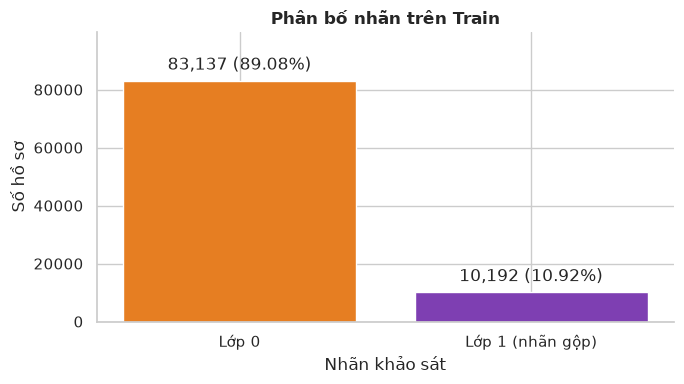

**Quan sát:** lớp 1 chiếm **10.92%** Train. Chỉ đoán lớp 0 đạt Accuracy **89.08%**, nhưng Recall lớp 1 bằng 0. Nhóm đọc Precision, Recall và F1 cùng Accuracy.

In [4]:
DB.execute(
    "CREATE TABLE data_summary (position INTEGER, Feature TEXT, dtype TEXT, missing_count INTEGER, distinct_count INTEGER, minimum REAL, maximum REAL)"
)
DB.execute(
    'CREATE TABLE numeric_summary (position INTEGER, Feature TEXT, count INTEGER, mean REAL, std REAL, min REAL, "25%" REAL, "50%" REAL, "75%" REAL, max REAL)'
)
for position, column in enumerate([TARGET] + FEATURES):
    field = ident(column)
    DB.execute(
        f"""
        INSERT INTO data_summary
        SELECT ?, ?, ?, COUNT(*)-COUNT({field}), COUNT(DISTINCT {field}), MIN({field}), MAX({field}) FROM train_data
    """,
        (position, column, str(df_eda[column].dtype)),
    )
    if column in NUMERIC_FEATURES:
        values = DB.execute(f"""
            SELECT COUNT({field}),AVG({field}),
                   CASE WHEN COUNT({field})>1 THEN sqrt(SUM(({field}-center)*({field}-center))/(COUNT({field})-1)) END,
                   MIN({field}), MAX({field})
            FROM train_data CROSS JOIN (SELECT AVG({field}) AS center FROM train_data)
        """).fetchone()
        DB.execute(
            "INSERT INTO numeric_summary VALUES (?,?,?,?,?,?,?,?,?,?)",
            (
                NUMERIC_FEATURES.index(column),
                column,
                values[0],
                values[1],
                values[2],
                values[3],
                sql_quantile(column, 0.25),
                sql_quantile(column, 0.5),
                sql_quantile(column, 0.75),
                values[4],
            ),
        )
DATA_SUMMARY_SQL = 'SELECT Feature, dtype AS "Kiểu đầu vào mô hình", missing_count AS "Số thiếu", distinct_count AS "Số giá trị khác nhau", minimum AS "Nhỏ nhất", maximum AS "Lớn nhất" FROM data_summary ORDER BY position'
NUMERIC_SUMMARY_SQL = 'SELECT Feature,count,mean,std,min,"25%","50%","75%",max FROM numeric_summary ORDER BY position'
display(table(DATA_SUMMARY_SQL))
save_table(DATA_SUMMARY_SQL, "ref_data_summary")
row_count = scalar("SELECT COUNT(*) FROM train_data")
duplicate_rows = scalar(
    f"SELECT COUNT(*)-(SELECT COUNT(*) FROM (SELECT DISTINCT {ALL_COLUMNS} FROM train_data)) FROM train_data"
)
print(f"Train: {row_count:,} dòng; trùng toàn bộ 22 cột: {duplicate_rows:,}.")
assert scalar("SELECT SUM(missing_count) FROM data_summary") == 0
DB.execute("""
    CREATE VIEW label_summary AS SELECT Diabetes_binary,COUNT(*) AS sample_count,
    100.0*COUNT(*)/(SELECT COUNT(*) FROM train_data) AS percent
    FROM train_data GROUP BY Diabetes_binary
""")
save_table("SELECT * FROM label_summary ORDER BY Diabetes_binary", "eda_target_counts")
values = records("SELECT * FROM label_summary ORDER BY Diabetes_binary")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    [r[TARGET] for r in values],
    [r["sample_count"] for r in values],
    color=[PALETTE[r[TARGET]] for r in values],
)
ax.set(
    title="Phân bố nhãn trên Train",
    xlabel="Nhãn khảo sát",
    ylabel="Số hồ sơ",
    xticks=[0, 1],
    xticklabels=["Lớp 0", "Lớp 1 (nhãn gộp)"],
    ylim=(0, 1.2 * scalar("SELECT MAX(sample_count) FROM label_summary")),
)
ax.bar_label(
    ax.containers[0],
    labels=[f"{r['sample_count']:,} ({r['percent']:.2f}%)" for r in values],
    padding=5,
)
fig.tight_layout()
save_and_show_figure("eda_01_target", fig)
positive_percent = scalar("SELECT percent FROM label_summary WHERE Diabetes_binary=1")
note(
    f"**Quan sát:** lớp 1 chiếm **{positive_percent:.2f}%** Train. Chỉ đoán lớp 0 đạt Accuracy **{100-positive_percent:.2f}%**, nhưng Recall lớp 1 bằng 0. Nhóm đọc Precision, Recall và F1 cùng Accuracy."
)


### b. Phân bố biến số và kiểm tra BMI

Nhóm dùng histogram cho BMI và hai biến số ngày. BMI được trình bày bằng biểu đồ kết hợp: boxplot cho vị trí phần đuôi và biểu đồ cột cho số hồ sơ tại từng giá trị ngoại lệ theo quy tắc IQR.
Các điểm ngoài râu chỉ được gắn cờ để mô tả; nhóm không tự xóa hồ sơ hay đổi nhãn. Phân bố chung của biến nhị phân được trình bày tại mục 1.1.c; quan hệ của biến thứ bậc với nhãn được phân tích ở mục 1.2.b.


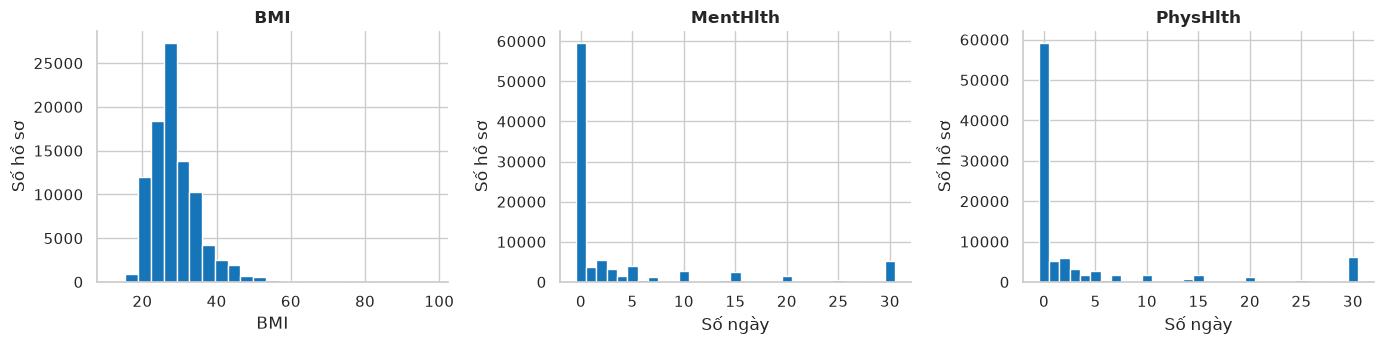

,Feature,count,mean,std,min,25%,50%,75%,max
0,BMI,93329,28.86,7.08,12.0,24.0,27.0,32.0,98.0
1,MentHlth,93329,3.80,7.98,0.0,0.0,0.0,3.0,30.0
2,PhysHlth,93329,3.86,8.28,0.0,0.0,0.0,2.0,30.0


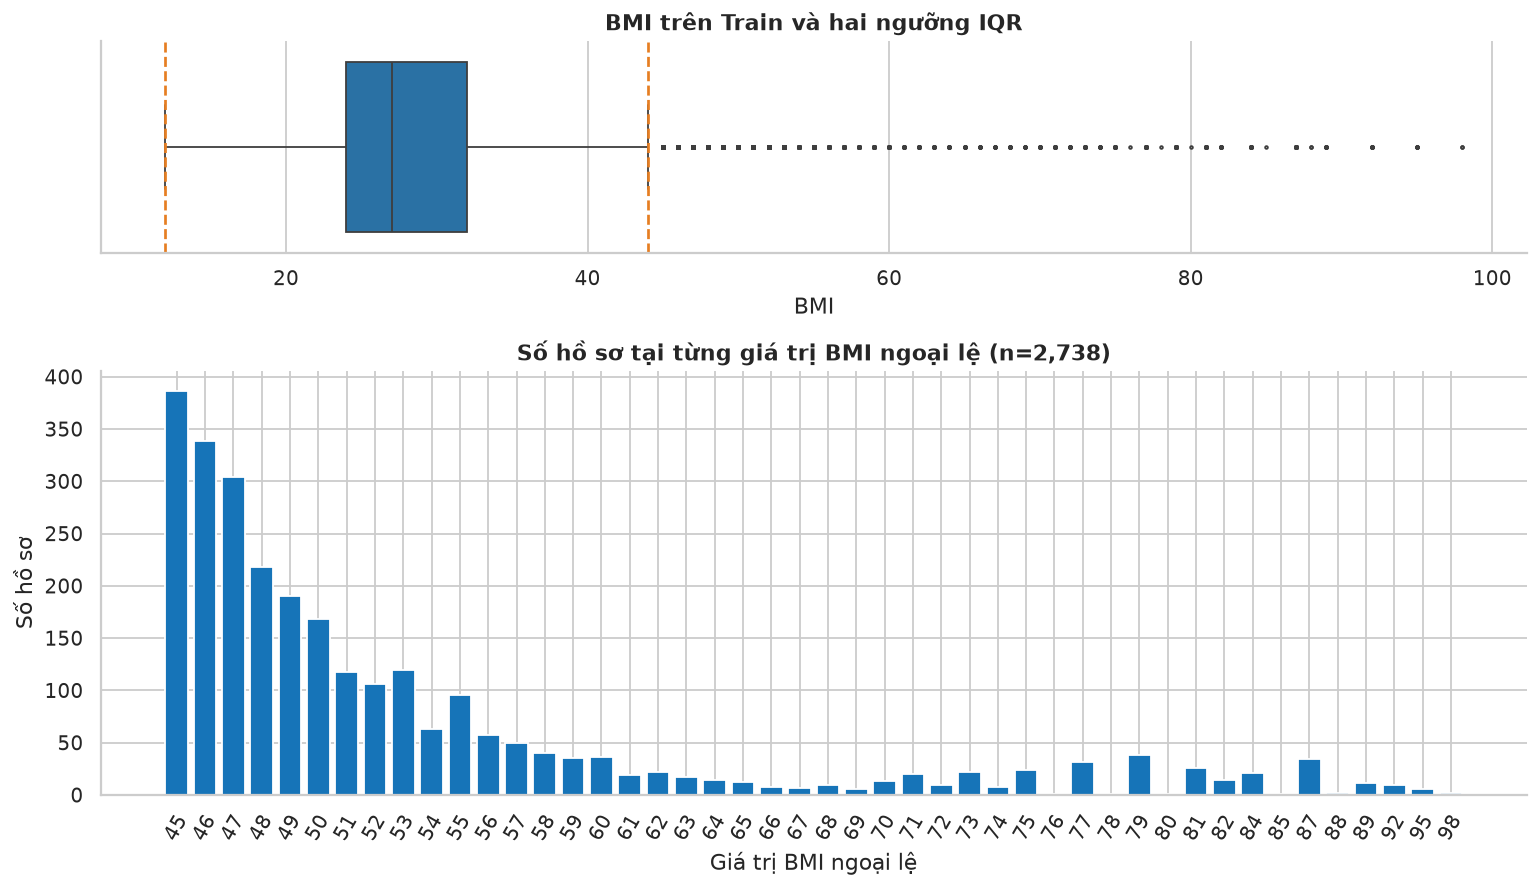

**Quan sát:** BMI tập trung chủ yếu trong khoảng Q1–Q3 **24–32**, có trung vị **27** và đuôi phải dài. Quy tắc IQR gắn cờ **2,738** hồ sơ (**2.93%** Train) có BMI < **12** hoặc > **44**; do BMI nhỏ nhất bằng 12, các điểm bị gắn cờ đều nằm ở đuôi trên và không bị tự động xóa. `MentHlth` và `PhysHlth` có **63.73%/63.32%** giá trị 0 ngày; 75% hồ sơ không vượt quá **3/2** ngày, nhưng cả hai vẫn có một nhóm nhỏ ở mức 30 ngày. Cả ba biến đều lệch phải, vì vậy cần đọc cùng trung vị, tứ phân vị và hình dạng phân bố thay vì chỉ dựa vào trung bình.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    bins = 25 if feature == "BMI" else np.arange(-0.5, 31.5)
    ax.hist(df_eda[feature], bins=bins, color=CONTINUOUS_COLOR, edgecolor="white")
    ax.set(
        title=feature,
        xlabel="BMI" if feature == "BMI" else "Số ngày",
        ylabel="Số hồ sơ",
    )
fig.tight_layout()
save_and_show_figure("eda_02_numeric_distributions", fig)

display(table(NUMERIC_SUMMARY_SQL).round(2))
save_table(NUMERIC_SUMMARY_SQL, "eda_numeric_summary")
bmi_summary = records(
    'SELECT "25%" AS q1,"50%" AS q2,"75%" AS q3 FROM numeric_summary WHERE Feature=?',
    ("BMI",),
)[0]
bmi_iqr = bmi_summary["q3"] - bmi_summary["q1"]
bmi_lower = bmi_summary["q1"] - 1.5 * bmi_iqr
bmi_upper = bmi_summary["q3"] + 1.5 * bmi_iqr
bmi_outlier_counts = table(
    """
    SELECT BMI, COUNT(*) AS sample_count
    FROM train_data WHERE BMI < ? OR BMI > ?
    GROUP BY BMI ORDER BY BMI
    """,
    (bmi_lower, bmi_upper),
)
bmi_outlier_total = int(bmi_outlier_counts["sample_count"].sum())
fig, axes = plt.subplots(2, 1, figsize=(12, 7), gridspec_kw={"height_ratios": [1, 2]})
sns.boxplot(data=df_eda, x="BMI", color=CONTINUOUS_COLOR, fliersize=1.5, ax=axes[0])
axes[0].axvline(bmi_lower, color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].axvline(bmi_upper, color=ORANGE, linestyle="--", linewidth=1.5)
axes[0].set(title="BMI trên Train và hai ngưỡng IQR", xlabel="BMI")
axes[1].bar(
    bmi_outlier_counts["BMI"].astype(str),
    bmi_outlier_counts["sample_count"],
    color=CONTINUOUS_COLOR,
)
axes[1].set(
    title=f"Số hồ sơ tại từng giá trị BMI ngoại lệ (n={bmi_outlier_total:,})",
    xlabel="Giá trị BMI ngoại lệ",
    ylabel="Số hồ sơ",
)
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout()
save_and_show_figure("eda_03_bmi_outlier_detail", fig)
save_table(
    "SELECT BMI, COUNT(*) AS sample_count FROM train_data WHERE BMI < ? OR BMI > ? GROUP BY BMI ORDER BY BMI",
    "eda_bmi_outlier_counts",
    (bmi_lower, bmi_upper),
)
zero_rates = records(
    "SELECT 100.0*AVG(MentHlth=0) AS mental,100.0*AVG(PhysHlth=0) AS physical FROM train_data"
)[0]
day_q3 = {
    row["Feature"]: row["q3"]
    for row in records("SELECT Feature, \"75%\" AS q3 FROM numeric_summary WHERE Feature IN ('MentHlth','PhysHlth')")
}
bmi_outlier_percent = 100.0 * bmi_outlier_total / row_count
note(
    f"**Quan sát:** BMI tập trung chủ yếu trong khoảng Q1–Q3 **{bmi_summary['q1']:.0f}–{bmi_summary['q3']:.0f}**, có trung vị **{bmi_summary['q2']:.0f}** và đuôi phải dài. Quy tắc IQR gắn cờ **{bmi_outlier_total:,}** hồ sơ (**{bmi_outlier_percent:.2f}%** Train) có BMI < **{bmi_lower:.0f}** hoặc > **{bmi_upper:.0f}**; do BMI nhỏ nhất bằng 12, các điểm bị gắn cờ đều nằm ở đuôi trên và không bị tự động xóa. `MentHlth` và `PhysHlth` có **{zero_rates['mental']:.2f}%/{zero_rates['physical']:.2f}%** giá trị 0 ngày; 75% hồ sơ không vượt quá **{day_q3['MentHlth']:.0f}/{day_q3['PhysHlth']:.0f}** ngày, nhưng cả hai vẫn có một nhóm nhỏ ở mức 30 ngày. Cả ba biến đều lệch phải, vì vậy cần đọc cùng trung vị, tứ phân vị và hình dạng phân bố thay vì chỉ dựa vào trung bình."
)


### c. Phân bố biến nhị phân trên Train

Mỗi biến nhị phân có một biểu đồ tròn `False/True` trên toàn bộ Train, không phân tách theo nhãn 0/1. Nhãn trên lát cắt cho biết cả tỷ lệ và số hồ sơ. Quan hệ giữa từng biến và nhãn được phân tích riêng tại mục 1.2.


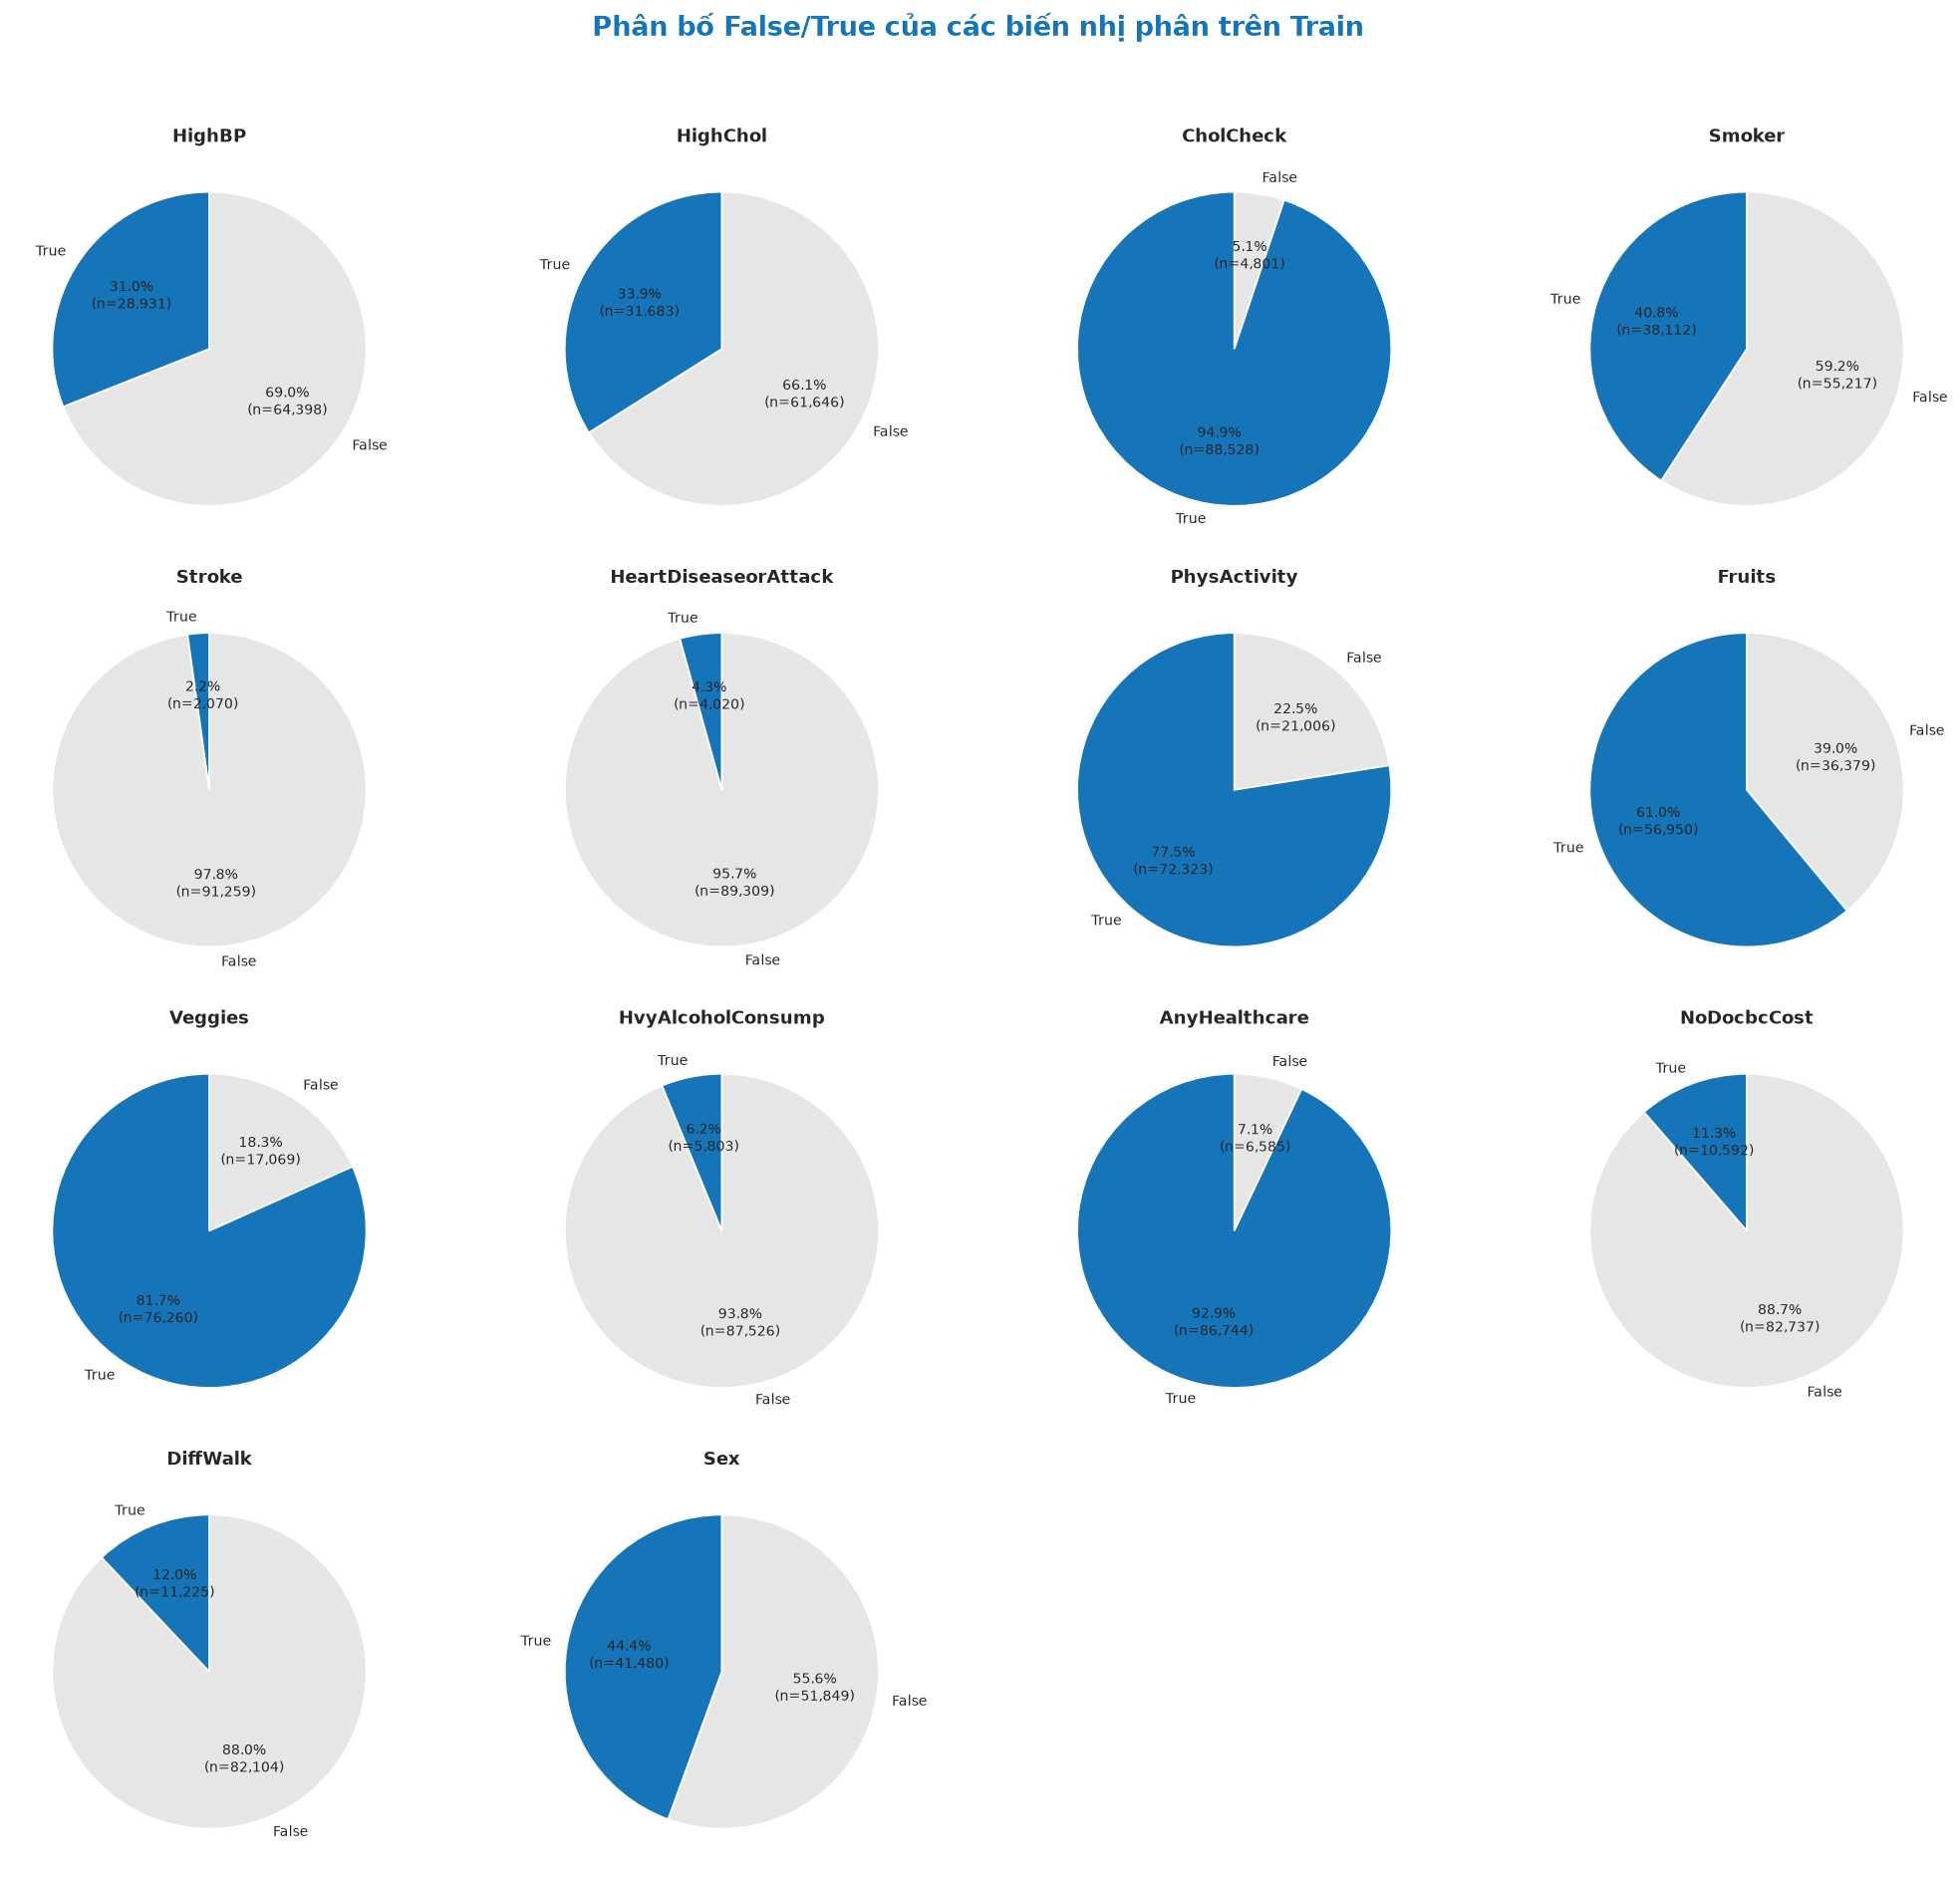

**Quan sát:** Các biến nhị phân có mức độ cân bằng rất khác nhau. `CholCheck` và `AnyHealthcare` gần như luôn mang giá trị `True`, trong khi `Stroke`, `HeartDiseaseorAttack` và `HvyAlcoholConsump` có tỷ lệ `True` thấp. `HighBP` và `HighChol` xuất hiện ở khoảng một phần ba mẫu; các hành vi `PhysActivity`, `Fruits` và `Veggies` tương đối phổ biến. Đây mới là phân bố chung trên Train, chưa chứng minh biến nào liên quan mạnh đến nhãn; mối quan hệ với lớp 0/1 được kiểm tra riêng tại mục 1.2.

In [6]:
DB.execute("DROP TABLE IF EXISTS binary_overall_summary")
DB.execute("CREATE TABLE binary_overall_summary (Feature TEXT, Value INTEGER, sample_count INTEGER, percent REAL)")
for feature in BINARY:
    field = ident(feature)
    DB.execute(
        f"""
        INSERT INTO binary_overall_summary
        SELECT ?, {field}, COUNT(*),
               100.0 * COUNT(*) / (SELECT COUNT(*) FROM train_data)
        FROM train_data GROUP BY {field}
        """,
        (feature,),
    )
save_table(
    "SELECT Feature,Value,sample_count,percent FROM binary_overall_summary ORDER BY Feature,Value",
    "eda_binary_distribution_overall",
)


def pie_count_label(total):
    return lambda pct: f"{pct:.1f}%\n(n={int(round(pct * total / 100)):,})"


def plot_binary_pies():
    columns = 4
    rows = math.ceil(len(BINARY) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(16, 3.7 * rows), squeeze=False)
    for ax, feature in zip(axes.flat, BINARY):
        values = records(
            "SELECT Value,sample_count FROM binary_overall_summary WHERE Feature=? ORDER BY Value",
            (feature,),
        )
        counts = [next((r["sample_count"] for r in values if r["Value"] == value), 0) for value in [0, 1]]
        ax.pie(
            counts,
            labels=["False", "True"],
            colors=["#E6E6E6", BLUE],
            autopct=pie_count_label(sum(counts)),
            startangle=90,
            counterclock=False,
            wedgeprops={"edgecolor": "white", "linewidth": 1},
            textprops={"fontsize": 8},
        )
        ax.set_title(feature, fontsize=10, fontweight="bold")
    for ax in list(axes.flat)[len(BINARY):]:
        ax.set_visible(False)
    fig.suptitle("Phân bố False/True của các biến nhị phân trên Train", fontsize=15, fontweight="bold", color=BLUE)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig


fig = plot_binary_pies()
save_and_show_figure("eda_04_binary_pies_overall", fig)
note(
    "**Quan sát:** Các biến nhị phân có mức độ cân bằng rất khác nhau. `CholCheck` và `AnyHealthcare` gần như luôn mang giá trị `True`, trong khi `Stroke`, `HeartDiseaseorAttack` và `HvyAlcoholConsump` có tỷ lệ `True` thấp. `HighBP` và `HighChol` xuất hiện ở khoảng một phần ba mẫu; các hành vi `PhysActivity`, `Fruits` và `Veggies` tương đối phổ biến. Đây mới là phân bố chung trên Train, chưa chứng minh biến nào liên quan mạnh đến nhãn; mối quan hệ với lớp 0/1 được kiểm tra riêng tại mục 1.2."
)


## 1.2. Đặc trưng và nhãn

### a. Biến nhị phân

Mỗi biến có hai biểu đồ tròn đặt cạnh nhau: nhãn 1 bên trái và nhãn 0 bên phải. Mỗi biểu đồ thể hiện tỷ lệ và số hồ sơ False/True trong chính lớp đó; màu cam là False, màu tím là True. Nhãn 1 gộp tiền tiểu đường/tiểu đường theo quy ước dự án. Mỗi cặp dùng cùng màu và thứ tự để dễ đối chiếu. Đây là phân bố đặc trưng trong từng lớp, P(X | Y).


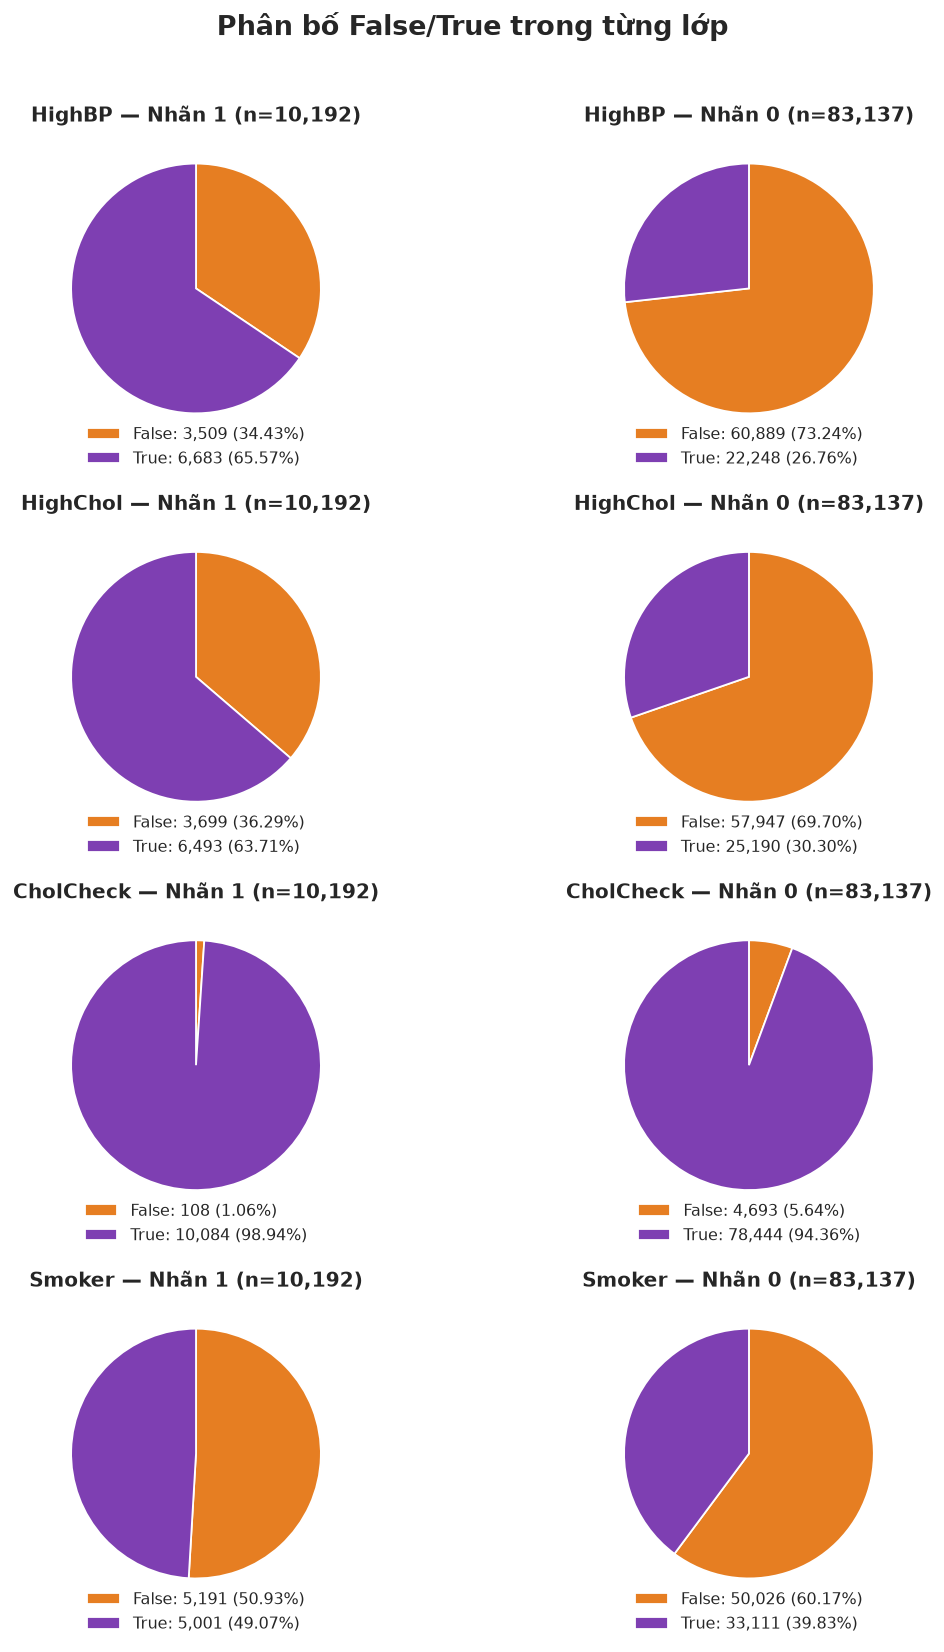

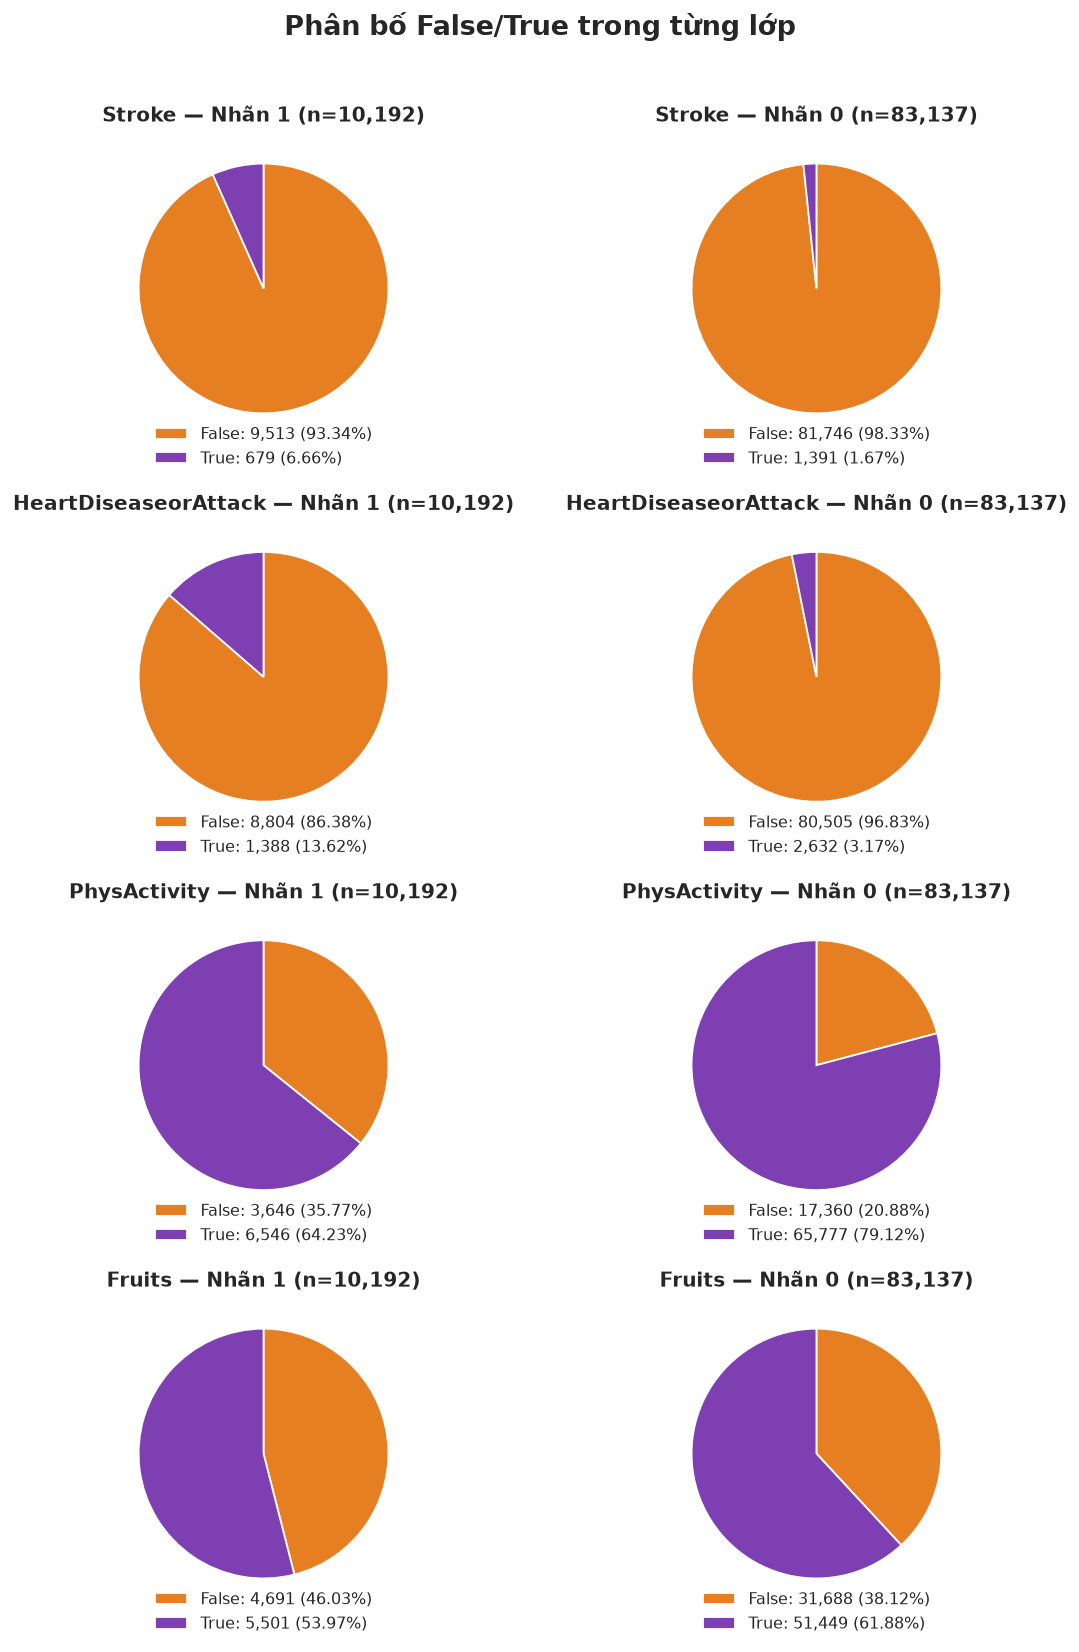

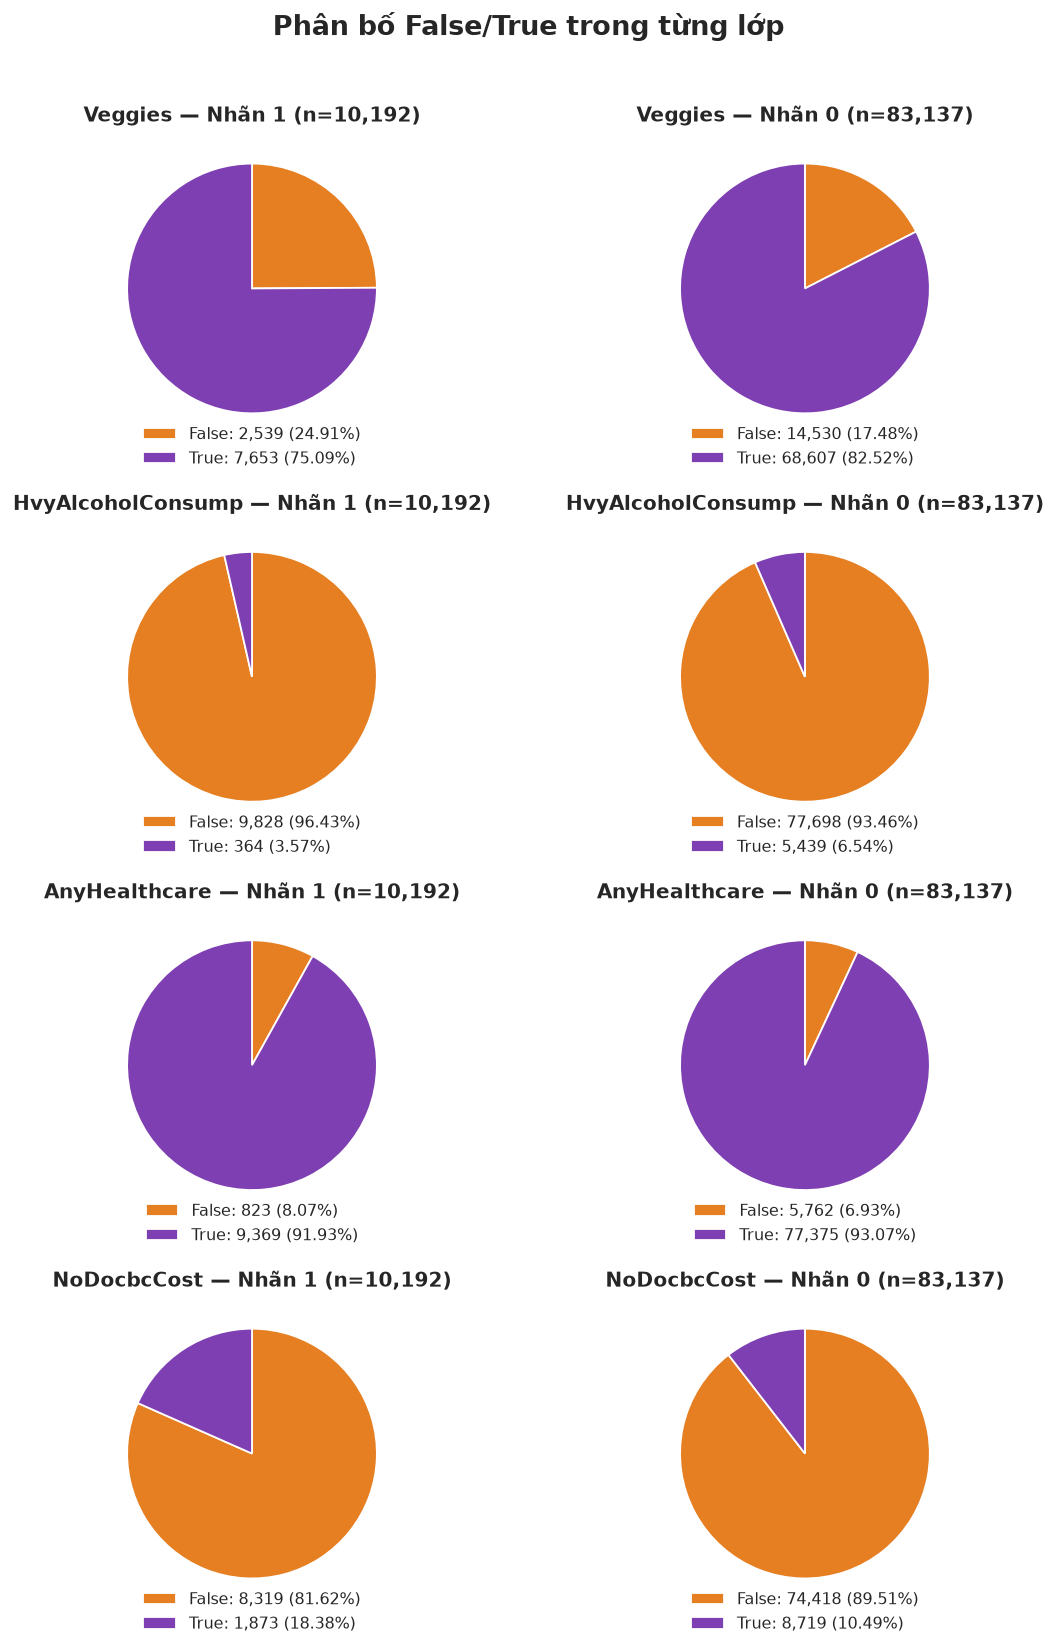

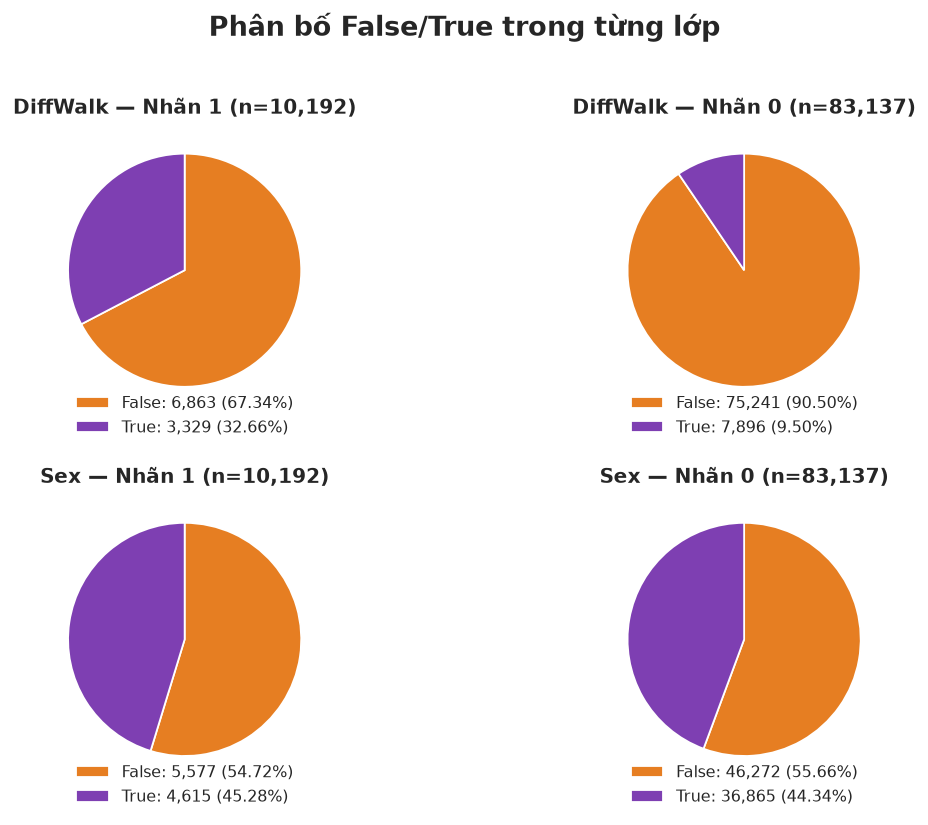

In [ ]:
DB.execute("DROP TABLE IF EXISTS binary_by_label")
DB.execute("CREATE TABLE binary_by_label (Feature TEXT, Label INTEGER, Value INTEGER, sample_count INTEGER, percent REAL)")
for feature in BINARY:
    field = ident(feature)
    for label in [1, 0]:
        for value in [0, 1]:
            DB.execute(
                f"""INSERT INTO binary_by_label
                SELECT ?, ?, ?, COUNT(*),
                       100.0 * COUNT(*) / (SELECT COUNT(*) FROM train_data WHERE Diabetes_binary=?)
                FROM train_data WHERE Diabetes_binary=? AND {field}=?""",
                (feature, label, value, label, label, value),
            )
save_table("SELECT * FROM binary_by_label ORDER BY Feature,Label DESC,Value", "eda_binary_by_label")

# Each row compares the same feature; each figure contains four feature pairs.
for start in range(0, len(BINARY), 4):
    subset = BINARY[start:start + 4]
    fig, axes = plt.subplots(len(subset), 2, figsize=(10, 3.3 * len(subset)), squeeze=False)
    for row_index, feature in enumerate(subset):
        for column_index, label in enumerate([1, 0]):
            ax = axes[row_index, column_index]
            rows = records(
                "SELECT Value,sample_count FROM binary_by_label WHERE Feature=? AND Label=? ORDER BY Value",
                (feature, label),
            )
            counts = [row["sample_count"] for row in rows]
            total = sum(counts)
            wedges, _ = ax.pie(
                counts, colors=[ORANGE, PURPLE], startangle=90,
                counterclock=False, wedgeprops={"edgecolor": "white"},
            )
            labels = [
                f"{bool(value)}: {count:,} ({100 * count / total:.2f}%)"
                for value, count in enumerate(counts)
            ]
            ax.legend(wedges, labels, loc="lower center", bbox_to_anchor=(0.5, -0.12),
                      frameon=False, fontsize=9)
            ax.set_title(f"{feature} — Nhãn {label} (n={total:,})", fontsize=11)
    fig.suptitle("Phân bố False/True trong từng lớp", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0.02, 1, 0.97))
    save_and_show_figure(f"eda_04_binary_by_label_{start // 4 + 1}", fig)

comparison = table("""
    SELECT Feature,
           MAX(CASE WHEN Label=1 AND Value=1 THEN percent END) AS true_label1_percent,
           MAX(CASE WHEN Label=0 AND Value=1 THEN percent END) AS true_label0_percent
    FROM binary_by_label GROUP BY Feature
""")
comparison["difference_pp"] = comparison["true_label1_percent"] - comparison["true_label0_percent"]
display(comparison.round(2))
top3_binary = comparison.assign(abs_difference_pp=comparison["difference_pp"].abs()).sort_values(
    ["abs_difference_pp", "Feature"], ascending=[False, True]
).head(3)
display(Markdown("### Ba biến có chênh lệch tỷ lệ True lớn nhất giữa hai lớp"))
display(top3_binary[["Feature", "true_label1_percent", "true_label0_percent", "difference_pp"]].rename(columns={
    "Feature": "Biến", "true_label1_percent": "True trong nhãn 1 (%)",
    "true_label0_percent": "True trong nhãn 0 (%)", "difference_pp": "Chênh lệch 1−0 (điểm %)",
}).round(2))
for row in top3_binary.to_dict("records"):
    note(f"**{row['Feature']}:** tỷ lệ True ở nhãn 1 là **{row['true_label1_percent']:.2f}%**, ở nhãn 0 là **{row['true_label0_percent']:.2f}%**; chênh lệch **{row['difference_pp']:+.2f} điểm phần trăm**.")
note(
    "**Nhận xét:** HighBP, HighChol và DiffWalk có chênh lệch tỷ lệ True lớn nhất trong 14 biến nhị phân. "
    "Các hồ sơ nhãn 1 báo cáo huyết áp cao, cholesterol cao và khó khăn khi đi bộ/leo cầu thang thường xuyên hơn nhóm nhãn 0. "
    "Đây là dấu hiệu ba biến có khả năng cung cấp thông tin phân biệt hai lớp, cần được kiểm tra tiếp cùng các biến khác và kết quả mô hình. "
    "Chênh lệch được đo bằng điểm phần trăm, không phải phần trăm tăng tương đối; liên hệ quan sát chưa chứng minh nhân quả hoặc mức đóng góp độc lập của từng biến."
)
note(
    "**Quan sát:** So sánh tỷ lệ True giữa hai lớp giúp nhận diện đặc điểm phổ biến hơn trong từng lớp. "
    "Các tỷ lệ trong mỗi biểu đồ có mẫu số là số hồ sơ của chính lớp đó, nên vẫn so sánh được khi hai lớp khác quy mô. "
    "Đây là phân bố P(X | Y), không phải tỷ lệ mắc nhãn 1 khi có đặc điểm P(Y | X); các chênh lệch chưa được điều chỉnh theo tuổi, BMI và các biến khác."
)


### b. Biến thứ bậc và số ngày sức khỏe kém

Khung 2×2 gom Age, Education, Income và GenHlth; khung 1×2 gom MentHlth và PhysHlth.
Income tính bằng nghìn USD/hộ/năm. GenHlth đi từ Excellent đến Poor.
Các biểu đồ trong cùng khung dùng chung thang đo, bắt đầu từ 0%; mức không có hồ sơ không có cột tỷ lệ.

Nhóm chỉ vẽ tỷ lệ số ngày ở mức có n ≥ 30; bảng dưới hình liệt kê các mức ít hồ sơ. Nhóm giữ nguyên các hồ sơ và giá trị trong dữ liệu huấn luyện.


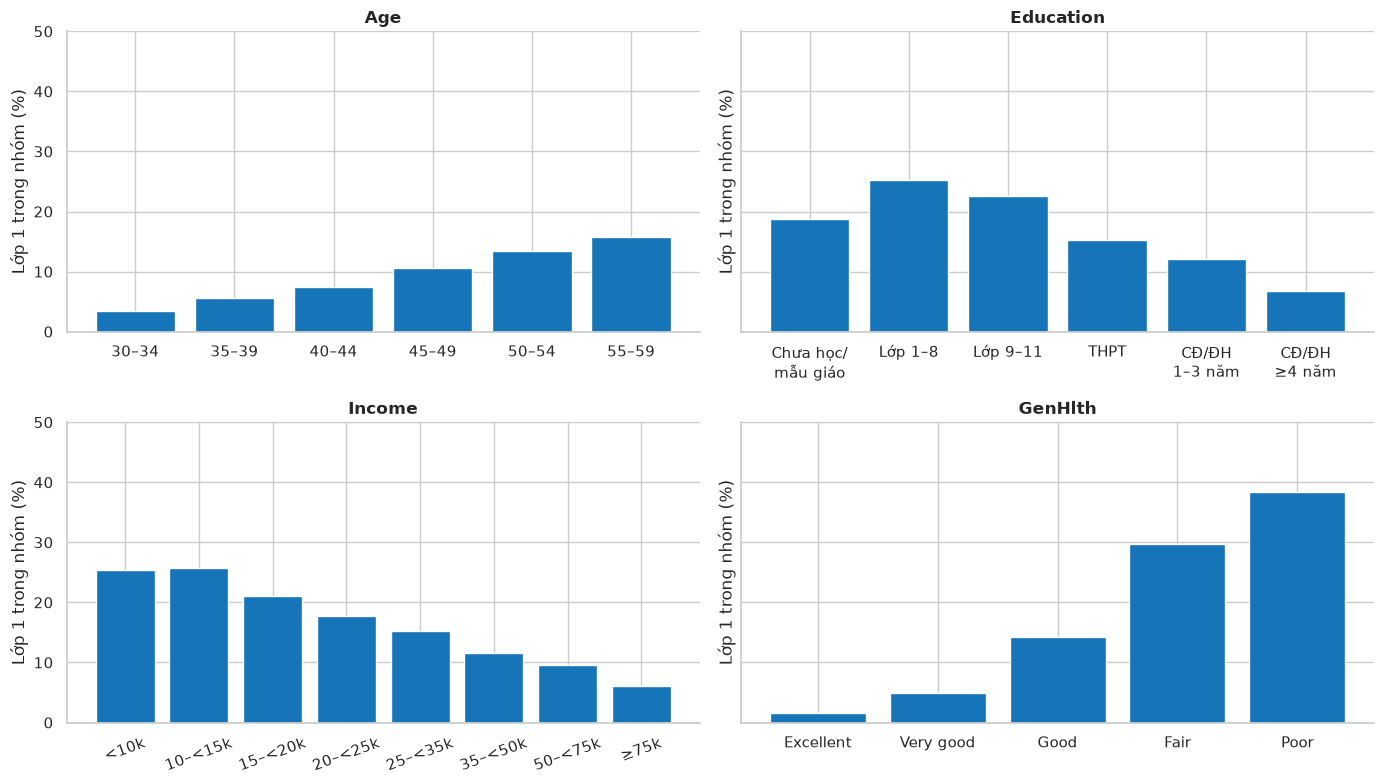

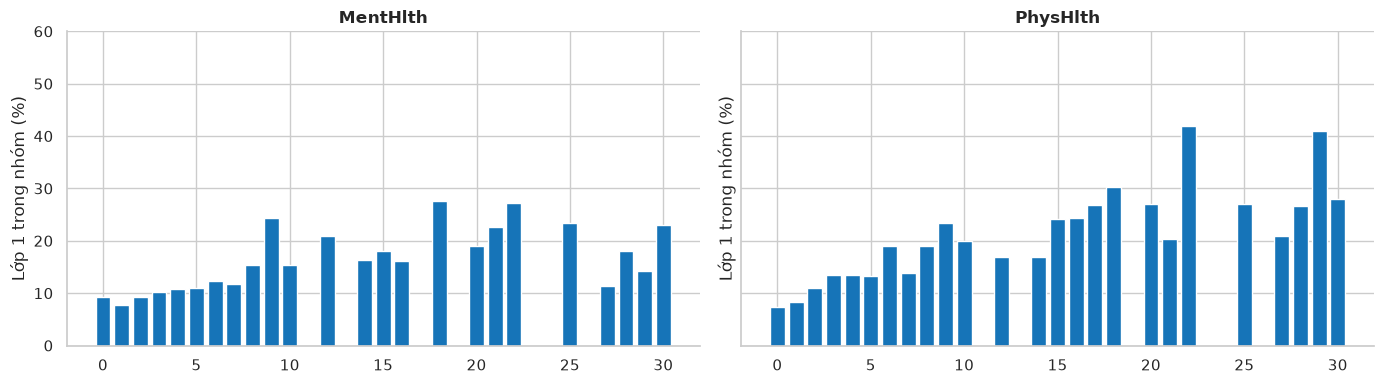

**Quan sát:** tỷ lệ thấp nhất ở tuổi **30–34** (3.49%, n=8,744), cao nhất ở **55–59** (15.77%, n=24,561). Nhóm so sánh các hồ sơ trong mẫu, không theo dõi một người qua thời gian.

### Mức số ngày có n < 30: không vẽ tỷ lệ ở hình chính

,Feature,Days,sample_count,positive_rate
0,MentHlth,11,15,13.33
1,MentHlth,13,21,23.81
2,MentHlth,17,22,18.18
3,MentHlth,19,4,0.00
4,MentHlth,23,17,17.65
5,MentHlth,24,14,28.57
6,MentHlth,26,18,22.22
7,PhysHlth,11,24,16.67
8,PhysHlth,13,24,45.83
9,PhysHlth,19,5,60.00


Nhóm giữ các hồ sơ này và đầy đủ các mức trong dữ liệu huấn luyện. Hình số ngày chỉ hiển thị tỷ lệ khi n ≥ 30.

**GenHlth = Excellent:** lớp 1 1.59%, n=18,916.

**GenHlth = Poor:** lớp 1 38.43%, n=3,854.

**Income = <10k:** lớp 1 25.37%, n=3,957.

**Income = ≥75k:** lớp 1 6.12%, n=42,597.

**Nhận xét:** Tỷ lệ nhãn 1 tăng theo nhóm tuổi và mức độ sức khỏe tổng quát kém, đồng thời nhìn chung giảm ở các nhóm thu nhập và học vấn cao hơn. Số ngày sức khỏe thể chất kém cũng cho thấy xu hướng cùng chiều với nhãn 1; quan hệ với số ngày sức khỏe tinh thần kém dao động hơn. Các kết quả mô tả liên hệ riêng lẻ trên Train, chưa điều chỉnh ảnh hưởng đồng thời của các biến và chưa chứng minh quan hệ nhân quả.

In [7]:
fig = plot_rate_grid(list(ORDINAL_DOMAINS), LABEL_MAPS)
save_and_show_figure("eda_05_ordinal_rates", fig)
fig = plot_rate_grid(["MentHlth", "PhysHlth"], LABEL_MAPS, min_count=30)
save_and_show_figure("eda_06_health_day_rates", fig)
low_age = records(
    "SELECT * FROM feature_summary WHERE Feature='Age' AND positive_rate IS NOT NULL ORDER BY positive_rate,level LIMIT 1"
)[0]
high_age = records(
    "SELECT * FROM feature_summary WHERE Feature='Age' AND positive_rate IS NOT NULL ORDER BY positive_rate DESC,level LIMIT 1"
)[0]
note(
    f"**Quan sát:** tỷ lệ thấp nhất ở tuổi **{LABEL_MAPS['Age'][low_age['level']]}** ({low_age['positive_rate']:.2f}%, n={low_age['sample_count']:,}), cao nhất ở **{LABEL_MAPS['Age'][high_age['level']]}** ({high_age['positive_rate']:.2f}%, n={high_age['sample_count']:,}). Nhóm so sánh các hồ sơ trong mẫu, không theo dõi một người qua thời gian."
)
display(Markdown("### Mức số ngày có n < 30: không vẽ tỷ lệ ở hình chính"))
display(
    table(
        "SELECT Feature,level AS Days,sample_count,positive_rate FROM feature_summary WHERE Feature IN ('MentHlth','PhysHlth') AND sample_count BETWEEN 1 AND 29 ORDER BY CASE Feature WHEN 'MentHlth' THEN 0 ELSE 1 END,position"
    ).round(2)
)
note(
    "Nhóm giữ các hồ sơ này và đầy đủ các mức trong dữ liệu huấn luyện. Hình số ngày chỉ hiển thị tỷ lệ khi n ≥ 30."
)
for feature in ["GenHlth", "Income"]:
    for row in records(
        "SELECT * FROM feature_summary WHERE Feature=? AND (level=(SELECT MIN(level) FROM feature_summary WHERE Feature=?) OR level=(SELECT MAX(level) FROM feature_summary WHERE Feature=?)) ORDER BY position",
        (feature, feature, feature),
    ):
        note(
            f"**{feature} = {LABEL_MAPS[feature][row['level']]}:** lớp 1 {row['positive_rate']:.2f}%, n={row['sample_count']:,}."
        )
note(
    "**Nhận xét:** Tỷ lệ nhãn 1 tăng theo nhóm tuổi và mức độ sức khỏe tổng quát kém, đồng thời nhìn chung giảm ở các nhóm thu nhập và học vấn cao hơn. Số ngày sức khỏe thể chất kém cũng cho thấy xu hướng cùng chiều với nhãn 1; quan hệ với số ngày sức khỏe tinh thần kém dao động hơn. Các kết quả mô tả liên hệ riêng lẻ trên Train, chưa điều chỉnh ảnh hưởng đồng thời của các biến và chưa chứng minh quan hệ nhân quả."
)


### c. BMI theo nhãn

Hai lớp dùng chung ranh giới bin và mỗi lớp có tổng tỷ trọng 100%.
Nhờ đó, người đọc so sánh hình dạng phân bố dù hai lớp có số hồ sơ khác nhau.
Tỷ trọng trong hình này không phải tỷ lệ mắc nhãn 1 tại một mức BMI.


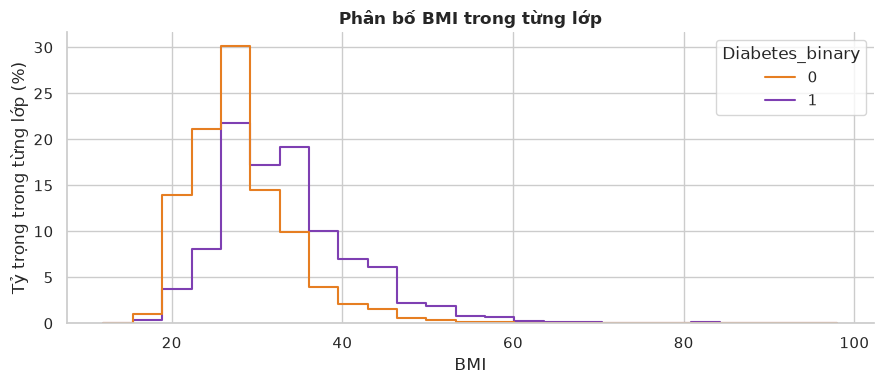

,Diabetes_binary,count,mean,median
0,0,83137,28.28,27.0
1,1,10192,33.60,32.0


**Nhận xét:** Phân bố BMI của nhóm nhãn 1 dịch sang phía giá trị cao hơn nhóm nhãn 0, với trung vị lần lượt là 32 và 27. Tuy nhiên, hai phân bố vẫn chồng lấp đáng kể, cho thấy BMI có liên hệ với nhãn nhưng chưa đủ để phân loại riêng lẻ. Cần xem xét BMI cùng tuổi, tình trạng sức khỏe và các đặc trưng khác; kết quả này chưa chứng minh quan hệ nhân quả.

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=df_eda,
    x="BMI",
    hue=TARGET,
    hue_order=[0, 1],
    bins=25,
    stat="percent",
    common_norm=False,
    common_bins=True,
    element="step",
    fill=False,
    palette=PALETTE,
    ax=ax,
)
ax.set(
    title="Phân bố BMI trong từng lớp",
    xlabel="BMI",
    ylabel="Tỷ trọng trong từng lớp (%)",
)
fig.tight_layout()
save_and_show_figure("eda_07_bmi_by_target", fig)

DB.execute(
    "CREATE TABLE bmi_stats AS SELECT Diabetes_binary,COUNT(BMI) AS count,AVG(BMI) AS mean,CAST(NULL AS REAL) AS median FROM train_data GROUP BY Diabetes_binary"
)
for row in records("SELECT Diabetes_binary FROM bmi_stats ORDER BY Diabetes_binary"):
    label = row[TARGET]
    DB.execute(
        "UPDATE bmi_stats SET median=? WHERE Diabetes_binary=?",
        (sql_quantile("BMI", 0.5, "Diabetes_binary=?", (label,)), label),
    )
display(table("SELECT * FROM bmi_stats ORDER BY Diabetes_binary").round(2))
save_table("SELECT * FROM bmi_stats ORDER BY Diabetes_binary", "eda_bmi_by_target")
note(
    "**Nhận xét:** Phân bố BMI của nhóm nhãn 1 dịch sang phía giá trị cao hơn nhóm nhãn 0, với trung vị lần lượt là 32 và 27. Tuy nhiên, hai phân bố vẫn chồng lấp đáng kể, cho thấy BMI có liên hệ với nhãn nhưng chưa đủ để phân loại riêng lẻ. Cần xem xét BMI cùng tuổi, tình trạng sức khỏe và các đặc trưng khác; kết quả này chưa chứng minh quan hệ nhân quả."
)


## 1.3. Quan hệ kết hợp và tương quan

### a. Các cặp biến theo giả thuyết từ mục 1.2

Mỗi ô ghi **tỷ lệ lớp 1 và số hồ sơ n**. Ô trống có n=0; nhóm không gán tỷ lệ 0% cho ô thiếu dữ liệu.
Nhóm BMI chỉ phục vụ EDA, không thay thế đặc trưng BMI đưa vào mô hình.

Nhóm đặt trần màu theo tỷ lệ lớn nhất trong bảng, làm tròn lên bội số 5 điểm phần trăm. Thang màu thể hiện khoảng tỷ lệ quan sát, không chạy đến 100%.


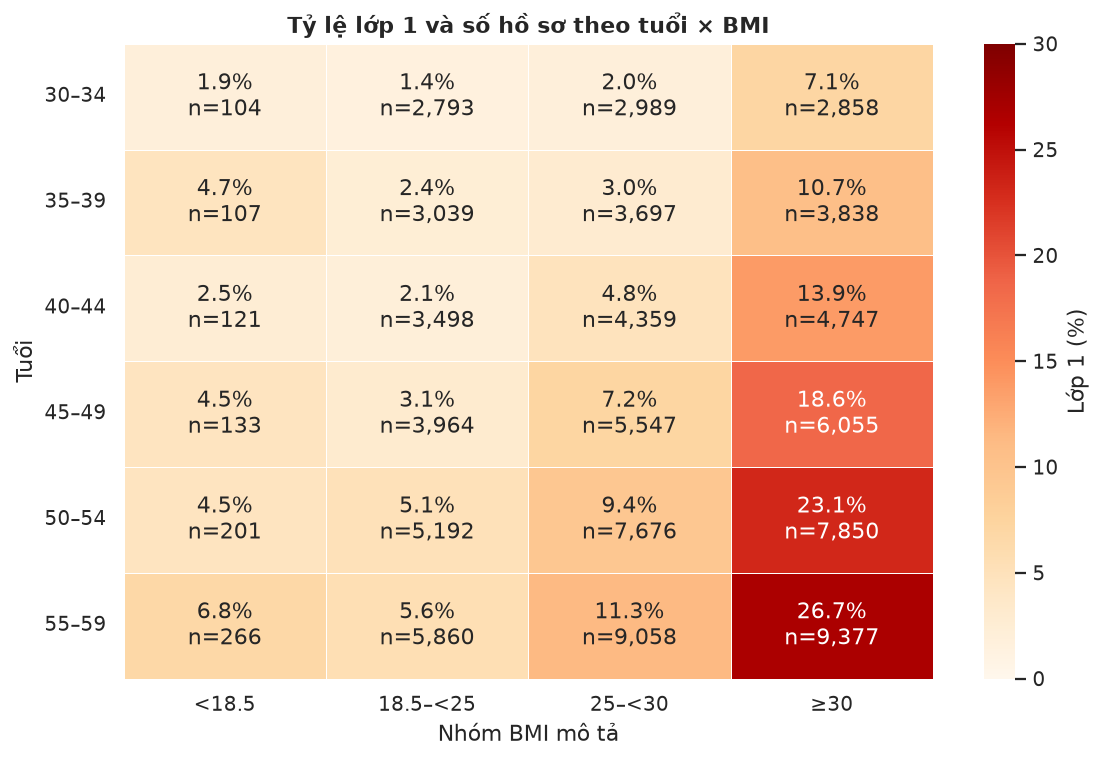

**Quan sát:** tỷ lệ cao nhất ở tuổi **55–59**, BMI **≥30**: **26.72%**, n=**9,377**. Nhóm chưa kiểm định tương tác tuổi × BMI.

### Các cặp biến bổ sung từ giả thuyết ở mục 1.2

Mỗi ô thể hiện tỷ lệ nhãn 1 và số hồ sơ. Các heatmap bổ sung dùng chung thang màu 0–40% để dễ đối chiếu; dấu * đánh dấu ô có n < 30, cần thận trọng khi đọc tỷ lệ.

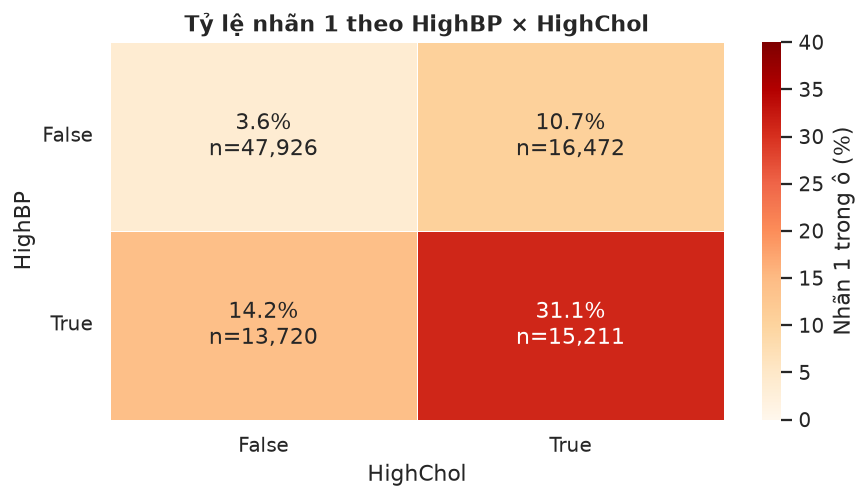

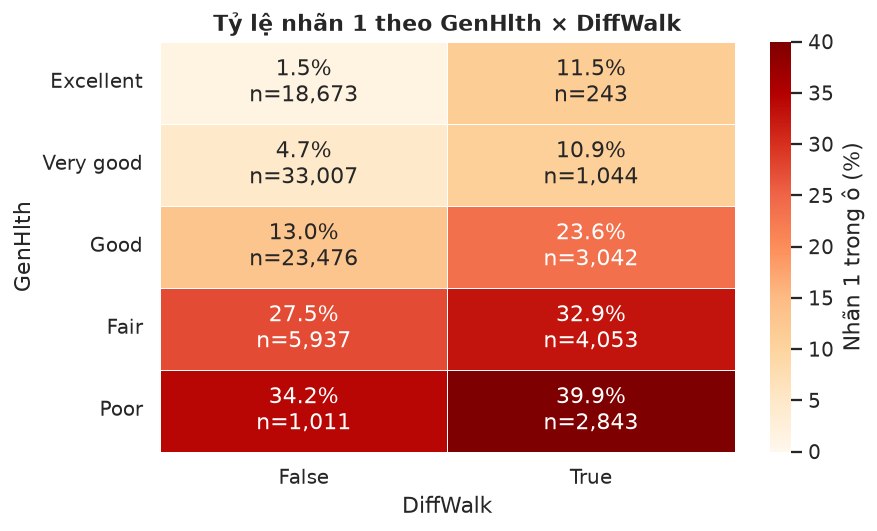

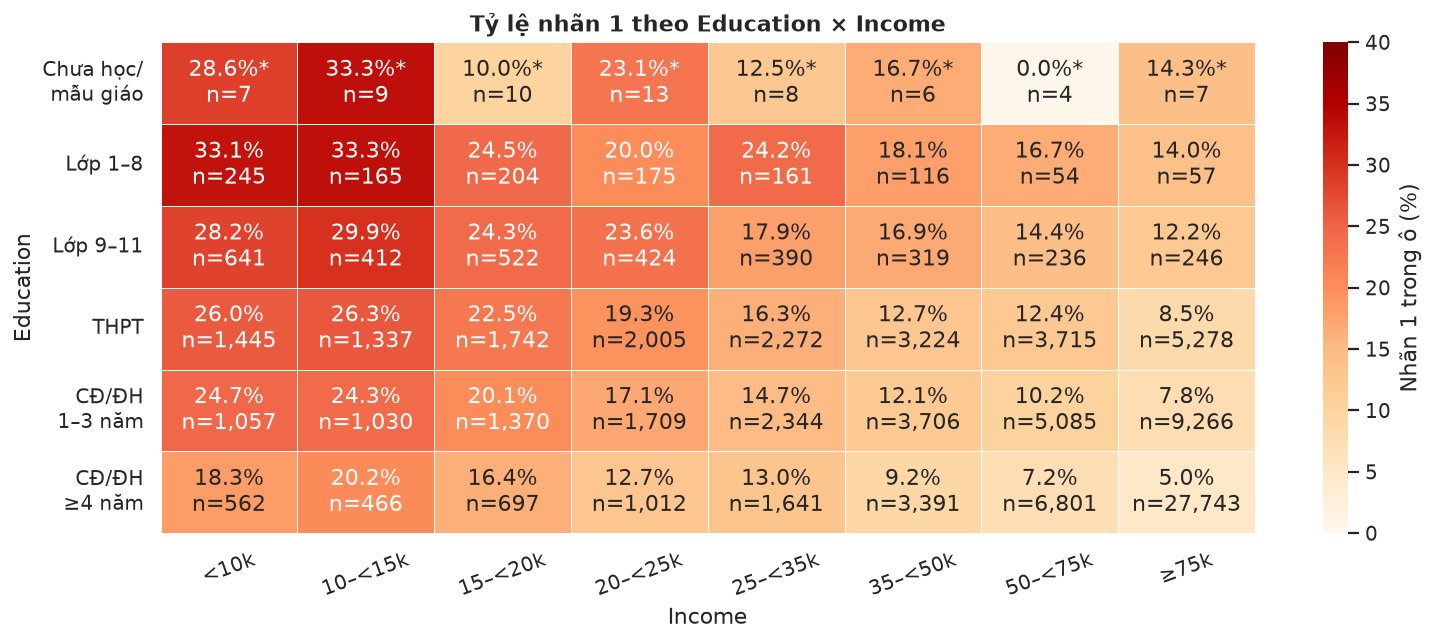

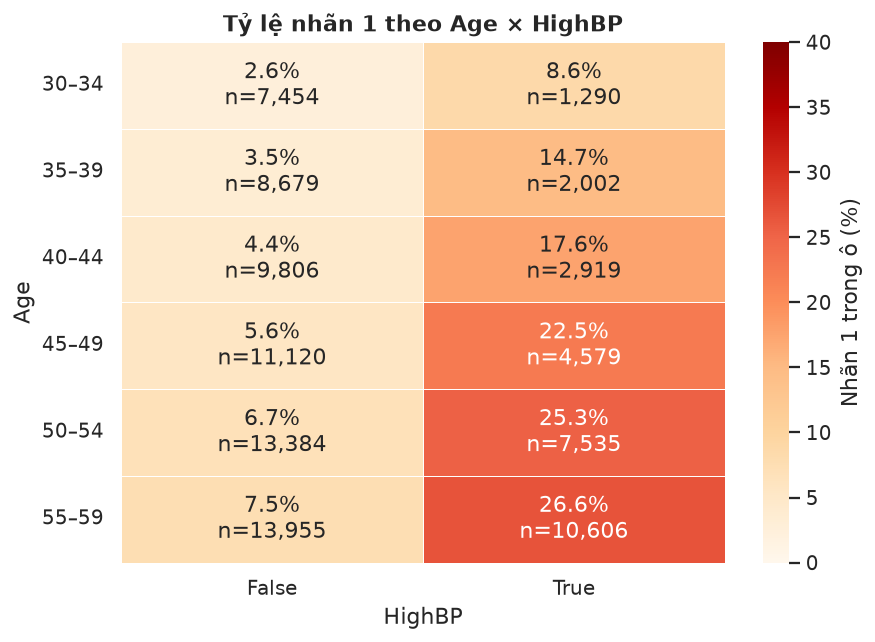

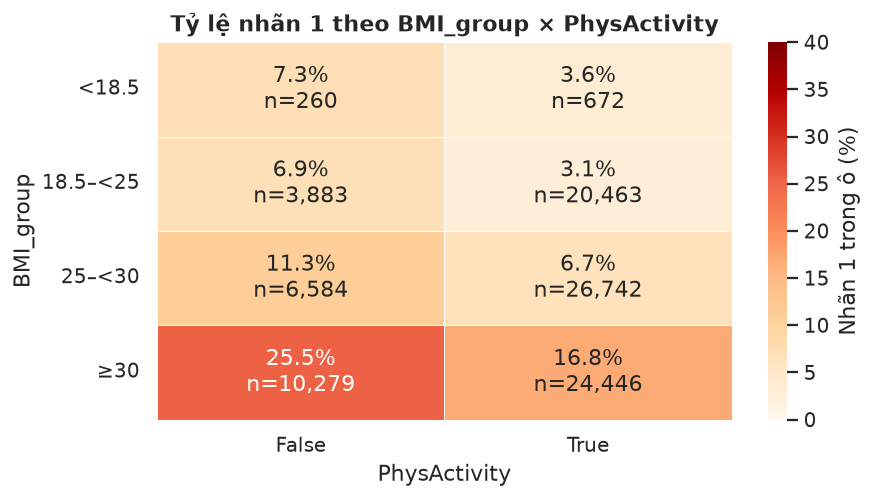

**Cách diễn giải:** Đọc chênh lệch tỷ lệ cùng số hồ sơ trong từng ô để kiểm tra giả thuyết về các đặc trưng kết hợp. Các biểu đồ mô tả trên Train chưa kiểm định tương tác thống kê, chưa chứng minh quan hệ nhân quả hoặc hiệu quả của việc tạo biến mới.

In [ ]:
bmi_labels = ["<18.5", "18.5–<25", "25–<30", "≥30"]
DB.execute("CREATE TABLE bmi_levels (position INTEGER PRIMARY KEY, label TEXT)")
DB.executemany("INSERT INTO bmi_levels VALUES (?,?)", enumerate(bmi_labels))
DB.execute("""
    CREATE VIEW age_bmi_summary AS
    SELECT a.level AS Age,b.position AS bmi_position,b.label AS BMI_group,
           COALESCE(g.sample_count,0) AS sample_count,g.positive_rate
    FROM feature_levels a CROSS JOIN bmi_levels b LEFT JOIN (
        SELECT Age,bmi_position,COUNT(*) AS sample_count,100.0*AVG(Diabetes_binary) AS positive_rate
        FROM (SELECT Age,Diabetes_binary,CASE WHEN BMI<18.5 THEN 0 WHEN BMI<25 THEN 1 WHEN BMI<30 THEN 2 ELSE 3 END AS bmi_position FROM train_data)
        GROUP BY Age,bmi_position
    ) g ON g.Age=a.level AND g.bmi_position=b.position
    WHERE a.Feature='Age'
""")


def age_bmi_matrix(value):
    return np.array(
        [
            [
                row[value] if row[value] is not None else np.nan
                for row in records(
                    "SELECT * FROM age_bmi_summary WHERE Age=? ORDER BY bmi_position",
                    (age,),
                )
            ]
            for age in ORDINAL_DOMAINS["Age"]
        ]
    )


rate = age_bmi_matrix("positive_rate")
size = age_bmi_matrix("sample_count").astype(int)
annotations = np.array(
    [
        [
            f"{rate[i,j]:.1f}%\nn={size[i,j]:,}" if size[i, j] > 0 else ""
            for j in range(4)
        ]
        for i in range(6)
    ]
)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    rate,
    annot=annotations,
    fmt="",
    cmap="OrRd",
    vmin=0,
    vmax=max(
        5, np.ceil(scalar("SELECT MAX(positive_rate) FROM age_bmi_summary") / 5) * 5
    ),
    linewidths=0.5,
    yticklabels=AGE_LABELS,
    xticklabels=bmi_labels,
    cbar_kws={"label": "Lớp 1 (%)"},
    ax=ax,
)
ax.set(
    title="Tỷ lệ lớp 1 và số hồ sơ theo tuổi × BMI",
    xlabel="Nhóm BMI mô tả",
    ylabel="Tuổi",
)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
save_and_show_figure("eda_08_age_bmi", fig)
save_table("SELECT * FROM age_bmi_summary ORDER BY Age,bmi_position", "age_bmi_summary")
for value, name in [
    ("positive_rate", "age_bmi_positive_rates"),
    ("sample_count", "age_bmi_counts"),
]:
    # Keep the exported rate table on its original 0-1 scale.
    expression = "positive_rate / 100.0" if value == "positive_rate" else value
    columns = ", ".join(
        f"MAX(CASE WHEN bmi_position={j} THEN {expression} END) AS {ident(label)}"
        for j, label in enumerate(bmi_labels)
    )
    save_table(
        f"SELECT Age,{columns} FROM age_bmi_summary GROUP BY Age ORDER BY Age", name
    )

peak = records(
    "SELECT * FROM age_bmi_summary WHERE sample_count>0 ORDER BY positive_rate DESC,Age,bmi_position LIMIT 1"
)[0]
note(
    f"**Quan sát:** tỷ lệ cao nhất ở tuổi **{LABEL_MAPS['Age'][peak['Age']]}**, BMI **{peak['BMI_group']}**: **{peak['positive_rate']:.2f}%**, n=**{peak['sample_count']:,}**. Nhóm chưa kiểm định tương tác tuổi × BMI."
)

# Additional pairs are motivated by the trends in section 1.2.
pair_specs = [
    ("HighBP", "HighChol", "HighBP", "HighChol", [0, 1], [0, 1],
     ["False", "True"], ["False", "True"]),
    ("GenHlth", "DiffWalk", "GenHlth", "DiffWalk", ORDINAL_DOMAINS["GenHlth"], [0, 1],
     GEN_LABELS, ["False", "True"]),
    ("Education", "Income", "Education", "Income", ORDINAL_DOMAINS["Education"], ORDINAL_DOMAINS["Income"],
     EDU_LABELS, INCOME_LABELS),
    ("Age", "HighBP", "Age", "HighBP", ORDINAL_DOMAINS["Age"], [0, 1],
     AGE_LABELS, ["False", "True"]),
    ("BMI_group", "PhysActivity", "CASE WHEN BMI<18.5 THEN 0 WHEN BMI<25 THEN 1 WHEN BMI<30 THEN 2 ELSE 3 END",
     "PhysActivity", list(range(4)), [0, 1], bmi_labels, ["False", "True"]),
]
pair_results = []
for row_name, col_name, row_expr, col_expr, row_levels, col_levels, row_labels, col_labels in pair_specs:
    query = f"""
        SELECT {row_expr} AS row_level, {col_expr} AS col_level,
               COUNT(*) AS sample_count, SUM(Diabetes_binary) AS positive_count,
               100.0 * AVG(Diabetes_binary) AS positive_rate
        FROM train_data GROUP BY {row_expr}, {col_expr}
        ORDER BY row_level,col_level
    """
    result = table(query)
    save_table(query, f"eda_pair_{row_name}_{col_name}")
    pair_results.append((row_name, col_name, row_levels, col_levels, row_labels, col_labels, result))
pair_vmax = max(5, np.ceil(max(item[-1]["positive_rate"].max() for item in pair_results) / 5) * 5)
display(Markdown("### Các cặp biến bổ sung từ giả thuyết ở mục 1.2"))
note(
    "Mỗi ô thể hiện tỷ lệ nhãn 1 và số hồ sơ. Các heatmap bổ sung dùng chung thang màu "
    f"0–{pair_vmax:.0f}% để dễ đối chiếu; dấu * đánh dấu ô có n < 30, cần thận trọng khi đọc tỷ lệ."
)
for row_name, col_name, row_levels, col_levels, row_labels, col_labels, result in pair_results:
    rates = np.full((len(row_levels), len(col_levels)), np.nan)
    counts = np.zeros(rates.shape, dtype=int)
    for row in result.to_dict("records"):
        i = row_levels.index(row["row_level"])
        j = col_levels.index(row["col_level"])
        rates[i, j] = row["positive_rate"]
        counts[i, j] = row["sample_count"]
    annotations = np.full(rates.shape, "", dtype=object)
    for i, j in np.ndindex(rates.shape):
        if counts[i, j]:
            flag = "*" if counts[i, j] < 30 else ""
            annotations[i, j] = f"{rates[i, j]:.1f}%{flag}\nn={counts[i, j]:,}"
    fig, ax = plt.subplots(figsize=(max(7, len(col_levels) * 1.5), max(4, len(row_levels) * 0.85)))
    sns.heatmap(
        rates, mask=(counts == 0), annot=annotations, fmt="", cmap="OrRd",
        vmin=0, vmax=pair_vmax, linewidths=0.5,
        xticklabels=col_labels, yticklabels=row_labels,
        cbar_kws={"label": "Nhãn 1 trong ô (%)"}, ax=ax,
    )
    ax.set(title=f"Tỷ lệ nhãn 1 theo {row_name} × {col_name}", xlabel=col_name, ylabel=row_name)
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=20 if col_name == "Income" else 0)
    fig.tight_layout()
    save_and_show_figure(f"eda_pair_{row_name}_{col_name}", fig)
note(
    "**Cách diễn giải:** Đọc chênh lệch tỷ lệ cùng số hồ sơ trong từng ô để kiểm tra giả thuyết "
    "về các đặc trưng kết hợp. Các biểu đồ mô tả trên Train chưa kiểm định tương tác thống kê, "
    "chưa chứng minh quan hệ nhân quả hoặc hiệu quả của việc tạo biến mới."
)


### b. Tương quan

Heatmap chỉ hiển thị tam giác dưới để tránh lặp các cặp biến. Pearson trên mã thứ bậc
phụ thuộc cách biểu diễn; các bảng hệ số được xuất ra CSV trong tables/ và candidate25_results/.
Nhóm không dùng tương quan nhỏ làm lý do duy nhất để loại đặc trưng.


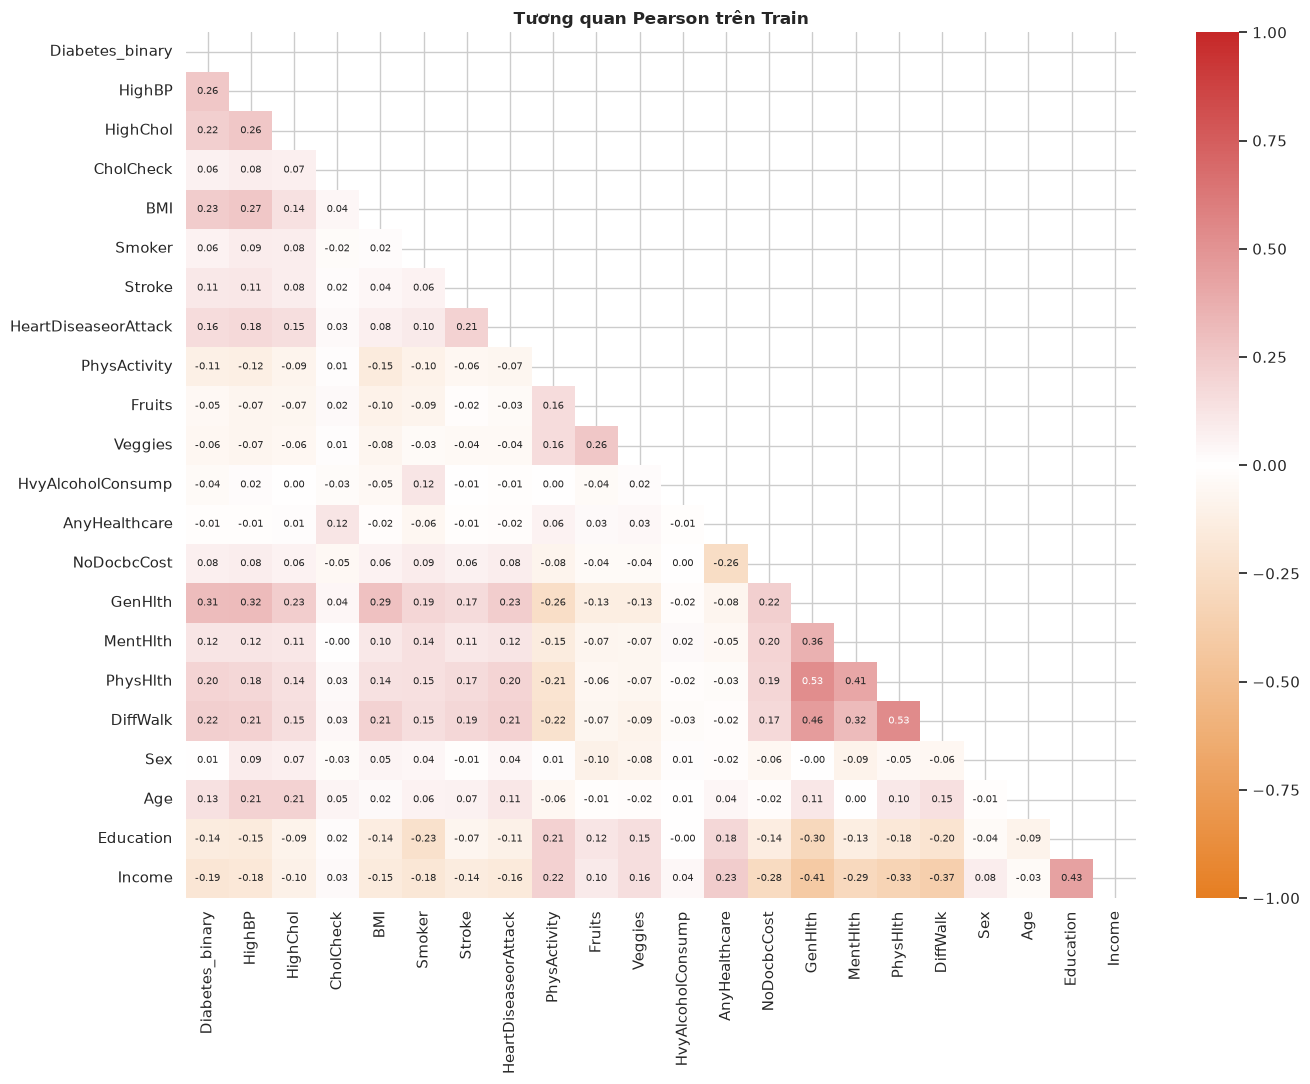

**Quan sát:** **GenHlth** có |Pearson| với nhãn lớn nhất (**r=0.312**). Có **0** cặp đặc trưng đạt |r| > 0,8. Các hệ số mô tả liên hệ từng cặp, không đo đóng góp riêng trong mô hình.

In [10]:
from scipy import stats

correlation_columns = [TARGET] + FEATURES
values = table(f"SELECT {ALL_COLUMNS} FROM train_data ORDER BY row_id").to_numpy(
    dtype=float
)
pearson = np.corrcoef(values, rowvar=False)
spearman = stats.spearmanr(values, axis=0).statistic
DB.execute(
    "CREATE TABLE correlations (feature_a TEXT,feature_b TEXT,Pearson REAL,Spearman REAL,PRIMARY KEY(feature_a,feature_b))"
)
DB.executemany(
    "INSERT INTO correlations VALUES (?,?,?,?)",
    (
        (a, b, float(pearson[i, j]), float(spearman[i, j]))
        for i, a in enumerate(correlation_columns)
        for j, b in enumerate(correlation_columns)
    ),
)
DB.execute(
    f"CREATE VIEW correlation_target AS SELECT f.position,f.Feature,c.Pearson,c.Spearman FROM feature_catalog f JOIN correlations c ON c.feature_a=f.Feature WHERE c.feature_b='{TARGET}'"
)
DB.execute(
    'CREATE VIEW correlation_pairs AS SELECT a.position AS position_a,b.position AS position_b,c.feature_a AS "Feature A",c.feature_b AS "Feature B",c.Pearson FROM correlations c JOIN feature_catalog a ON a.Feature=c.feature_a JOIN feature_catalog b ON b.Feature=c.feature_b WHERE a.position<b.position'
)
mask = np.triu(np.ones(pearson.shape, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    pearson,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=CORRELATION_CMAP,
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7},
    xticklabels=correlation_columns,
    yticklabels=correlation_columns,
    ax=ax,
)
ax.set_title("Tương quan Pearson trên Train")
fig.tight_layout()
save_and_show_figure("eda_09_correlation", fig)
save_table(
    "SELECT Feature,Pearson,Spearman FROM correlation_target ORDER BY position",
    "correlation_target",
)
strongest = records(
    "SELECT * FROM correlation_target ORDER BY ABS(Pearson) DESC,position LIMIT 1"
)[0]
strong_pairs = scalar("SELECT COUNT(*) FROM correlation_pairs WHERE ABS(Pearson)>.8")
note(
    f"**Quan sát:** **{strongest['Feature']}** có |Pearson| với nhãn lớn nhất (**r={strongest['Pearson']:.3f}**). Có **{strong_pairs}** cặp đặc trưng đạt |r| > 0,8. Các hệ số mô tả liên hệ từng cặp, không đo đóng góp riêng trong mô hình."
)


# PART 2: FEATURE ENGINEERING & PREPARATION [3.0 POINTS]

## 2.1. CATEGORICAL ENCODING & FEATURE SCALING

| Nhánh mô hình | Biến số | Mã thứ bậc | Nhị phân | Số cột sau tiền xử lý bộ 21 |
|---|---|---|---|---|
| Logistic Regression | StandardScaler: BMI, MentHlth, PhysHlth | One-Hot drop-first: Age, Education, Income, GenHlth | bool; có thể chuyển 0/1 khi ghép ma trận | 38 |
| Decision Tree, Random Forest, XGBoost | Giữ giá trị gốc | Giữ mã số | bool; có thể chuyển 0/1 khi ghép ma trận | 21 |

Mục này minh họa tiền xử lý cho 21 biến gốc. StandardScaler đổi thang đo, không biến phân bố thành phân bố chuẩn và không loại ngoại lệ. Tên hiển thị trong EDA không thay thế dữ liệu số. Ở Phần 3, scaler/encoder chỉ fit trên Train, sau đó transform Test. Các cây không cần chuẩn hóa cùng thang đo vì phân nhánh theo ngưỡng của từng feature. Bảng demo bên dưới dùng hai phần bên trong Train để kiểm tra fit/transform của preprocessing, chưa huấn luyện mô hình.


In [11]:
def make_preprocessor(feature_set="full_21", family="linear"):
    cols = FEATURE_SETS[feature_set]
    numeric = [c for c in NUMERIC_FEATURES if c in cols]
    ordinal = [c for c in ORDINAL_DOMAINS if c in cols]
    binary = [c for c in cols if c not in numeric + ordinal]

    if family == "linear":
        transforms = [
            ("numeric", StandardScaler(), numeric),
            (
                "ordinal",
                OneHotEncoder(
                    categories=[ORDINAL_DOMAINS[c] for c in ordinal],
                    drop="first",
                    handle_unknown="error",
                    sparse_output=False,
                ),
                ordinal,
            ),
            ("binary", "passthrough", binary),
        ]
    elif family == "tree":
        transforms = [("features", "passthrough", cols)]
    else:
        raise ValueError(f"Family không hợp lệ: {family}")

    return ColumnTransformer(transforms, remainder="drop")


def make_pipeline(model, feature_set="full_21", family="linear"):
    return Pipeline(
        [
            ("preprocess", make_preprocessor(feature_set, family)),
            ("model", clone(model)),
        ]
    )


print("Đã thiết kế xong các Pipeline tiền xử lý độc lập cho họ Tuyến tính và họ Cây!")


Đã thiết kế xong các Pipeline tiền xử lý độc lập cho họ Tuyến tính và họ Cây!


In [ ]:
DB.execute(
    'CREATE TABLE preprocessor_demo (position INTEGER,FeatureSet TEXT,Family TEXT,"Fit rows" INTEGER,"Validation rows" INTEGER,Columns INTEGER)'
)
demo_rows = []
for feature_set_name in ["full_21"]:
    for family in ["linear", "tree"]:
        demo = make_preprocessor(feature_set_name, family)
        fit_data = table(
            f"SELECT {FEATURE_COLUMNS} FROM clean_data JOIN split_manifest USING(row_id) WHERE split='train' AND cv_fold!=0 ORDER BY row_id",
            dtype="int16",
        )
        val_data = table(
            f"SELECT {FEATURE_COLUMNS} FROM clean_data JOIN split_manifest USING(row_id) WHERE split='train' AND cv_fold=0 ORDER BY row_id",
            dtype="int16",
        )
        fit_data[BINARY] = fit_data[BINARY].astype(bool)
        val_data[BINARY] = val_data[BINARY].astype(bool)
        fit_values = demo.fit_transform(fit_data)
        val_values = demo.transform(val_data)
        expected = {
            ("full_21", "linear"): 38,
            ("full_21", "tree"): 21,
        }[(feature_set_name, family)]
        assert fit_values.shape[1] == val_values.shape[1] == expected
        row = (
            len(demo_rows),
            feature_set_name,
            family,
            fit_values.shape[0],
            val_values.shape[0],
            expected,
        )
        demo_rows.append(row)
        DB.execute("INSERT INTO preprocessor_demo VALUES (?,?,?,?,?,?)", row)
display(
    table(
        'SELECT FeatureSet,Family,"Fit rows","Validation rows",Columns FROM preprocessor_demo ORDER BY position'
    )
)
save_table(
    'SELECT FeatureSet,Family,"Fit rows","Validation rows",Columns FROM preprocessor_demo ORDER BY position',
    "preprocessor_demo",
)


## 2.2. BỘ 25 BIẾN ỨNG VIÊN VÀ KIỂM ĐỊNH TRÊN TRAIN

Giữ 21 biến gốc và thêm bốn biến ứng viên:

| Biến | Định nghĩa | Kiểu |
|---|---|---|
| BPCholState | 2×HighBP+HighChol; 0=không cả hai, 1=chỉ HighChol, 2=chỉ HighBP, 3=cả hai | Danh nghĩa, không phải thang mức độ |
| AgeBMI | (Age×5+17)×BMI; tuổi xấp xỉ trung điểm nhóm: 32,37,42,47,52,57 | Số |
| LowEducationLowIncome | Education≤3 và Income≤3: chưa tốt nghiệp THPT và thu nhập hộ dưới 20.000 USD/năm | bool |
| PoorHealthDiffWalk | GenHlth≥4 (Fair/Poor) và DiffWalk=True | bool |

Chỉ dùng 93.329 hồ sơ Train từ manifest gốc. Các biến mới là hàm của các biến gốc; chưa quyết định giữ/bỏ biến hoặc cập nhật mô hình.

**Với nhãn:** Pearson/Spearman trên 24 biến có thứ tự; BPCholState danh nghĩa không tính hai hệ số này. Chi-square và Cramér’s V trên đủ 25 biến; BMI, MentHlth, PhysHlth và AgeBMI được chia tối đa 5 nhóm phân vị riêng trên Train. Welch ANOVA hai nhóm (F=t²) và Cohen’s d cho bốn biến số này. BH điều chỉnh riêng từng họ p-value với nhãn.

**Giữa các biến:** Pearson/Spearman cho 24 biến có thứ tự; Cramér’s V cho 300 cặp (phụ thuộc cách chia nhóm số). VIF dùng ba biến giả cho BPCholState, báo vô hạn nếu phụ thuộc tuyến tính chính xác. Bảng tổng hợp lấy VIF lớn nhất của các biến giả để đại diện BPCholState.

Kiểm định mang tính khám phá trên Train đã dùng EDA, chưa điều chỉnh trọng số/thiết kế khảo sát hoặc phụ thuộc do profile trùng. P hiển thị 0 có thể là giới hạn số học. Không tự động loại biến từ p-value hoặc tương quan. Thống kê bộ 21/18/16 phía sau là đối chiếu cũ, chưa phải quyết định cho bộ 25.


In [ ]:
import importlib.util
candidate25_spec = importlib.util.spec_from_file_location("candidate25_tests", BASE / "candidate25_tests.py")
candidate25_module = importlib.util.module_from_spec(candidate25_spec)
candidate25_spec.loader.exec_module(candidate25_module)
candidate25_summary, candidate25_pairs, candidate25_out = candidate25_module.run_candidate25(DB, FEATURES, TARGET, BASE)
display(Markdown("### Kiểm tra đủ 25 biến"))
display(candidate25_summary.round(5))
display(Markdown("### Bốn biến mới"))
display(candidate25_summary[candidate25_summary["kind"] == "derived"].round(5))
display(Markdown("### Các cặp liên hệ phân loại lớn nhất"))
display(candidate25_pairs.sort_values("cramers_v", ascending=False).head(15).round(5))
from IPython.display import Image
display(Image(filename=str(candidate25_out / "spearman_features.png")))
note("**Nhận xét về cấu trúc:** BPCholState được tạo hoàn toàn từ HighBP/HighChol, nên giữ cùng các biến gốc gây phụ thuộc tuyến tính chính xác khi mã hóa. AgeBMI có thể trùng thông tin mạnh với Age/BMI. Các cờ kết hợp cần được đọc cùng độ lớn hiệu ứng và VIF; chưa chốt giữ/bỏ hoặc huấn luyện mô hình.")


<IPython.core.display.Markdown object>
                  Feature      kind  ...  Chi2_p_BH  Welch_p_BH
0                  HighBP  original  ...    0.00000         NaN
1                HighChol  original  ...    0.00000         NaN
2               CholCheck  original  ...    0.00000         NaN
3                     BMI  original  ...    0.00000         0.0
4                  Smoker  original  ...    0.00000         NaN
5                  Stroke  original  ...    0.00000         NaN
6    HeartDiseaseorAttack  original  ...    0.00000         NaN
7            PhysActivity  original  ...    0.00000         NaN
8                  Fruits  original  ...    0.00000         NaN
9                 Veggies  original  ...    0.00000         NaN
10      HvyAlcoholConsump  original  ...    0.00000         NaN
11          AnyHealthcare  original  ...    0.00002         NaN
12            NoDocbcCost  original  ...    0.00000         NaN
13                GenHlth  original  ...    0.00000         NaN
1

### Phạm vi kiểm định và căn cứ lựa chọn

Giữ manifest gốc chia Train/Test theo nhóm 21 đặc trưng, không đưa nhãn vào khóa nhóm. Bộ 25 và các bộ rút gọn đều xuất phát từ cùng Train. Các kiểm định đơn biến đánh giá từng đặc trưng với nhãn; tương quan giữa X và VIF đánh giá liên hệ, dư thừa và đa cộng tuyến. Không dùng một p-value hoặc một ngưỡng tương quan làm quyết định duy nhất.

Các bảng 21 biến bên dưới là đối chứng cho dữ liệu gốc; phần quyết định cuối ở mục e đã thay thiết kế 21/18/16 cũ bằng bốn bộ 21/25/13/10. EDA và lựa chọn đã dùng toàn Train, nên validation bên trong Train sau đó chỉ là kiểm tra phát triển có ảnh hưởng từ bước lựa chọn trước, không phải xác nhận độc lập.


### c. VIF: kiểm tra phụ thuộc tuyến tính giữa các feature

Tính VIF cho **21 biến X, không đưa nhãn y vào**. Với dữ liệu được định tâm và chuẩn hóa, VIF là đường chéo của nghịch đảo ma trận tương quan giữa X, tương đương hồi quy từng feature theo các feature còn lại có hệ số chặn. Mã thứ bậc vẫn được xem tuyến tính trong phép kiểm tra này, nên VIF chỉ là chỉ báo bổ sung cho phiên bản X số gốc.

,Feature,VIF
0,GenHlth,1.826
1,PhysHlth,1.741
2,DiffWalk,1.612
3,Income,1.595
4,Education,1.339
5,MentHlth,1.307
6,HighBP,1.260
7,NoDocbcCost,1.174
8,BMI,1.164
9,HighChol,1.151


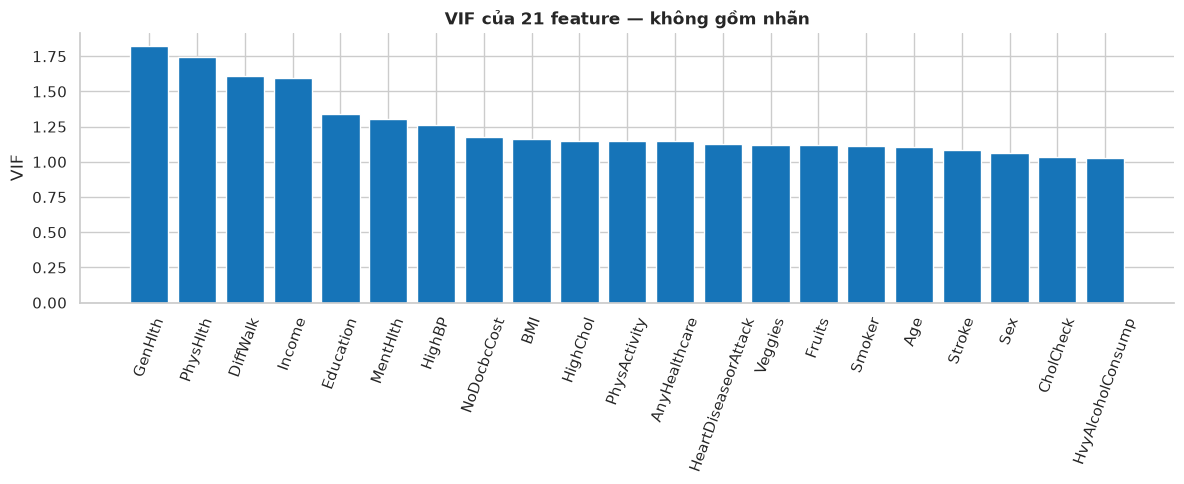

**Nhận xét:** VIF cao nhất là **GenHlth = 1.826**. VIF mô tả phụ thuộc tuyến tính giữa các feature; nhóm không loại biến từ riêng bảng này.

In [13]:
vif_values = X_train.to_numpy(dtype=float)
standardized = (vif_values - vif_values.mean(axis=0)) / vif_values.std(axis=0, ddof=0)
vif_correlation = np.corrcoef(standardized, rowvar=False)
assert np.linalg.matrix_rank(vif_correlation) == len(FEATURES)
vif = np.diag(np.linalg.inv(vif_correlation))
assert np.all(vif >= 1 - 1e-8)
DB.execute("CREATE TABLE vif_results (Feature TEXT PRIMARY KEY,VIF REAL)")
DB.executemany(
    "INSERT INTO vif_results VALUES (?,?)",
    ((feature, float(value)) for feature, value in zip(FEATURES, vif)),
)
VIF_SQL = "SELECT Feature,VIF FROM vif_results ORDER BY VIF DESC,Feature"
display(table(VIF_SQL).round(3))
save_table(VIF_SQL, "ref_vif")
values = records(VIF_SQL)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar([r["Feature"] for r in values], [r["VIF"] for r in values], color=BLUE)
ax.set(title="VIF của 21 feature — không gồm nhãn", ylabel="VIF")
ax.tick_params(axis="x", rotation=70)
fig.tight_layout()
save_and_show_figure("ref_12_vif", fig)
note(
    f"**Nhận xét:** VIF cao nhất là **{values[0]['Feature']} = {values[0]['VIF']:.3f}**. VIF mô tả phụ thuộc tuyến tính giữa các feature; nhóm không loại biến từ riêng bảng này."
)


### d. ANOVA F-score và Chi-square: xếp hạng đơn biến

Tham khảo `SelectKBest`/`f_classif` và `chi2` của notebook nguồn, nhưng giữ tên feature và xuất đầy đủ điểm/rank. ANOVA F-score so sánh trung bình feature giữa hai lớp; với biến rời rạc/nhị phân đây chỉ là xếp hạng khám phá, chưa xác nhận các giả định kiểm định. `chi2` yêu cầu đầu vào không âm; các điểm trên biến số phụ thuộc thang đo nên không được diễn giải như độ quan trọng độc lập. Hai phép tính dùng **X số gốc trước StandardScaler**, chỉ trên Train. P-value chưa tính trọng số/thiết kế khảo sát BRFSS.

,Feature,Pearson,ANOVA_F,ANOVA_p,Chi2_score,Chi2_p,ANOVA_p_BH,Chi2_p_BH,ANOVA_rank,Chi2_rank
0,GenHlth,0.31228,10084.84243,0.00000,4178.37856,0.00000,0.00000,0.00000,1,5
1,HighBP,0.26173,6863.41338,0.00000,4411.50005,0.00000,0.00000,0.00000,2,4
2,BMI,0.23479,5485.64434,0.00000,8932.31082,0.00000,0.00000,0.00000,3,3
3,DiffWalk,0.22212,4843.50659,0.00000,4050.82184,0.00000,0.00000,0.00000,4,6
4,HighChol,0.22004,4748.65387,0.00000,2984.79118,0.00000,0.00000,0.00000,5,7
5,PhysHlth,0.19772,3796.85915,0.00000,64767.01188,0.00000,0.00000,0.00000,6,1
6,Income,-0.19368,3637.26598,0.00000,2316.65237,0.00000,0.00000,0.00000,7,8
7,HeartDiseaseorAttack,0.16058,2470.24265,0.00000,2302.93575,0.00000,0.00000,0.00000,8,9
8,Education,-0.14063,1882.97812,0.00000,333.70360,0.00000,0.00000,0.00000,9,13
9,Age,0.13452,1720.00482,0.00000,747.96251,0.00000,0.00000,0.00000,10,11


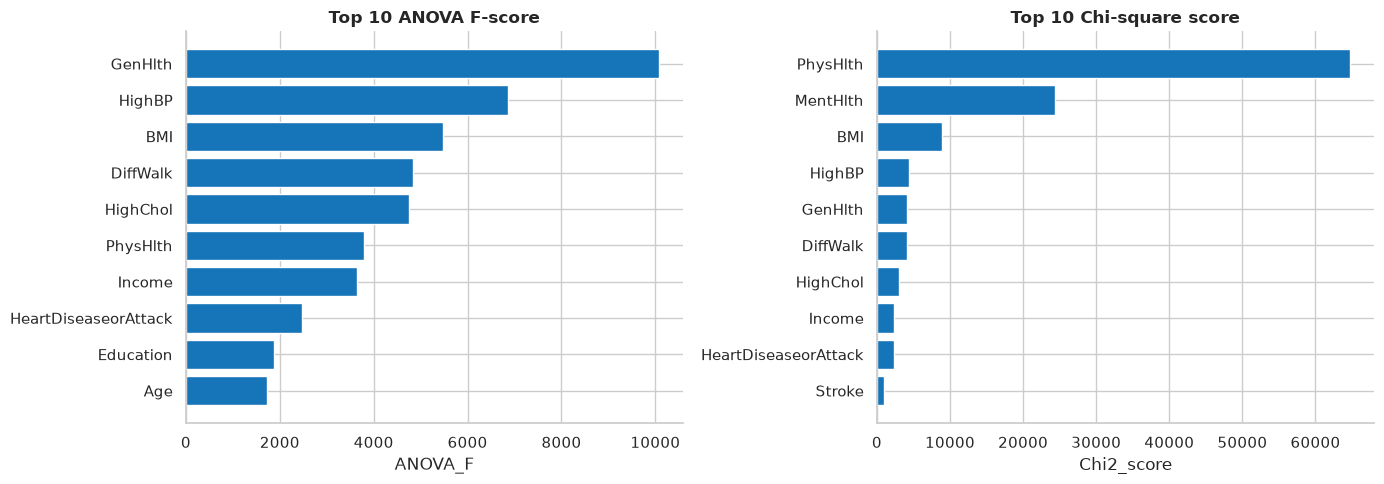

**Nhận xét:** top 5 ANOVA: **GenHlth, HighBP, BMI, DiffWalk, HighChol**; top 5 Chi-square: **PhysHlth, MentHlth, BMI, HighBP, GenHlth**. Nhóm giữ các kiểm định bằng scikit-learn/scipy, lập bảng và xếp hạng bằng SQL. Nhóm không tự động chọn top 16; p nhỏ không chứng minh ý nghĩa thực tiễn lớn.

In [14]:
from sklearn.feature_selection import f_classif, chi2

assert scalar("SELECT MIN(minimum) FROM data_summary WHERE Feature!=?", (TARGET,)) >= 0
f_scores, f_p = f_classif(X_train.to_numpy(), y_train)
chi_scores, chi_p = chi2(X_train.to_numpy(), y_train)
f_bh = stats.false_discovery_control(f_p, method="bh")
chi_bh = stats.false_discovery_control(chi_p, method="bh")
DB.execute(
    "CREATE TABLE feature_tests (Feature TEXT PRIMARY KEY,ANOVA_F REAL,ANOVA_p REAL,Chi2_score REAL,Chi2_p REAL,ANOVA_p_BH REAL,Chi2_p_BH REAL)"
)
DB.executemany(
    "INSERT INTO feature_tests VALUES (?,?,?,?,?,?,?)",
    (
        (
            feature,
            float(f_scores[i]),
            float(f_p[i]),
            float(chi_scores[i]),
            float(chi_p[i]),
            float(f_bh[i]),
            float(chi_bh[i]),
        )
        for i, feature in enumerate(FEATURES)
    ),
)
DB.execute(
    "CREATE VIEW feature_ranking AS SELECT f.position,t.*,c.Pearson,RANK() OVER(ORDER BY ANOVA_F DESC) AS ANOVA_rank,RANK() OVER(ORDER BY Chi2_score DESC) AS Chi2_rank FROM feature_tests t JOIN correlation_target c USING(Feature) JOIN feature_catalog f USING(Feature)"
)
FEATURE_RANKING_SQL = "SELECT Feature,Pearson,ANOVA_F,ANOVA_p,Chi2_score,Chi2_p,ANOVA_p_BH,Chi2_p_BH,ANOVA_rank,Chi2_rank FROM feature_ranking"
display(table(FEATURE_RANKING_SQL + " ORDER BY ANOVA_rank,position").round(5))
save_table(FEATURE_RANKING_SQL + " ORDER BY position", "ref_feature_ranking")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [
    (axes[0], "ANOVA_F", "Top 10 ANOVA F-score"),
    (axes[1], "Chi2_score", "Top 10 Chi-square score"),
]:
    values = records(
        f"SELECT * FROM (SELECT Feature,{metric},position FROM feature_ranking ORDER BY {metric} DESC,position LIMIT 10) ORDER BY {metric},position"
    )
    ax.barh([r["Feature"] for r in values], [r[metric] for r in values], color=BLUE)
    ax.set(title=title, xlabel=metric)
fig.tight_layout()
save_and_show_figure("ref_13_feature_ranking", fig)
anova_top = ", ".join(
    r["Feature"]
    for r in records(
        "SELECT Feature FROM feature_ranking ORDER BY ANOVA_rank,position LIMIT 5"
    )
)
chi_top = ", ".join(
    r["Feature"]
    for r in records(
        "SELECT Feature FROM feature_ranking ORDER BY Chi2_rank,position LIMIT 5"
    )
)
note(
    f"**Nhận xét:** top 5 ANOVA: **{anova_top}**; top 5 Chi-square: **{chi_top}**. Nhóm giữ các kiểm định bằng scikit-learn/scipy, lập bảng và xếp hạng bằng SQL. Nhóm không tự động chọn top 16; p nhỏ không chứng minh ý nghĩa thực tiễn lớn."
)


### e. Lựa chọn feature của nhóm sau EDA và kiểm định

Nhóm xuất phát từ 21 biến, dùng các xu hướng EDA để tạo 4 biến mới thành bộ 25. Kết quả đơn biến (Pearson/Spearman, Chi-square/Cramér’s V, Welch ANOVA và độ lớn hiệu ứng) được đọc cùng tương quan giữa các biến và VIF. Nhóm lựa chọn **replacement_10** làm phương án gọn ưu tiên để kiểm chứng, không gọi đây là bộ tối ưu đã được xác nhận.

| Quyết định | Căn cứ và đánh đổi |
|---|---|
| Thêm AgeBMI, thay Age và BMI | Spearman với nhãn≈0,263; giữ cùng Age/BMI làm VIF AgeBMI≈50,10. Dùng tích thay hai biến giảm dư thừa tuyến tính nhưng mất khả năng phân biệt các cặp tuổi/BMI có cùng tích. Tuổi dùng trung điểm nhóm, không phải tuổi thực. |
| Thêm BPCholState, thay HighBP và HighChol | Cramér’s V với nhãn≈0,313. Bốn trạng thái giữ được đầy đủ hai giá trị nhị phân; tránh giữ đồng thời các biến gốc gây phụ thuộc tuyến tính chính xác. Phải xử lý như phân loại danh nghĩa. |
| Thêm LowEducationLowIncome, thay Education và Income | Cờ kết hợp có Spearman≈0,086, VIF≈1,24 trong bộ 25. Đây là lựa chọn đơn giản hóa của nhóm, không phải bằng chứng cờ tốt hơn hai biến gốc. Mất thông tin các mức học vấn/thu nhập và chênh lệch trong nhóm False. |
| Thêm PoorHealthDiffWalk, thay DiffWalk | Spearman với nhãn≈0,225; tương quan với DiffWalk≈0,764. Giữ GenHlth để biểu diễn tình trạng sức khỏe tổng quát. Cờ làm mất thông tin DiffWalk ở nhóm sức khỏe Excellent/Very good/Good. |
| Bỏ Sex, AnyHealthcare, CholCheck, Smoker, Fruits, Veggies, HvyAlcoholConsump, NoDocbcCost | Tám biến có liên hệ đơn biến với nhãn tương đối nhỏ trong bộ kiểm tra. Đây là giả thuyết rút gọn; chưa chứng minh chúng vô ích hoặc hoàn toàn dư thừa với các biến khác. |
| Giữ Stroke, HeartDiseaseorAttack, PhysActivity, GenHlth, MentHlth, PhysHlth | Giữ thông tin bệnh sử, vận động và sức khỏe. MentHlth có Pearson≈0,125 nhưng Spearman≈0,096; không loại chỉ vì một ngưỡng hệ số tùy chọn. |

**Bốn bộ đối chiếu:** full_21 (21 biến gốc); expanded_25 (21+4); compact_13 (13 biến gốc có liên hệ đáng chú ý); replacement_10 (6 biến gốc+4 biến mới). Bảng dưới liệt kê đủ quyết định cho từng biến.

Bộ 10 giảm số cột và các phụ thuộc gây ra do giữ biến tạo mới cùng biến thành phần. Đổi lại, ba phép kết hợp AgeBMI, LowEducationLowIncome và PoorHealthDiffWalk nén mất thông tin. Chỉ sau so sánh mô hình theo cùng quy trình validation mới đánh giá được đánh đổi này. Chưa có chỉ số mô hình mới cho bốn bộ; các output mô hình cũ ở Part 3 không đại diện cho bộ 25/13/10.


In [ ]:
selection_sets = {
    "full_21": FEATURES.copy(),
    "expanded_25": FEATURES + ["BPCholState", "AgeBMI", "LowEducationLowIncome", "PoorHealthDiffWalk"],
    "compact_13": ["HighBP", "HighChol", "BMI", "Stroke", "HeartDiseaseorAttack", "PhysActivity",
                   "GenHlth", "MentHlth", "PhysHlth", "DiffWalk", "Age", "Education", "Income"],
    "replacement_10": ["Stroke", "HeartDiseaseorAttack", "PhysActivity", "GenHlth", "MentHlth",
                       "PhysHlth", "AgeBMI", "BPCholState", "LowEducationLowIncome", "PoorHealthDiffWalk"],
}
assert [len(v) for v in selection_sets.values()] == [21, 25, 13, 10]
DB.execute("DROP TABLE IF EXISTS group_feature_selection")
DB.execute("CREATE TABLE group_feature_selection (position INTEGER, Feature TEXT, full_21 TEXT, expanded_25 TEXT, compact_13 TEXT, replacement_10 TEXT)")
for position, feature in enumerate(selection_sets["expanded_25"]):
    decisions = ["Giữ" if feature in cols else "Không dùng" for cols in selection_sets.values()]
    DB.execute("INSERT INTO group_feature_selection VALUES (?,?,?,?,?,?)", (position, feature, *decisions))
selection_sql = "SELECT Feature,full_21,expanded_25,compact_13,replacement_10 FROM group_feature_selection ORDER BY position"
display(table(selection_sql))
save_table(selection_sql, "group_feature_selection_21_25_13_10")
selection_manifest = {
    "feature_sets": selection_sets, "group_preferred_candidate": "replacement_10",
    "status": "group_choice_pending_model_validation",
    "selection_data": "original Train only; EDA-informed selection on all Train",
    "nominal_features": ["BPCholState"], "excluded_from_X": ["row_id", TARGET],
}
(candidate25_out / "group_feature_selection.json").write_text(
    json.dumps(selection_manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

# Check whether replacing component features removes the observed collinearity.
replacement_data = table("SELECT " + ",".join(ident(c) for c in selection_sets["replacement_10"]) + " FROM candidate25_train ORDER BY row_id")
replacement_encoded = pd.get_dummies(
    replacement_data, columns=["BPCholState"], drop_first=True, dtype=float
).astype(float)
replacement_z = (replacement_encoded.to_numpy() - replacement_encoded.mean().to_numpy()) / replacement_encoded.std(ddof=0).to_numpy()
replacement_vif_rows = []
for j, feature in enumerate(replacement_encoded.columns):
    other_columns = np.delete(replacement_z, j, axis=1)
    residual = replacement_z[:, j] - other_columns @ np.linalg.lstsq(other_columns, replacement_z[:, j], rcond=None)[0]
    fraction = float(residual @ residual / (replacement_z[:, j] @ replacement_z[:, j]))
    replacement_vif_rows.append((feature, np.inf if fraction < 1e-12 else 1 / fraction))
DB.execute("DROP TABLE IF EXISTS replacement10_vif")
DB.execute("CREATE TABLE replacement10_vif (EncodedFeature TEXT, VIF REAL)")
DB.executemany("INSERT INTO replacement10_vif VALUES (?,?)", replacement_vif_rows)
display(Markdown("### VIF sau khi thay biến thành phần — bộ 10"))
display(table("SELECT * FROM replacement10_vif ORDER BY VIF DESC").round(4))
save_table("SELECT * FROM replacement10_vif ORDER BY VIF DESC", "replacement10_vif")
replacement_vif_max = max(v for _, v in replacement_vif_rows)
note(f"**Kết quả:** VIF lớn nhất của bộ 10 sau mã hóa là **{replacement_vif_max:.3f}**. Đây là kiểm tra đa cộng tuyến trên Train; chưa đo hiệu quả dự đoán của bộ biến.")


                  Feature     full_21 expanded_25  compact_13 replacement_10
0                  HighBP         Giữ         Giữ         Giữ     Không dùng
1                HighChol         Giữ         Giữ         Giữ     Không dùng
2               CholCheck         Giữ         Giữ  Không dùng     Không dùng
3                     BMI         Giữ         Giữ         Giữ     Không dùng
4                  Smoker         Giữ         Giữ  Không dùng     Không dùng
5                  Stroke         Giữ         Giữ         Giữ            Giữ
6    HeartDiseaseorAttack         Giữ         Giữ         Giữ            Giữ
7            PhysActivity         Giữ         Giữ         Giữ            Giữ
8                  Fruits         Giữ         Giữ  Không dùng     Không dùng
9                 Veggies         Giữ         Giữ  Không dùng     Không dùng
10      HvyAlcoholConsump         Giữ         Giữ  Không dùng     Không dùng
11          AnyHealthcare         Giữ         Giữ  Không dùng     Không dùng

**STUDENT COMMENTS — 2.2:** Nhóm đã chốt bốn bộ full_21, expanded_25, compact_13 và replacement_10 để đối chiếu. Bộ 10 là lựa chọn gọn của nhóm từ EDA và kiểm định; hiệu quả dự đoán được báo cáo riêng trong Part 3. Các nhóm split vẫn khóa trên 21 feature gốc; có thể có profile trùng trên bộ rút gọn giữa các nhóm gốc.

### f. Xử lý mất cân bằng bằng trọng số lớp

Lượt huấn luyện theo yêu cầu gồm đúng 32 cấu hình có trọng số. Logistic Regression, Decision Tree và Random Forest dùng class_weight="balanced"; XGBoost dùng scale_pos_weight=n0/n1 từ đúng Train đang fit. Trọng số mỗi lớp của scikit-learn là N/(2*n_class). Đây là trọng số huấn luyện, khác trọng số khảo sát.

Baseline cũ hiển thị riêng tại Part 3; các bảng mô hình cũ có trọng số và mốc đa số không tạo thành đối chứng không trọng số tương ứng cho 32 cấu hình mới. Vì vậy lượt này chưa cô lập tác động riêng của class weighting.


# PART 3: MODEL BUILDING & EVALUATION [3.0 POINTS]

## 3.1. Tám trường hợp dữ liệu và feature

Bốn bộ **full_21, expanded_25, compact_13, replacement_10** × hai bản **giữ/bỏ duplicate** × bốn mô hình **Logistic Regression, Decision Tree, Random Forest, XGBoost** = **32 cấu hình có trọng số**. Các bộ biến được khóa từ mục 2.2 trước lượt huấn luyện này.

Giữ tham số mô hình cũ: LR C=1, max_iter=1500; DT depth=8, min_leaf=50; RF 100 cây, depth=16, min_leaf=20; XGB 100 cây, depth=6, learning_rate=0.1; seed=42. LR/DT/RF dùng class_weight=balanced; XGB dùng n0/n1 từ đúng Train. Không chạy thêm lượt fit baseline.

Loại duplicate theo đủ 21 biến gốc và nhãn trước khi chọn/tạo feature; giữ cùng membership Train/Test gốc. Bản không duplicate có Train 82.258/Test 20.568; bản giữ duplicate có Train 93.329/Test 23.333. Đánh giá thêm trên cùng Test 20.568 để đối chiếu cấu hình.

BPCholState là biến danh nghĩa, mã hóa one-hot bỏ một mức cho cả bốn mô hình. LR chuẩn hóa BMI/MentHlth/PhysHlth/AgeBMI và one-hot biến thứ bậc; mô hình cây giữ giá trị số/thứ bậc. Pipeline chỉ fit trên Train. Báo số feature khái niệm và số cột sau mã hóa riêng.

Dùng predict với ngưỡng mặc định 0.5; Accuracy toàn tập, Precision/Recall/F1 cho nhãn 1. Test đã từng được xem và các bộ biến dựa trên EDA toàn Train, nên kết quả là đối chiếu khám phá, không phải xác nhận độc lập hay lựa chọn lại feature từ Test.

**Baseline cũ:** bảng lịch sử được lưu tại historical_project_baseline/. Các điểm mô hình cũ là có trọng số, làm tròn 4 chữ số; mốc luôn đoán lớp 0 cũng giữ riêng. Không có bảng mô hình không trọng số cũ có thể xác minh trong repository hiện tại.


In [ ]:
import importlib.util
weighted32_spec = importlib.util.spec_from_file_location("train_weighted32", BASE / "train_weighted32.py")
weighted32_module = importlib.util.module_from_spec(weighted32_spec)
weighted32_spec.loader.exec_module(weighted32_module)
weighted32_context = weighted32_module.prepare(DB, selection_sets, BASE, SEED)
RESULTS = weighted32_context["out"]
display(weighted32_context["weights"].round(6))


           Dataset  TrainRows  ...  BalancedWeight1  NegativePositiveRatio
0  keep_duplicates      93329  ...         4.578542               8.157084
1    no_duplicates      82258  ...         4.050522               7.101044

[2 rows x 7 columns]


## 3.2. Huấn luyện 32 cấu hình có trọng số

Mỗi cấu hình fit đúng một lần trên Train tương ứng. Lưu pipeline, xác suất, dự đoán và trọng số thực dùng. Sau mỗi fit ghi tiến độ và metrics. Không ghi đè model đã chạy; cell huấn luyện cần được chạy có chủ đích vì thực hiện 32 lượt fit.

Các điểm lấy từ số đếm confusion matrix bằng SQLite và được kiểm tra độc lập bằng scikit-learn; giữ kết quả native/common tách biệt.


In [ ]:
if (RESULTS / "verification.json").is_file():
    weighted32_results = pd.read_csv(RESULTS / "all_metrics.csv")
    print("Đọc lại 32 cấu hình đã được kiểm chứng; không fit lại.")
else:
    weighted32_results = weighted32_module.train32(weighted32_context)


Completed 32 weighted fits. Full progress and parameters are stored in weighted_32_results/.


## 3.3. Kết quả 32 cấu hình và mốc cũ của dự án

Tám bảng Test tương ứng và bảng đủ 32 cấu hình trên Test chung. Các điểm mô tả kết quả, không dùng để thay đổi bộ feature đã khóa. Baseline đa số và bảng mô hình cũ hiển thị riêng với loại trọng số, nguồn và độ chính xác số đã lưu.


<IPython.core.display.Markdown object>
                 Model  Accuracy  Precision  Recall      F1
33        DecisionTree    0.7318     0.2611  0.7956  0.3932
35  LogisticRegression    0.7606     0.2820  0.7705  0.4129
37        RandomForest    0.7621     0.2848  0.7791  0.4171
39             XGBoost    0.7626     0.2839  0.7709  0.4150
<IPython.core.display.Markdown object>
                 Model  Accuracy  Precision  Recall      F1
41        DecisionTree    0.7279     0.2799  0.7653  0.4098
43  LogisticRegression    0.7465     0.2943  0.7534  0.4233
45        RandomForest    0.7516     0.2999  0.7586  0.4299
47             XGBoost    0.7512     0.2985  0.7523  0.4274
<IPython.core.display.Markdown object>
                 Model  Accuracy  Precision  Recall      F1
17        DecisionTree    0.7236     0.2544  0.7925  0.3851
19  LogisticRegression    0.7636     0.2850  0.7713  0.4162
21        RandomForest    0.7638     0.2854  0.7729  0.4168
23             XGBoost    0.7628     0.2840

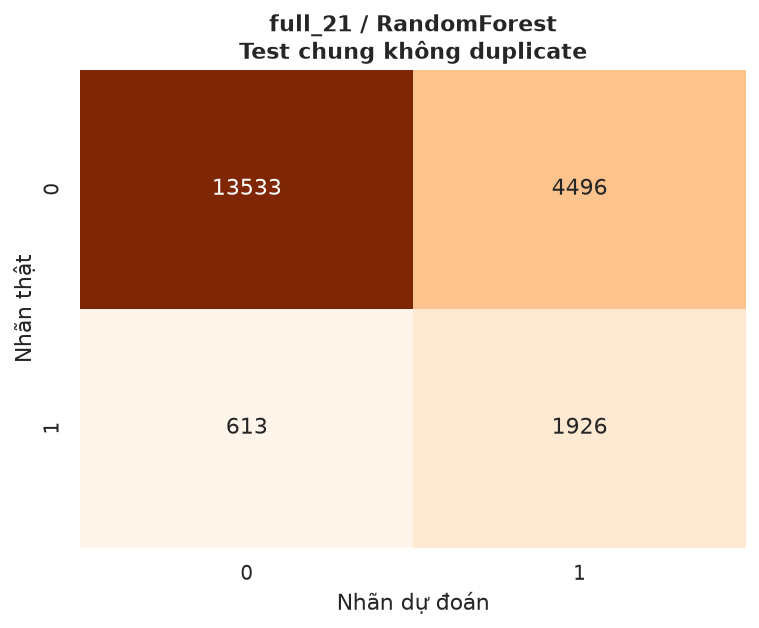

In [ ]:
metric_cols32 = ["Model", "Accuracy", "Precision", "Recall", "F1"]
for feature_set in selection_sets:
    for dataset in ["keep_duplicates", "no_duplicates"]:
        display(Markdown(f"### {feature_set} / {dataset} — Test tương ứng"))
        rows32 = weighted32_results[
            (weighted32_results.FeatureSet == feature_set) &
            (weighted32_results.Dataset == dataset) &
            (weighted32_results.TestView == "native")
        ]
        assert len(rows32) == 4
        display(rows32[metric_cols32].round(4))
display(Markdown("### Đủ 32 cấu hình — cùng Test không duplicate"))
common32 = weighted32_results[weighted32_results.TestView == "common"].copy()
with pd.option_context("display.max_rows", 40, "display.max_columns", None):
    display(common32[["FeatureSet", "Dataset", "Model", "Accuracy", "Precision", "Recall", "F1"]].round(4))

display(Markdown("### Baseline cũ: luôn dự đoán lớp đông nhất"))
historical_baseline = pd.read_csv(BASE / "historical_project_baseline" / "historical_majority_baseline.csv")
display(historical_baseline.round(4))
display(Markdown("### Mô hình 21 biến cũ của dự án — có trọng số, điểm lưu làm tròn"))
historical_models = pd.read_csv(BASE / "historical_project_baseline" / "historical_native_metrics.csv")
display(historical_models[historical_models.FeatureSet == "full_21"].round(4))
note("Mốc đa số không phải baseline mô hình không trọng số tương ứng. Bảng mô hình cũ là kết quả weighted trong notebook gốc; lượt này không chạy 32 cấu hình unweighted nên chưa cô lập tác động của trọng số.")

best32 = common32.sort_values(["F1", "Precision", "Config"], ascending=[False, False, True]).iloc[0]
note(f"**Mô tả trên Test chung:** F1 cao nhất trong lượt này là **{best32['F1']:.6f}**, cấu hình **{best32['Config']}**, Precision **{best32['Precision']:.6f}**, Recall **{best32['Recall']:.6f}**. Đây là cực đại quan sát sau đối chiếu 32 cấu hình trên Test đã xem, không phải bằng chứng lựa chọn độc lập.")
display(Markdown("### Confusion matrix — cấu hình F1 cao nhất theo mô tả"))
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(np.array([[best32["TN"], best32["FP"]], [best32["FN"], best32["TP"]]], dtype=int),
            annot=True, fmt="d", cmap="Oranges", cbar=False,
            xticklabels=["0", "1"], yticklabels=["0", "1"], ax=ax)
ax.set(xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title=f"{best32['FeatureSet']} / {best32['Model']}\nTest chung không duplicate")
fig.tight_layout()
save_and_show_figure("weighted32_confusion_common", fig)


In [ ]:
weighted32_verification = weighted32_module.verify_saved(weighted32_context)
display(weighted32_verification)
print("Đã xác minh đủ 32 cấu hình, 64 dòng metrics native/common và dự đoán đã lưu.")


{'status': 'passed', 'configurations': 32, 'metric_rows': 64, 'test_rows': 23333, 'common_test_rows': 20568, 'saved_predictions_verified': True, 'model_files': 32}
Đã xác minh đủ 32 cấu hình, 64 dòng metrics native/common và dự đoán đã lưu.


## 3.4. Đối chứng NearMiss trên Train — bộ 10 feature

NearMiss-1, 3 láng giềng, tỷ lệ nhãn 1/0 sau lấy mẫu =1.0. Khoảng cách Euclid tính trên biến số đã chuẩn hóa và biến phân loại đã mã hóa bằng riêng Train; không đưa nhãn vào khoảng cách. Chọn mẫu riêng cho Train giữ duplicate và Train bỏ duplicate, dùng cùng các mẫu được chọn cho bốn mô hình.

Train giữ duplicate giảm từ 93.329 xuống 20.384 (10.192/10.192); Train bỏ duplicate giảm từ 82.258 xuống 20.308 (10.154/10.154). Giữ đủ mọi ca dương của đúng Train. Test 23.333 và Test chung 20.568 không resample, không đổi nhãn hoặc membership.

Chạy thêm 8 fit với cùng tham số và bộ 10 như lượt weighted32, ngưỡng mặc định 0.5. Trọng số tính lại từ tập sau lấy mẫu: balanced=1 cho hai lớp, XGB scale_pos_weight=1. Vì thế đối chiếu với weighted10 đo toàn bộ phương án NearMiss+cách tính lại trọng số, chưa cô lập tác động lấy mẫu nếu giữ nguyên trọng số cũ.

Kết quả trên Test chung: NearMiss làm F1 giảm ở cả tám đối chiếu, khoảng 0,227–0,284 thay vì 0,408–0,421. Recall thường tăng nhưng Precision giảm mạnh, cho thấy mô hình dự đoán nhãn 1 quá nhiều trên phân bố Test gốc. Đây là kết quả mô tả trên Test đã xem; không đổi lựa chọn bộ feature hoặc tự tiếp tục tìm phiên bản/ngưỡng trên Test.

Baseline weighted10 được đọc từ lượt 32 cấu hình, không fit lại. Lưu riêng model, mẫu Train được chọn, xác suất, dự đoán và kiểm tra tại nearmiss_10_results/.


In [ ]:
import importlib.util
nearmiss10_out = BASE / "nearmiss_10_results"
if not (nearmiss10_out / "verification.json").is_file():
    nearmiss10_spec = importlib.util.spec_from_file_location("train_nearmiss10", BASE / "train_nearmiss10.py")
    nearmiss10_module = importlib.util.module_from_spec(nearmiss10_spec)
    nearmiss10_spec.loader.exec_module(nearmiss10_module)
    nearmiss10_metrics, nearmiss10_comparison, nearmiss10_counts, nearmiss10_out = nearmiss10_module.run(DB, BASE, SEED)
else:
    nearmiss10_metrics = pd.read_csv(nearmiss10_out / "all_metrics.csv")
    nearmiss10_comparison = pd.read_csv(nearmiss10_out / "comparison_with_weighted10.csv")
    nearmiss10_counts = pd.read_csv(nearmiss10_out / "train_counts.csv")
display(Markdown("### Số hồ sơ Train trước và sau NearMiss"))
display(nearmiss10_counts)
display(Markdown("### Đối chiếu cùng Test không duplicate — bộ 10"))
with pd.option_context("display.max_columns", None):
    display(nearmiss10_comparison[nearmiss10_comparison.TestView == "common"][
        ["Dataset", "Model", "Precision_Weighted", "Precision_NearMiss", "Recall_Weighted",
         "Recall_NearMiss", "F1_Weighted", "F1_NearMiss", "Delta_F1"]
    ].round(6))
display(Markdown("### NearMiss trên Test tương ứng"))
display(nearmiss10_metrics[nearmiss10_metrics.TestView == "native"][
    ["Dataset", "Model", "TestRows", "Accuracy", "Precision", "Recall", "F1"]
].round(6))
display(json.loads((nearmiss10_out / "verification.json").read_text(encoding="utf-8")))


## 3.5. Đối chứng SMOTE cho bộ 10 — SMOTENC trên riêng Train

Bộ 10 có biến số, bool và BPCholState danh nghĩa, nên dùng SMOTENC (k=5, seed=42) thay cho nội suy SMOTE thuần trên mã phân loại. Tạo thêm ca dương trên riêng Train để đạt 1:1; Test tương ứng và Test chung giữ nguyên.

Chuẩn hóa AgeBMI/MentHlth/PhysHlth bằng riêng Train để tính láng giềng; các biến còn lại là phân loại. GenHlth và PoorHealthDiffWalk được mã hóa chung trong bước lấy mẫu rồi giải mã, giữ các tổ hợp hợp lệ và tránh tạo cờ khó đi lại+sức khỏe kém trong nhóm GenHlth Excellent/Very good/Good. Dữ liệu sau lấy mẫu vẫn có đúng 10 feature cho mô hình. Số ngày tổng hợp có thể là số thập phân do nội suy, không tự làm tròn; các mẫu là dữ liệu tổng hợp, không phải người tham gia mới.

Train giữ duplicate: 93.329→166.274 (83.137/83.137), thêm 72.945 ca dương tổng hợp. Train bỏ duplicate: 82.258→144.208 (72.104/72.104), thêm 61.950 ca dương tổng hợp. Giữ đủ mọi hồ sơ Train gốc; categorical giữ miền giá trị gốc. Các biến kết hợp tổng hợp không được coi là khôi phục được các giá trị thành phần đã bỏ.

Tám lượt fit mới, giữ tham số mô hình, ngưỡng 0.5 và mã hóa mô hình như lượt 32 cấu hình. Trọng số sau resample 1:1 bằng 1; phép đối chiếu weighted10 đo toàn bộ phương án resampling+cách tính lại trọng số. Không fit lại các mốc weighted/NearMiss.

Trên Test chung 20.568, RF và XGB tăng F1 ở cả hai bản Train; LR/DT giảm nhẹ. RF/Train bỏ duplicate có F1 SMOTENC=0,430830 so weighted RF=0,420809, delta=+0,010021. Đây là chênh lệch quan sát trên Test đã xem, chưa có ước lượng độ bất định và không chứng minh SMOTENC luôn tốt hơn. Không dùng kết quả để tự tune thêm trên Test.


In [ ]:
import importlib.util
smotenc10_out = BASE / "smotenc_10_results"
if not (smotenc10_out / "verification.json").is_file():
    smotenc10_spec = importlib.util.spec_from_file_location("train_smotenc10", BASE / "train_smotenc10.py")
    smotenc10_module = importlib.util.module_from_spec(smotenc10_spec)
    smotenc10_spec.loader.exec_module(smotenc10_module)
    smotenc10_metrics, smotenc10_comparison, smotenc10_counts, smotenc10_out = smotenc10_module.run(DB, BASE, SEED)
else:
    smotenc10_metrics = pd.read_csv(smotenc10_out / "all_metrics.csv")
    smotenc10_comparison = pd.read_csv(smotenc10_out / "comparison_with_weighted10.csv")
    smotenc10_counts = pd.read_csv(smotenc10_out / "train_counts.csv")
display(Markdown("### Train trước và sau SMOTENC"))
display(smotenc10_counts)
display(Markdown("### Đối chiếu SMOTENC với weighted — Test chung"))
with pd.option_context("display.max_columns", None):
    display(smotenc10_comparison[smotenc10_comparison.TestView == "common"][
        ["Dataset", "Model", "Precision_Weighted", "Precision_SMOTENC",
         "Recall_Weighted", "Recall_SMOTENC", "F1_Weighted", "F1_SMOTENC", "Delta_F1"]
    ].round(6))
nearmiss_saved10 = pd.read_csv(BASE / "nearmiss_10_results" / "all_metrics.csv")
three_methods10 = smotenc10_comparison.merge(
    nearmiss_saved10[["Dataset", "Model", "TestView", "F1"]].rename(columns={"F1": "F1_NearMiss"}),
    on=["Dataset", "Model", "TestView"], validate="one_to_one"
)
three_methods10.to_csv(smotenc10_out / "comparison_three_methods.csv", index=False)
display(Markdown("### F1 của cả ba phương án — cùng bộ 10, cùng Test chung"))
display(three_methods10[three_methods10.TestView == "common"][
    ["Dataset", "Model", "F1_Weighted", "F1_NearMiss", "F1_SMOTENC"]
].round(6))
display(Markdown("### SMOTENC trên Test tương ứng"))
display(smotenc10_metrics[smotenc10_metrics.TestView == "native"][
    ["Dataset", "Model", "TestRows", "Accuracy", "Precision", "Recall", "F1"]
].round(6))
display(json.loads((smotenc10_out / "verification.json").read_text(encoding="utf-8")))


## 3.6. Đối chiếu weighted / NearMiss / SMOTENC — bộ 10, 13, 16, 18, 21

Tổng hợp **120 cấu hình** = 5 bộ × 3 phương án × 2 bản Train × 4 mô hình; mỗi cấu hình có metrics trên Test tương ứng và Test chung. Tái dùng 40 cấu hình đã lưu đầy đủ số, chạy thêm đúng 80 cấu hình còn thiếu. Không dùng các điểm lịch sử làm tròn để thay thế baseline trong bảng này.

| Bộ | Định nghĩa |
|---|---|
| 10 | replacement_10: 6 biến gốc + 4 biến mới theo lựa chọn nhóm |
| 13 | compact_13 đã thống nhất, gồm MentHlth |
| 16 | reduced_16 cũ: bỏ Fruits, Veggies, Sex, CholCheck, AnyHealthcare khỏi 21 |
| 18 | reduced_18 cũ: bỏ Stroke, Sex, PhysHlth khỏi 21; không phải bộ thay thế trung gian 18 |
| 21 | Toàn bộ biến gốc |

Giữ tham số mô hình, seed42 và ngưỡng0.5 như các lượt trước. Weighted tính trọng số từ đúng Train gốc. NearMiss-1/k3 và SMOTENC/k5 chỉ xử lý Train, cân bằng1:1 nên trọng số tính lại bằng1. Khoảng cách dùng biến số chuẩn hóa và biến phân loại mã hóa trên riêng Train. GenHlth và các mã thứ bậc được xử lý phân loại trong SMOTENC; bộ10 dùng joint GenHlth/PoorHealthDiffWalk đã mô tả ở3.5. Ngày sức khỏe tổng hợp có thể thập phân.

Các bảng chính đều dùng **cùng Test không duplicate n=20.568**; bản Train giữ/bỏ duplicate hiển thị riêng. File native_comparison_wide.csv lưu đối chiếu trên Test tương ứng. Accuracy/Precision/Recall/F1 đầy đủ trong all_metrics.csv và hai bảng wide. Delta tính phương án resampling trừ weighted ở đúng bộ feature/model/bản Train.

Test đã xem; các bảng mô tả kết quả nghiên cứu phát triển, chưa có CI hay xác nhận độc lập. Resampling và trọng số sau resampling cùng thay đổi nên không diễn giải delta là tác động lấy mẫu đơn thuần. Không dùng các cực đại quan sát để tự chọn lại feature/ngưỡng.


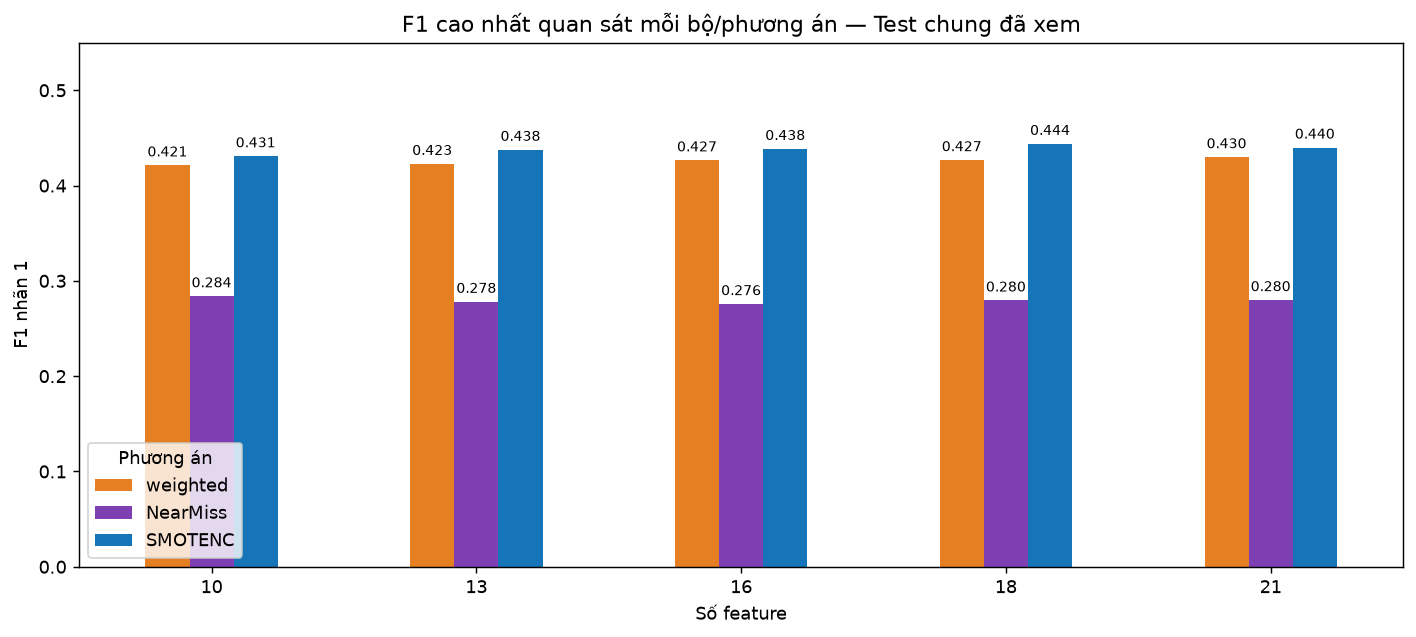

In [ ]:
comparison5_out = BASE / "comparison_10_13_16_18_21"
if not (comparison5_out / "verification.json").is_file():
    comparison5_spec = importlib.util.spec_from_file_location("compare_resampling_five_sets", BASE / "compare_resampling_five_sets.py")
    comparison5_module = importlib.util.module_from_spec(comparison5_spec)
    comparison5_spec.loader.exec_module(comparison5_module)
    comparison5_module.run(DB, BASE, FEATURES, SEED)
comparison5_all = pd.read_csv(comparison5_out / "all_metrics.csv")
comparison5_wide = pd.read_csv(comparison5_out / "common_comparison_wide.csv")
assert comparison5_all.Config.nunique() == 120 and len(comparison5_wide) == 40
for feature_count in [10, 13, 16, 18, 21]:
    display(Markdown(f"### Bộ {feature_count} — F1 và chênh lệch trên Test chung"))
    display(comparison5_wide[comparison5_wide.Features == feature_count][
        ["Dataset", "Model", "F1_weighted", "F1_NearMiss", "F1_SMOTENC", "Delta_F1_NearMiss", "Delta_F1_SMOTENC"]
    ].round(6))
    for dataset in ["keep_duplicates", "no_duplicates"]:
        display(Markdown(f"**Precision / Recall / F1 — {feature_count} biến, {dataset}**"))
        with pd.option_context("display.max_columns", None):
            display(comparison5_wide[
                (comparison5_wide.Features == feature_count) & (comparison5_wide.Dataset == dataset)
            ][["Model"] + [f"{metric}_{method}" for method in ["weighted", "NearMiss", "SMOTENC"]
                          for metric in ["Precision", "Recall", "F1"]]].round(6))
comparison5_best = (
    comparison5_all[comparison5_all.TestView == "common"]
    .sort_values(["F1", "Config"], ascending=[False, True])
    .groupby(["Features", "Method"], sort=False).head(1)
    .sort_values(["Features", "Method"])
)
comparison5_best.to_csv(comparison5_out / "best_observed_by_feature_method.csv", index=False)
display(Markdown("### F1 cao nhất quan sát mỗi bộ/phương án — mô hình và bản Train có thể khác nhau"))
display(comparison5_best[["Features", "Method", "Dataset", "Model", "Precision", "Recall", "F1"]].round(6))
plot5 = comparison5_best.pivot(index="Features", columns="Method", values="F1")[["weighted", "NearMiss", "SMOTENC"]]
ax = plot5.plot.bar(figsize=(11, 5), color=[ORANGE, PURPLE, BLUE], rot=0)
ax.set(title="F1 cao nhất quan sát mỗi bộ/phương án — Test chung đã xem",
       xlabel="Số feature", ylabel="F1 nhãn 1", ylim=(0, 0.55))
ax.legend(title="Phương án")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
fig = ax.figure
fig.tight_layout()
save_and_show_figure("comparison5_best_observed_f1", fig)
display(Markdown(
    "**Nhận xét đối chiếu từng cấu hình:** NearMiss giảm F1 ở cả 40/40 cặp so với weighted; SMOTENC tăng F1 ở 20/40 cặp. "
    "SMOTENC không cải thiện đồng đều mọi mô hình. F1 cao nhất quan sát trong bảng là 0,443787 ở XGBoost/reduced_18/Train giữ duplicate, "
    "Precision 0,397568 và Recall 0,502166. Đây là thống kê sau đối chiếu trên Test đã xem, chưa phải cấu hình được xác nhận tối ưu."
))
display(json.loads((comparison5_out / "verification.json").read_text(encoding="utf-8")))


## 3.7. Confusion matrix của cấu hình Recall và F1-score cao nhất — xét cả 24 cấu hình cũ

Xét 120 bản ghi cấu hình mới và 24 bản ghi lịch sử trên cùng Test không duplicate 20.568 hồ sơ (18.029 nhãn0; 2.539 nhãn1). Hai lượt có một số thiết kế trùng nhau; 144 là số bản ghi kết quả được xét, không phải 144 thiết kế khác nhau.

Các điểm lịch sử làm tròn4chữsố. Đã kiểm tra biên làm tròn tối đa≈0,00005 vẫn không thay đổi hai vị trí dẫn đầu; cả hai đều từ lượt mới có dự đoán đầy đủ. Confusion matrix tính trực tiếp từ dự đoán lưu và đối chiếu bằng scikit-learn, không suy ra số đếm từ tỷ lệ làm tròn và không fit lại.

**Recall cao nhất:** XGBoost/reduced_18/NearMiss/Train giữ duplicate: Recall0,915715, Precision0,140187, F1=0,243150. Phát hiện2.325 ca nhãn1, bỏ sót214, nhưng dự đoán dương sai14.260 ca nhãn0.

**F1-score cao nhất:** XGBoost/reduced_18/SMOTENC/Train giữ duplicate: F1=0,443787, Precision0,397568, Recall0,502166. Phát hiện1.275 ca nhãn1, bỏ sót1.264; dự đoán dương sai1.932 ca nhãn0.

Mỗi ma trận có hàng là nhãn thật, cột là nhãn dự đoán; cùng thang màu. NearMiss bắt được nhiều nhãn1 nhưng gắn nhãn dương cho phần lớn hồ sơ; SMOTENC cân bằng Precision/Recall tốt hơn theo F1 nhưng bỏ sót nhiều nhãn1 hơn. Đây là mô tả cực đại trên Test đã xem, chưa phải lựa chọn tối ưu được xác nhận độc lập.


In [ ]:
import importlib.util
priority144_spec = importlib.util.spec_from_file_location("confusion_priority144", BASE / "confusion_priority144.py")
priority144_module = importlib.util.module_from_spec(priority144_spec)
priority144_spec.loader.exec_module(priority144_module)
priority144_leaders, priority144_image, priority144_out = priority144_module.run(BASE)
display(priority144_leaders[
    ["Priority", "Features", "Dataset", "Method", "Model", "TN", "FP", "FN", "TP", "Precision", "Recall", "F1"]
].round(6))
from IPython.display import Image
display(Image(filename=str(priority144_image)))
display(json.loads((priority144_out / "verification.json").read_text(encoding="utf-8")))


# PART 4: DISCUSSION, CONCLUSION & RECOMMENDATIONS [1.0 POINT]

Lượt chạy Part 3 đã hoàn tất 32 cấu hình có trọng số từ bốn bộ feature 21/25/13/10, hai cách giữ/bỏ duplicate và bốn mô hình. Trên cùng Test không duplicate gồm 20.568 hồ sơ, Random Forest full_21/Train không duplicate có F1 cao nhất quan sát: 0,429863, Precision 0,299907, Recall 0,758566. Decision Tree full_21/Train giữ duplicate có Recall cao nhất: 0,796770, Precision 0,265033, F1 0,397759.

Theo F1 cao nhất quan sát trong từng bộ, expanded_25 đạt 0,427799; compact_13 đạt 0,422781; replacement_10 đạt 0,421252. Các cực đại này là thống kê mô tả sau 32 phép đối chiếu trên Test đã xem, chưa có ước lượng độ bất định hoặc xác nhận độc lập. Không dùng thứ hạng này để tự động sửa bộ feature của nhóm.

Bộ 10 giảm số câu hỏi/feature và loại phụ thuộc tuyến tính do giữ feature tạo mới cùng biến thành phần, nhưng các phép kết hợp làm mất thông tin chi tiết. Kết quả hiện chưa cho thấy bộ 25 hoặc bộ 10 vượt bộ 21 trong lượt đối chiếu này. Các kết quả feature selection phải được kiểm chứng trong quy trình Train/Validation phù hợp.

Các bảng baseline dự án được bảo tồn riêng: điểm mô hình lịch sử có trọng số, làm tròn 4 chữ số, và mốc luôn đoán lớp 0. Mốc đa số trên Test chung đạt Accuracy 0,8766 nhưng Precision/Recall/F1 nhãn 1 bằng 0. Lượt này chỉ fit 32 cấu hình weighted nên chưa đo tác động trọng số bằng đối chứng unweighted tương ứng. Phiên bản thư viện và thứ tự cột sau preprocessing có thể ảnh hưởng điểm so với output cũ.

Giữ/loại duplicate là phân tích độ nhạy; profile trùng chưa chứng minh là cùng một người. Test chung loại trùng trên đủ 21 biến gốc và nhãn, không có trọng số khảo sát. Precision, Recall và F1 mô tả nhãn khảo sát tự khai tiền tiểu đường/tiểu đường tuổi 30–59, không phải chẩn đoán hoặc dự báo phát bệnh tương lai.

Ở bước nghiên cứu tiếp theo, nhóm cần lựa chọn bằng Train/Validation, fit preprocessing và tính trọng số riêng trong từng fold; nếu lựa chọn feature từ dữ liệu thì bước đó cũng phải nằm trong từng fold để hạn chế thiên lệch. Chỉ khóa cấu hình sau khi đánh giá ổn định. Test hiện tại là kết quả đối chiếu đã xem, không phải tập xác nhận độc lập mới.
